# Learning Machine Learning Through Financial Time-Series Forecasting

**INT4096: Artificial Intelligence and Machine Learning in Education**
The Education University of Hong Kong, Semester 1, 2026–27. Group project.

A comparison of model families and preprocessing strategies for next-session
close prediction on **AAPL** and **BTC**.

### How to run

`Runtime → Run all`. The notebook needs no other files and no downloads of data:
the project code and the data snapshots are inside it.

| Section | What it produces |
|---|---|
| 1–2 | Environment, project code and data, written to a new workspace folder |
| 3–5 | Data check, features, leakage tests |
| 6–7 | All 20 experiments, checked against the submitted results |
| 8–9 | Bootstrap intervals; experimental MLP and LSTM |
| 10 | The report's tables and data figures |
| 11–12 | Examples for learners; limitations |

The five main models are scikit-learn models and run on the CPU. Only the neural
experiment in section 9 can use a GPU. The final 20% of each series (the test
block) is never scored. **This is not investment advice.**

## 1. Setup

In [1]:
import importlib.util, os, subprocess, sys
from datetime import datetime
from importlib.metadata import version
from pathlib import Path

PINNED = {'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'PyYAML': '6.0.3', 'pytest': '9.2.0', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
INSTALL_PINNED = False   # True: install the exact versions behind the submitted results

MODULES = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "scikit-learn": "sklearn",
           "matplotlib": "matplotlib", "PyYAML": "yaml", "pytest": "pytest"}
wanted = [f"{n}=={v}" for n, v in PINNED.items() if n in MODULES] if INSTALL_PINNED else [
    name for name, module in MODULES.items() if importlib.util.find_spec(module) is None]
if wanted:
    print("Installing:", wanted)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *wanted], check=True)

print(f"{'python':14s}{sys.version.split()[0]}")
for name in MODULES:
    note = "" if PINNED.get(name) in (None, version(name)) else f"   (submitted results used {PINNED[name]})"
    print(f"{name:14s}{version(name)}{note}")

python        3.13.5
numpy         2.5.4
pandas        3.1.0
scipy         1.18.1
scikit-learn  1.9.1
matplotlib    3.11.2
PyYAML        6.0.3
pytest        9.2.0


In [2]:
# A new, empty workspace for this session. Nothing existing is overwritten.
if "WORKSPACE" not in globals():
    WORKSPACE = Path(f"int4096_workspace_{datetime.now():%Y%m%d_%H%M%S}").resolve()
for folder in ("configs", "data/raw", "scripts", "tests", "src/int4096/data",
               "src/int4096/features", "src/int4096/models", "src/int4096/experiments",
               "src/int4096/evaluation"):
    (WORKSPACE / folder).mkdir(parents=True, exist_ok=True)
os.chdir(WORKSPACE)
sys.path.insert(0, str(WORKSPACE / "src"))
os.environ["PYTHONPATH"] = str(WORKSPACE / "src")
os.environ["MPLBACKEND"] = "Agg"

def run(*args):
    """Run a project command in the workspace and show its output."""
    done = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    print((done.stdout + done.stderr).replace(str(WORKSPACE), "."))
    if done.returncode != 0:
        raise RuntimeError(f"command failed with exit code {done.returncode}: {args}")

print("workspace:", WORKSPACE.name)

workspace: int4096_workspace_20261127_235900


## 2. Project code and data

Each `%%writefile` cell saves one file of the project, unchanged, into the
workspace. The cells can be collapsed; sections 3 onwards use them.

In [3]:
#@title Embedded data snapshots (compressed; verified by SHA-256 below)
import base64, zlib
from pathlib import Path

SNAPSHOTS = {
    "data/raw/aapl_daily.json": (
        "..."
    ),
    "data/raw/aapl_daily.manifest.json": (
        "eNptkUGP2yAQhe/5FZGv28TA2jjxbaU99lCp7aUXawzjmpaAy+Ck1mr/e8HeSK223JjvvTcz8LLb7wsgwli0++Lp6dPH4kMukYOJ"
        "Rh+7wVjMSEOEMsCtBJhsp8HY5fiDvHuTjyBqmXXsccCmkVxhM0guNNZ9z3l1ErpucJANk8NZ9hx1hUzovlbpaMFOj8AVl6za8vol"
        "IqU4XnMpxVrS/uasB426m6PKrQQT8sDZQZy/8KqtTi1j3zb7BZwZkGJ3CyZGdP9xsKbl51bwB8aSb7MFf+uUn11+Cy7qei0OJqSg"
        "tD6+JfA14bRZLPwL5d8QtJ8i6oRimHF7KD8HlcUv6ZbuU/BXozFkO0WvfoIDu5Cho/KXNSWJ0OnJm3WsYoxxorYs34lLmExJy6X3"
        "tqT1l8rRJFVY7jEbzCGZ3qu/Zh+xU3MI6NSS6dfPz3eowKbmsI43U4e/1QjuO3aERMY7KpLsdV0sLZIm8ra7YsgoO678yA46wBCL"
        "3evuD90Bszc="
    ),
    "data/raw/btc_daily.json": (
        "..."
    ),
    "data/raw/btc_daily.manifest.json": (
        "eNptkc+O2yAQxu95isjXbmIgGBMft32DppderAEGha0DXsCJotW+e/GfSq3U48zv+z6GmY/dfl9BSpirbl+9Xr5WL3MneRjTNeTe"
        "ugFnYiBDHeFRq6x7A254Ht9S8Jv6CqwRi0w3inKhubBNC4pTIVugXAoUWqpGniw0Z6Mts9S0aM4KlZC8oVoSS6UUa556ZkwljrGG"
        "n+jSMuHhhwAGTT9lPT/FCBMHSg7sfKG847Ij5Odqv4F3FlPuH9HljP4/DtJ29Nwx+oWQ4lttMTx6HSY/b4JKJpemdbEEld/jlkCX"
        "BLlaBvgXbvErBBPGjKagHCdcFxWmqGfxR6lKPcZwdwbjbFfOgy/wZUXozRjcMkx1zXlMXV3D6I6b7KjDba7r+6n+NThf9rUZ0/Om"
        "wrBd88f3b5c/4H0KGXs9xYheP2fB31TDUJ6EZRTG+3ZZWkGfy+Bl0Bx0GPo7xuTK3YvqTo/kYCLYXO0+d78BRbGjRg=="
    ),
}
for name, blob in SNAPSHOTS.items():
    path = Path(name)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(zlib.decompress(base64.b64decode(blob)))
    print(f"wrote {name}  ({path.stat().st_size:,} bytes)")

wrote data/raw/aapl_daily.json  (151,662 bytes)
wrote data/raw/aapl_daily.manifest.json  (619 bytes)
wrote data/raw/btc_daily.json  (225,431 bytes)
wrote data/raw/btc_daily.manifest.json  (585 bytes)


### 2 · Configuration (the research protocol)

In [4]:
%%writefile configs/research_protocol.yaml
# INT4096 frozen research protocol configuration.
# Machine-readable twin of docs/research/protocol.md.
# Changing any value here requires a protocol_version bump + decision-log entry.

protocol_version: "v1.1-delta-target"
frozen_on_utc: "2026-10-29"
timezone: "Asia/Hong_Kong"

project:
  course: "INT4096 Artificial Intelligence and Machine Learning in Education"
  institution: "The Education University of Hong Kong"
  term: "Semester 1, 2026-27"
  title: >-
    Learning Machine Learning Through Financial Time-Series Forecasting:
    A Reproducible Comparison of Models and Data-Preprocessing Strategies
    on Apple and Bitcoin
  disclaimer: >-
    Educational, historical and non-advisory. Not investment advice.

prediction_target: "next_session_close"
label_field: "close"          # raw close; see protocol D1 (adjusted-close sensitivity)

# The reported estimand is always the error on the NEXT CLOSE PRICE.
# `label_mode` controls only the target representation the model is trained on:
#   level : fit Close_{t+1} directly
#   delta : fit (Close_{t+1} - Close_t) and reconstruct Close_t + predicted delta
# `delta` is used because every feature is scale-free (returns, gaps, ratios).
# A linear model trained on `level` cannot recover a price level and collapses to
# the training-set mean, producing a large artificial error that measures the
# representation, not the model. Both modes answer the same question because
# Close_t is known at decision time (decision D8).
label_horizon: 1                # label is Close_{t+1}; purge_gap must be >= this
label_mode: "delta"
label_reconstruction: "close_t_plus_predicted_delta"

# ---------------------------------------------------------------- data
assets:
  AAPL:
    provider: "stockanalysis.com"
    endpoint: "https://stockanalysis.com/api/symbol/s/aapl/history"
    symbol: "aapl"
    range: "10Y"
    period: "Daily"
    quote_currency: "USD"
    calendar: "us_exchange_sessions"
    bar_close_timezone: "America/New_York"
    adjusted_close_available: true
    snapshot_file: "data/raw/aapl_daily.json"
    columns:
      t: timestamp
      o: open
      h: high
      l: low
      c: close
      v: volume
      a: adj_close
  BTC:
    provider: "binance"
    endpoint: "https://api.binance.com/api/v3/klines"
    symbol: "BTCUSDT"
    interval: "1d"
    history_start_utc: "2021-10-28T00:00:00Z"
    quote_currency: "USDT"
    calendar: "24_7_utc"
    bar_close_timezone: "UTC"
    adjusted_close_available: false
    caveat: >-
      USDT is not exactly USD and Binance is a single venue. The series is a
      venue-specific price, not a global index.
    snapshot_file: "data/raw/btc_daily.json"
    columns:
      - open_time
      - open
      - high
      - low
      - close
      - volume
      - close_time

# ---------------------------------------------------------------- features
features:
  lookback: 30            # rows dropped for rolling warm-up (no backward fill)
  # A window statistic requires a full window; partial windows are never used so
  # that "vol_30" always means 30 observations (audit finding LEAK-010).
  min_periods: "window"
  list:
    - ret_1
    - ret_5
    - ret_20
    - ma_gap_5
    - ma_gap_20
    - vol_10
    - vol_30
    - range_1
    - vol_chg
    - dow
  # P3 ablation keeps only these:
  reduced_list:
    - ret_1
    - ret_5
    - range_1
    - vol_chg
    - dow

# ---------------------------------------------------------------- splits
splits:
  scheme: "chronological_fractional"
  train_fraction: 0.60
  validation_fraction: 0.20
  test_fraction: 0.20
  # Rows purged at each boundary. With y_t = Close_{t+1}, the last training
  # label is a validation-block price and the last validation label is a sealed
  # test price. purge_gap: 1 removes both channels (audit finding LEAK-001).
  purge_gap: 1
  test_release: "sealed_single_release"

cv:
  scheme: "expanding_window"
  n_splits: 5
  gap: 1
  min_train_fraction: 0.30

# ---------------------------------------------------------------- preprocessing
preprocessing_variants:
  P0:
    description: "Minimal causal feature set; no scaling; train-fitted median imputation"
    scaler: null
    imputer: "median"
    features: "full"
    missing_indicators: false
    winsorize_quantiles: null
  P1:
    description: "Train-fitted imputation + missingness indicators"
    scaler: null
    imputer: "median"
    features: "full"
    missing_indicators: true
    winsorize_quantiles: null
    conditional: "only if missing values exist; never inject synthetic NaNs"
  P2:
    description: "StandardScaler fitted on training indices only"
    scaler: "standard"
    imputer: "median"
    features: "full"
    missing_indicators: false
    winsorize_quantiles: null
  P3:
    description: "Reduced feature set (drop moving-average/volatility lags)"
    scaler: null
    imputer: "median"
    features: "reduced"
    missing_indicators: false
    winsorize_quantiles: null
  P4:
    description: "Robust scaling + train-quantile winsorization"
    scaler: "robust"
    imputer: "median"
    features: "full"
    missing_indicators: false
    winsorize_quantiles: [0.01, 0.99]

# ---------------------------------------------------------------- models
tuning:
  max_trials: 24
  max_seconds: 300
  search: "random"
  objective: "validation_mae"
  seed: 42
  resume: true

models:
  naive_persistence:
    class: "int4096.evaluation.baselines.NaivePersistence"
    family: "baseline"
    requires_scaling: false
    search_space: {}
  linear_baseline:
    class: "int4096.models.ridge.LinearBaseline"
    family: "linear"
    requires_scaling: true
    search_space:
      alpha: [0.1, 1.0, 10.0]
  ridge:
    class: "int4096.models.ridge.build_ridge"
    family: "linear"
    requires_scaling: true
    search_space:
      alpha: [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
  svr:
    class: "int4096.models.svr.build_svr"
    family: "kernel"
    requires_scaling: true
    search_space:
      C: [0.1, 1.0, 10.0, 100.0, 1000.0]
      epsilon: [0.001, 0.01, 0.1]
      gamma: ["scale", 0.001, 0.01, 0.1]
  random_forest:
    class: "int4096.models.random_forest.build_random_forest"
    family: "bagging"
    requires_scaling: false
    search_space:
      n_estimators: [100, 200]
      max_depth: [null, 4, 8, 16]
      min_samples_leaf: [1, 5, 20]
  hist_gradient_boosting:
    class: "int4096.models.hist_gradient_boosting.build_hist_gradient_boosting"
    family: "boosting"
    requires_scaling: false
    search_space:
      learning_rate: [0.01, 0.05, 0.1]
      max_iter: [100, 300]
      max_depth: [null, 3, 5]
      min_samples_leaf: [5, 20, 50]
  mlp:
    class: "int4096.models.mlp.build_mlp"
    family: "neural"
    requires_scaling: true
    status: "requires_owner_approval_D2"
    search_space:
      hidden_layer_sizes: ["(32,)", "(64,32)"]
      alpha: [0.0001, 0.001, 0.01]

# ---------------------------------------------------------------- metrics
metrics:
  primary: [mae, rmse, r2]
  comparative: [skill_mae, skill_rmse]
  secondary_diagnostic: [direction_accuracy]
  cross_asset: [skill_mae, normalized_mae]
  bootstrap:
    method: "moving_block"
    block_length: 10
    n_resamples: 1000
    confidence: 0.95

# ---------------------------------------------------------------- safeguards
safeguards:
  forbidden:
    - shuffled_split
    - centered_rolling
    - future_shift_in_features
    - backfill
    - whole_dataset_statistics
    - fit_on_validation_or_test
    - target_derived_features
    - per_model_row_filters
  test_set_policy: "sealed; single human-approved release"

Writing configs/research_protocol.yaml


In [5]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68"]
build-backend = "setuptools.build_meta"

[project]
name = "int4096"
version = "0.1.0"
description = "Learning ML through financial time-series forecasting: a reproducible model and preprocessing comparison on AAPL and BTC (INT4096 coursework)"
readme = "README.md"
requires-python = ">=3.10"
license = { text = "Educational coursework; not for redistribution of market data" }
authors = [{ name = "INT4096 Group Project" }]
keywords = ["education", "machine-learning", "time-series", "reproducibility"]

dependencies = [
    "numpy>=1.26",
    "pandas>=2.1",
    "scipy>=1.11",
    "scikit-learn>=1.4",
    "matplotlib>=3.8",
    "PyYAML>=6.0",
]

[project.optional-dependencies]
dev = ["pytest>=8.0", "nbformat>=5.9"]

[project.scripts]
int4096-snapshot = "int4096.data.snapshot:_main"
int4096-cards = "int4096.data.cards:_main"
int4096-run = "int4096.experiments.run:_main"
int4096-registry = "int4096.experiments.registry_report:_main"

[tool.setuptools]
package-dir = { "" = "src" }

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]
pythonpath = ["src"]
addopts = "-q"
filterwarnings = [
    "error::FutureWarning",
    "ignore::DeprecationWarning",
]

[tool.ruff]
line-length = 100
target-version = "py310"

Writing pyproject.toml


In [6]:
%%writefile src/int4096/__init__.py
"""INT4096 — Learning ML through financial time-series forecasting.

A five-person coursework project: a leakage-safe, reproducible comparison of
model families and preprocessing strategies on AAPL and BTC.

Nothing in this package is investment advice.
"""

__version__ = "0.1.0"

DISCLAIMER = (
    "Educational, historical and non-advisory. Forecast error metrics do not "
    "imply profitability and past performance does not predict future returns."
)

Writing src/int4096/__init__.py


In [7]:
%%writefile src/int4096/paths.py
"""Every repository location the code reads or writes, in one place.

Layout (see README.md, "Repository layout"):

    data/raw/                       immutable snapshots + SHA-256 manifests
    data/cards/                     generated dataset cards
    data/splits/                    generated split boundaries and tuning folds
    experiments/models/<model_id>/<run_id>/   one folder per model, one per run
    experiments/models/registry.jsonl         append-only registry of every run
    experiments/analysis/           cross-run analysis (bootstrap, autocorrelation)
    experiments/figures/            figures regenerated from the runs
    experiments/supplementary/      add-on experiments outside the main matrix
    deliverables/presentation/      final deck, slide sources, script, planning
    deliverables/report/            final report and its LaTeX sources
    deliverables/notebook/          Colab notebooks
    deliverables/lesson/            lesson plan, tasks, teacher notes
"""

from __future__ import annotations

from pathlib import Path
from typing import Iterator

REPO_ROOT = Path(__file__).resolve().parents[2]

DATA_RAW = REPO_ROOT / "data" / "raw"
DATA_CARDS = REPO_ROOT / "data" / "cards"
DATA_SPLITS = REPO_ROOT / "data" / "splits"

EXPERIMENTS = REPO_ROOT / "experiments"
RUNS_ROOT = EXPERIMENTS / "models"
ANALYSIS = EXPERIMENTS / "analysis"
FIGURES = EXPERIMENTS / "figures"
SUPPLEMENTARY = EXPERIMENTS / "supplementary"

DELIVERABLES = REPO_ROOT / "deliverables"
PRESENTATION = DELIVERABLES / "presentation"
SLIDES = PRESENTATION / "slides"
REPORT = DELIVERABLES / "report"
REPORT_LATEX = REPORT / "latex"
NOTEBOOKS = DELIVERABLES / "notebook"

DOCS_RESEARCH = REPO_ROOT / "docs" / "research"


def run_dirs(root: Path | None = None) -> Iterator[Path]:
    """Every run folder, ``<root>/<model_id>/<run_id>/``, in sorted order."""
    base = Path(root) if root is not None else RUNS_ROOT
    for model_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        yield from sorted(p for p in model_dir.iterdir() if p.is_dir())


def run_files(name: str, pattern: str = "*", root: Path | None = None) -> list[Path]:
    """Files called ``name`` inside run folders whose id matches ``pattern``."""
    base = Path(root) if root is not None else RUNS_ROOT
    return sorted(base.glob(f"*/{pattern}/{name}"))

Writing src/int4096/paths.py


In [8]:
%%writefile src/int4096/config.py
"""Protocol configuration loading.

The frozen research protocol lives in ``configs/research_protocol.yaml``. This
module is the single access point so that no experiment code hard-codes a split
boundary, a feature list, or a tuning budget.

Every run records ``protocol_version`` from here in its manifest. A silent
protocol change is therefore detectable by comparing manifests.
"""

from __future__ import annotations

import hashlib
import json
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any

REPO_ROOT = Path(__file__).resolve().parents[2]
DEFAULT_PROTOCOL = REPO_ROOT / "configs" / "research_protocol.yaml"


def _load_yaml(path: Path) -> dict[str, Any]:
    try:
        import yaml
    except ImportError as exc:  # pragma: no cover - dependency guard
        raise RuntimeError(
            "PyYAML is required to load the research protocol. "
            "Install dependencies with: pip install -r requirements.txt"
        ) from exc

    with path.open("r", encoding="utf-8") as handle:
        data = yaml.safe_load(handle)
    if not isinstance(data, dict):
        raise ValueError(f"Protocol file {path} did not parse to a mapping.")
    return data


@dataclass(frozen=True)
class Protocol:
    """Immutable view of the frozen protocol.

    Frozen so that an experiment cannot mutate the protocol mid-run.
    """

    raw: dict[str, Any] = field(repr=False)
    source_path: Path = field(repr=False)

    # -- identity ------------------------------------------------------
    @property
    def version(self) -> str:
        return str(self.raw["protocol_version"])

    @property
    def target(self) -> str:
        return str(self.raw["prediction_target"])

    @property
    def label_field(self) -> str:
        return str(self.raw["label_field"])

    @property
    def label_mode(self) -> str:
        """How models are trained: 'level' or 'delta' (see protocol D8)."""
        return str(self.raw.get("label_mode", "level"))

    # -- assets --------------------------------------------------------
    @property
    def assets(self) -> dict[str, Any]:
        return dict(self.raw["assets"])

    def asset(self, name: str) -> dict[str, Any]:
        try:
            return dict(self.raw["assets"][name])
        except KeyError as exc:
            raise KeyError(
                f"Unknown asset {name!r}; known assets: {sorted(self.raw['assets'])}"
            ) from exc

    # -- features ------------------------------------------------------
    @property
    def lookback(self) -> int:
        return int(self.raw["features"]["lookback"])

    @property
    def min_periods(self) -> int | None:
        """``None`` means "require a full window"; an int means a fixed minimum.

        A full window is the default because a partially-filled ``vol_30`` is not
        a 30-observation volatility, and silently reporting it as one would make
        the feature dictionary inaccurate.
        """
        value = self.raw["features"].get("min_periods", "window")
        if value in ("window", None):
            return None
        return int(value)

    @property
    def purge_gap(self) -> int:
        """Boundary rows purged so no label crosses a split (audit LEAK-001)."""
        return int(self.raw["splits"].get("purge_gap", 1))

    @property
    def feature_list(self) -> list[str]:
        return list(self.raw["features"]["list"])

    @property
    def reduced_feature_list(self) -> list[str]:
        return list(self.raw["features"]["reduced_list"])

    # -- splits --------------------------------------------------------
    @property
    def train_fraction(self) -> float:
        return float(self.raw["splits"]["train_fraction"])

    @property
    def validation_fraction(self) -> float:
        return float(self.raw["splits"]["validation_fraction"])

    @property
    def test_fraction(self) -> float:
        return float(self.raw["splits"]["test_fraction"])

    @property
    def cv(self) -> dict[str, Any]:
        return dict(self.raw["cv"])

    # -- preprocessing -------------------------------------------------
    @property
    def variants(self) -> dict[str, Any]:
        return dict(self.raw["preprocessing_variants"])

    def variant(self, name: str) -> dict[str, Any]:
        try:
            return dict(self.raw["preprocessing_variants"][name])
        except KeyError as exc:
            raise KeyError(
                f"Unknown preprocessing variant {name!r}; "
                f"known variants: {sorted(self.raw['preprocessing_variants'])}"
            ) from exc

    # -- models --------------------------------------------------------
    @property
    def models(self) -> dict[str, Any]:
        return dict(self.raw["models"])

    def model(self, name: str) -> dict[str, Any]:
        try:
            return dict(self.raw["models"][name])
        except KeyError as exc:
            raise KeyError(
                f"Unknown model {name!r}; known models: {sorted(self.raw['models'])}"
            ) from exc

    @property
    def tuning(self) -> dict[str, Any]:
        return dict(self.raw["tuning"])

    @property
    def horizon(self) -> int:
        """Forecast horizon in bars. The label is ``Close_{t+horizon}``."""
        return int(self.raw.get("label_horizon", 1))

    # -- invariants ----------------------------------------------------
    def validate(self) -> list[str]:
        """Check protocol invariants that must hold for every experiment.

        The important one: a purge smaller than the label horizon silently
        re-opens the boundary leak that audit finding LEAK-001 closed. Raising
        the horizon (e.g. to a 2-session-ahead target) without raising the purge
        would reintroduce it, so this is enforced rather than documented.
        """
        problems: list[str] = []
        horizon = self.horizon
        if self.purge_gap < horizon:
            problems.append(
                f"purge_gap={self.purge_gap} is smaller than label_horizon={horizon}; "
                "the last row of each block would label a row in the next block"
            )
        cv_gap = int(self.cv.get("gap", 0))
        if cv_gap < horizon:
            problems.append(
                f"cv.gap={cv_gap} is smaller than label_horizon={horizon}; "
                "inner CV folds would overlap across the label horizon"
            )
        if self.label_mode not in ("level", "delta"):
            problems.append(f"label_mode={self.label_mode!r} must be 'level' or 'delta'")
        total = self.train_fraction + self.validation_fraction + self.test_fraction
        if abs(total - 1.0) > 1e-6:
            problems.append(f"split fractions sum to {total}, not 1.0")
        return problems

    # -- provenance ----------------------------------------------------
    def fingerprint(self) -> str:
        """SHA256 of the canonical JSON form of the protocol.

        Recorded in every run manifest so that two runs can be proven to share
        (or not share) the same protocol.
        """
        canonical = json.dumps(self.raw, sort_keys=True, separators=(",", ":"))
        return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


def load_protocol(path: str | Path | None = None) -> Protocol:
    """Load and freeze the research protocol."""
    resolved = Path(path) if path is not None else DEFAULT_PROTOCOL
    if not resolved.is_absolute():
        resolved = (REPO_ROOT / resolved).resolve()
    if not resolved.exists():
        raise FileNotFoundError(f"Protocol file not found: {resolved}")
    protocol = Protocol(raw=_load_yaml(resolved), source_path=resolved)
    problems = protocol.validate()
    if problems:
        raise ValueError(
            "Protocol invariants violated in " + str(resolved) + ":\n  - "
            + "\n  - ".join(problems)
        )
    return protocol

Writing src/int4096/config.py


### 2 · Data: providers, snapshots, validation and chronological splits

In [9]:
%%writefile src/int4096/data/__init__.py
"""Data layer: ingestion, immutable snapshots, validation and loading.

Design rules enforced here
--------------------------
1. Raw provider bytes are never edited. A snapshot is written once, with a
   SHA256 manifest sidecar.
2. The loader produces a *canonical* frame with an explicit UTC index and a
   fixed column set, for both assets. Downstream code never sees a provider
   schema.
3. Validation reports problems; it does not silently repair them.
4. Tests never touch the network.
"""

from .load import CANONICAL_COLUMNS, load_snapshot
from .providers import fetch_aapl, fetch_btc
from .snapshot import write_snapshot
from .validate import DataQualityReport, validate_frame

__all__ = [
    "CANONICAL_COLUMNS",
    "DataQualityReport",
    "fetch_aapl",
    "fetch_btc",
    "load_snapshot",
    "validate_frame",
    "write_snapshot",
]

Writing src/int4096/data/__init__.py


In [10]:
%%writefile src/int4096/data/load.py
"""Canonical snapshot loading.

Converts either provider's snapshot into one schema:

    index : DatetimeIndex (UTC, tz-aware, unique, strictly increasing), name='ts'
    columns : open, high, low, close, volume, adj_close

``adj_close`` is NaN when the provider has no corporate actions (BTC).

The loader is deliberately strict: it raises on duplicate or unsorted
timestamps rather than sorting them away, because a silently reordered time
series is exactly the class of bug this project must catch.
"""

from __future__ import annotations

import json
from pathlib import Path
from typing import Any

from ..config import REPO_ROOT, load_protocol

CANONICAL_COLUMNS = ["open", "high", "low", "close", "volume", "adj_close"]


def resolve_snapshot_path(asset: str, protocol_path: str | Path | None = None) -> Path:
    protocol = load_protocol(protocol_path)
    configured = Path(protocol.asset(asset)["snapshot_file"])
    return configured if configured.is_absolute() else REPO_ROOT / configured


def read_manifest(asset: str, protocol_path: str | Path | None = None) -> dict[str, Any]:
    """Read the SHA256/provenance sidecar written next to the snapshot."""
    path = resolve_snapshot_path(asset, protocol_path).with_suffix(".manifest.json")
    if not path.exists():
        raise FileNotFoundError(
            f"Missing snapshot manifest: {path}. "
            f"Create it with: python -m int4096.data.snapshot --asset {asset}"
        )
    return json.loads(path.read_text(encoding="utf-8"))


def load_snapshot(
    asset: str,
    protocol_path: str | Path | None = None,
    path: str | Path | None = None,
):
    """Load a snapshot as the canonical frame.

    Parameters
    ----------
    asset : 'AAPL' or 'BTC'
    path : optional explicit snapshot path (used by tests with fixtures)
    """
    import pandas as pd

    protocol = load_protocol(protocol_path)
    cfg = protocol.asset(asset)
    snapshot = Path(path) if path is not None else resolve_snapshot_path(asset, protocol_path)
    if not snapshot.exists():
        raise FileNotFoundError(
            f"Snapshot not found: {snapshot}. "
            f"Run: python -m int4096.data.snapshot --asset {asset}"
        )

    records = json.loads(snapshot.read_text(encoding="utf-8"))
    if not records:
        raise ValueError(f"Snapshot {snapshot} is empty.")

    frame = pd.DataFrame.from_records(records)
    missing = {"date", *CANONICAL_COLUMNS} - set(frame.columns)
    if missing:
        raise ValueError(f"Snapshot {snapshot} is missing columns: {sorted(missing)}")

    # All providers express a daily bar as a calendar date. Daily bars are
    # normalised to midnight UTC so that AAPL (exchange local close) and BTC
    # (UTC close) share one index *type* while remaining separate datasets.
    # We never merge the two indexes.
    index = pd.to_datetime(frame["date"], utc=True)
    frame = frame.drop(columns=["date"])
    frame.index = pd.DatetimeIndex(index, name="ts")

    if frame.index.has_duplicates:
        dupes = frame.index[frame.index.duplicated()].unique()[:5].tolist()
        raise ValueError(
            f"{asset} snapshot has duplicate timestamps, e.g. {dupes}. "
            "Refusing to load: a duplicate session would corrupt the label shift."
        )
    if not frame.index.is_monotonic_increasing:
        raise ValueError(
            f"{asset} snapshot is not sorted ascending by timestamp. "
            "Refusing to auto-sort: order is part of the data contract."
        )

    frame = frame[CANONICAL_COLUMNS].astype("float64")
    frame.attrs["asset"] = asset
    frame.attrs["source"] = cfg.get("provider")
    frame.attrs["quote_currency"] = cfg.get("quote_currency")
    frame.attrs["calendar"] = cfg.get("calendar")
    frame.attrs["snapshot_path"] = str(snapshot)
    return frame

Writing src/int4096/data/load.py


In [11]:
%%writefile src/int4096/data/validate.py
"""Data quality validation.

Produces a structured report. Never mutates or repairs the input frame: every
issue is surfaced so that a human (or the data steward) decides what to do and
records the decision. Silent repair is how datasets become unexplainable.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any


@dataclass
class DataQualityReport:
    """Structured result of validating one asset's canonical frame."""

    asset: str
    rows: int
    first_ts: str
    last_ts: str
    checks: dict[str, Any] = field(default_factory=dict)
    issues: list[str] = field(default_factory=list)

    @property
    def passed(self) -> bool:
        return not self.issues

    def to_dict(self) -> dict[str, Any]:
        return {
            "asset": self.asset,
            "rows": self.rows,
            "first_ts": self.first_ts,
            "last_ts": self.last_ts,
            "passed": self.passed,
            "checks": self.checks,
            "issues": list(self.issues),
        }

    def summary(self) -> str:
        head = (
            f"{self.asset}: {self.rows} rows, {self.first_ts} .. {self.last_ts}, "
            f"{'PASS' if self.passed else 'ISSUES'}"
        )
        return head + "".join(f"\n  - {i}" for i in self.issues)


def validate_frame(frame, asset: str | None = None, price_tolerance: float = 1e-9) -> DataQualityReport:
    """Run schema and sanity checks on a canonical frame.

    ``price_tolerance`` absorbs floating-point noise in provider values.
    """
    import numpy as np

    asset = asset or frame.attrs.get("asset", "UNKNOWN")
    report = DataQualityReport(
        asset=asset,
        rows=int(len(frame)),
        first_ts=str(frame.index[0].date()) if len(frame) else "n/a",
        last_ts=str(frame.index[-1].date()) if len(frame) else "n/a",
    )

    # -- structural ----------------------------------------------------
    if len(frame) == 0:
        report.issues.append("empty frame")
        return report

    if frame.index.name != "ts":
        report.issues.append(f"index name is {frame.index.name!r}, expected 'ts'")
    if str(frame.index.tz) != "UTC":
        report.issues.append(f"index tz is {frame.index.tz}, expected UTC")
    if not frame.index.is_monotonic_increasing:
        report.issues.append("index is not strictly increasing")
    if frame.index.has_duplicates:
        report.issues.append("index has duplicate timestamps")

    required = {"open", "high", "low", "close", "volume", "adj_close"}
    missing = required - set(frame.columns)
    if missing:
        report.issues.append(f"missing columns: {sorted(missing)}")
        return report
    extra = set(frame.columns) - required
    if extra:
        report.issues.append(f"unexpected extra columns: {sorted(extra)}")

    # -- value sanity --------------------------------------------------
    ohlc = ["open", "high", "low", "close"]
    non_positive = {c: int((frame[c] <= 0).sum()) for c in ohlc}
    report.checks["non_positive_prices"] = non_positive
    for col, count in non_positive.items():
        if count:
            report.issues.append(f"{col}: {count} non-positive values")

    bad_range = int((frame["high"] + price_tolerance < frame["low"]).sum())
    report.checks["high_below_low"] = bad_range
    if bad_range:
        report.issues.append(f"{bad_range} rows with high < low")

    outside = int(
        (
            (frame["close"] > frame["high"] + price_tolerance)
            | (frame["close"] < frame["low"] - price_tolerance)
        ).sum()
    )
    report.checks["close_outside_high_low"] = outside
    if outside:
        report.issues.append(f"{outside} rows with close outside [low, high]")

    neg_volume = int((frame["volume"] < 0).sum())
    zero_volume = int((frame["volume"] == 0).sum())
    report.checks["negative_volume"] = neg_volume
    report.checks["zero_volume"] = zero_volume
    report.checks["zero_volume_pct"] = round(100.0 * zero_volume / len(frame), 4)
    if neg_volume:
        report.issues.append(f"{neg_volume} rows with negative volume")

    # -- missingness ---------------------------------------------------
    missing_counts = {c: int(frame[c].isna().sum()) for c in required}
    report.checks["missing_values"] = missing_counts
    core_missing = {c: n for c, n in missing_counts.items() if c != "adj_close" and n}
    if core_missing:
        report.issues.append(f"missing core values: {core_missing}")

    has_adj = frame["adj_close"].notna().any()
    report.checks["has_adjusted_close"] = bool(has_adj)
    if has_adj:
        differing = int((~np.isclose(frame["close"], frame["adj_close"], rtol=0, atol=1e-9)).sum())
        report.checks["adj_close_differs_from_close"] = differing
        report.checks["adj_close_differs_pct"] = round(100.0 * differing / len(frame), 4)

    # -- calendar gaps (reported, not repaired) ------------------------
    gaps = frame.index.to_series().diff().dropna()
    if len(gaps):
        max_gap_days = float(gaps.dt.total_seconds().max() / 86400.0)
        report.checks["max_gap_days"] = round(max_gap_days, 2)
        # AAPL legitimately jumps over weekends and holidays; BTC should be daily.
        if asset == "BTC" and max_gap_days > 2.0:
            report.issues.append(
                f"BTC has a {max_gap_days:.1f}-day gap; a 24/7 series should not"
            )

    # -- extreme daily moves (reported as context, not an error) -------
    returns = frame["close"].pct_change(fill_method=None)
    report.checks["max_abs_daily_return"] = (
        round(float(returns.abs().max()), 6) if returns.notna().any() else None
    )
    report.checks["n_days_over_20pct_move"] = int((returns.abs() > 0.20).sum())

    return report

Writing src/int4096/data/validate.py


In [12]:
%%writefile src/int4096/data/split.py
"""Chronological splitting.

Two things live here, and both are deliberately boring:

* :func:`chronological_split` — the single frozen 60/20/20 boundary rule.
* :func:`expanding_window_folds` — the inner CV used for hyperparameter search.

Neither function ever shuffles. Neither function looks at feature values; they
operate on row positions only, so a split cannot depend on the data it splits.
"""

from __future__ import annotations

from dataclasses import dataclass

import numpy as np


@dataclass(frozen=True)
class Split:
    """Row-position boundaries for train / validation / test."""

    train_start: int
    train_end: int          # exclusive
    validation_start: int
    validation_end: int     # exclusive
    test_start: int
    test_end: int           # exclusive

    @property
    def train(self) -> slice:
        return slice(self.train_start, self.train_end)

    @property
    def validation(self) -> slice:
        return slice(self.validation_start, self.validation_end)

    @property
    def test(self) -> slice:
        return slice(self.test_start, self.test_end)

    def to_dict(self) -> dict[str, int]:
        return {
            "train_start": self.train_start,
            "train_end": self.train_end,
            "validation_start": self.validation_start,
            "validation_end": self.validation_end,
            "test_start": self.test_start,
            "test_end": self.test_end,
        }

    def describe(self, index) -> dict[str, str]:
        """Human-readable date boundaries for manifests and dataset cards."""

        def stamp(pos: int, *, exclusive: bool = False) -> str:
            if exclusive:
                pos = pos - 1
            if pos < 0 or pos >= len(index):
                return "n/a"
            return str(index[pos].date())

        return {
            "train_period": f"{stamp(self.train_start)}..{stamp(self.train_end, exclusive=True)}",
            "validation_period": (
                f"{stamp(self.validation_start)}..{stamp(self.validation_end, exclusive=True)}"
            ),
            "test_period": f"{stamp(self.test_start)}..{stamp(self.test_end, exclusive=True)}",
            "train_rows": str(self.train_end - self.train_start),
            "validation_rows": str(self.validation_end - self.validation_start),
            "test_rows": str(self.test_end - self.test_start),
        }


def chronological_split(
    n_rows: int,
    train_fraction: float = 0.60,
    validation_fraction: float = 0.20,
    test_fraction: float = 0.20,
    min_rows: int = 60,
    horizon_gap: int = 1,
) -> Split:
    """Split row positions into contiguous, non-overlapping blocks.

    Fractions must sum to 1 (within floating point tolerance). The test block is
    exactly the tail of the series.

    Parameters
    ----------
    horizon_gap : int
        Number of boundary rows to **purge** at each split. With a one-step
        label ``y_t = Close_{t+1}``, the label of the last training row is a
        price from the validation block, and the label of the last validation
        row is a price from the sealed test block. Leaving those rows in place
        means (a) training supervises on a validation-block price and (b) the
        reported validation metric depends on one sealed test price. Purging one
        row at each boundary removes both channels. ``horizon_gap=0`` is
        available only for explicitly documented sensitivity analyses.
    """
    total = train_fraction + validation_fraction + test_fraction
    if abs(total - 1.0) > 1e-6:
        raise ValueError(f"Split fractions must sum to 1.0, got {total}")
    if n_rows < min_rows:
        raise ValueError(f"Need at least {min_rows} rows to split, got {n_rows}")

    if horizon_gap < 0:
        raise ValueError("horizon_gap must be >= 0")

    raw_train_end = int(round(n_rows * train_fraction))
    raw_validation_end = raw_train_end + int(round(n_rows * validation_fraction))

    # Guarantee a non-empty block for each split even on tiny inputs.
    raw_train_end = max(raw_train_end, 1)
    raw_validation_end = max(raw_validation_end, raw_train_end + 1)
    raw_validation_end = min(raw_validation_end, n_rows - 1)

    # Purge the boundary rows whose labels reach into the next block.
    train_end = raw_train_end - horizon_gap
    validation_end = raw_validation_end - horizon_gap
    if train_end < 1 or validation_end <= raw_train_end:
        raise ValueError(
            f"horizon_gap={horizon_gap} leaves an empty block "
            f"(n_rows={n_rows}, train_end={train_end}, validation_end={validation_end})"
        )

    split = Split(
        train_start=0,
        train_end=train_end,
        validation_start=raw_train_end,
        validation_end=validation_end,
        test_start=raw_validation_end,
        test_end=n_rows,
    )
    _assert_disjoint(split, n_rows)
    return split


def _assert_disjoint(split: Split, n_rows: int) -> None:
    if not (0 <= split.train_start < split.train_end <= n_rows):
        raise ValueError(f"Invalid train block: {split}")
    # A purge gap may leave a hole between blocks; overlap is still forbidden.
    if not (split.train_end <= split.validation_start < split.validation_end <= n_rows):
        raise ValueError(f"Invalid validation block: {split}")
    if not (split.validation_end <= split.test_start < split.test_end <= n_rows):
        raise ValueError(f"Invalid test block: {split}")
    if split.test_end != n_rows:
        raise ValueError("The test block must be the tail of the series.")


def expanding_window_folds(
    n_rows: int,
    n_splits: int = 5,
    gap: int = 1,
    min_train_fraction: float = 0.30,
) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window (walk-forward) CV fold indices.

    Fold ``k`` trains on ``[0, cut_k)`` and validates on
    ``[cut_k + gap, cut_{k+1})``. The ``gap`` purges the boundary row whose
    label (``Close[t+1]``) overlaps the first validation row's feature window.

    Training indices are always a *prefix*, so a fold can never see a
    validation row.
    """
    if n_splits < 1:
        raise ValueError("n_splits must be >= 1")
    if gap < 0:
        raise ValueError("gap must be >= 0")

    first_train = max(int(round(n_rows * min_train_fraction)), 2)
    remaining = n_rows - first_train - gap
    if remaining < n_splits:
        raise ValueError(
            f"Not enough rows ({n_rows}) for {n_splits} folds with "
            f"min_train_fraction={min_train_fraction} and gap={gap}"
        )

    fold_size = remaining // n_splits
    folds: list[tuple[np.ndarray, np.ndarray]] = []
    for k in range(n_splits):
        val_start = first_train + gap + k * fold_size
        val_end = val_start + fold_size if k < n_splits - 1 else n_rows
        train_idx = np.arange(0, val_start - gap)
        val_idx = np.arange(val_start, val_end)
        if len(train_idx) == 0 or len(val_idx) == 0:
            continue
        folds.append((train_idx, val_idx))
    return folds


def assert_no_overlap(folds, n_rows: int) -> None:
    """Verify every fold's train prefix ends before its validation block."""
    for k, (train_idx, val_idx) in enumerate(folds):
        if train_idx.max() >= val_idx.min():
            raise AssertionError(f"Fold {k}: training index overlaps validation")
        if val_idx.min() <= train_idx.max():
            raise AssertionError(f"Fold {k}: validation starts inside training")
        if train_idx.min() < 0 or val_idx.max() >= n_rows:
            raise AssertionError(f"Fold {k}: index out of range")

Writing src/int4096/data/split.py


In [13]:
%%writefile src/int4096/data/providers.py
"""Provider adapters: fetch raw payloads and normalise to canonical records.

Each adapter returns ``(records, metadata)`` where ``records`` is a list of
plain dicts in ascending timestamp order and ``metadata`` records provenance.

Adapters perform **no** cleaning beyond type coercion and ordering. Anything
that changes values is the job of ``validate`` and the feature layer, so that
the transformation is visible and testable.
"""

from __future__ import annotations

import datetime as dt
import json
import urllib.request
from typing import Any

USER_AGENT = "INT4096-coursework/0.1 (educational; non-commercial)"

# AAPL comes from a public JSON history endpoint. The ``a`` field is the
# split/dividend adjusted close; ``c`` is the raw close.
_AAPL_URL = "https://stockanalysis.com/api/symbol/s/aapl/history?range={range}&period=Daily"
_BTC_URL = "https://api.binance.com/api/v3/klines"
_BTC_START = "2021-10-28T00:00:00+00:00"


def _get_json(url: str, timeout: int = 60) -> Any:
    req = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
    with urllib.request.urlopen(req, timeout=timeout) as response:
        raw = response.read()
    return json.loads(raw.decode("utf-8")), len(raw)


def fetch_aapl(range_: str = "10Y", timeout: int = 60) -> tuple[list[dict], dict]:
    """Fetch AAPL daily history.

    Returns records in **ascending** date order. The provider returns them
    descending, which we reverse here — reversing a time series is safe and
    explicit, unlike reindexing or filling.
    """
    url = _AAPL_URL.format(range=range_)
    payload, nbytes = _get_json(url, timeout=timeout)
    rows = payload.get("data")
    if not rows:
        raise RuntimeError(
            f"AAPL provider returned no rows (status={payload.get('status')!r}). "
            "The endpoint may have changed or be rate limiting."
        )

    records: list[dict] = []
    for row in rows:
        records.append(
            {
                "date": str(row["t"]),
                "open": float(row["o"]),
                "high": float(row["h"]),
                "low": float(row["l"]),
                "close": float(row["c"]),
                "volume": float(row["v"]),
                "adj_close": float(row["a"]) if row.get("a") is not None else None,
            }
        )
    records.sort(key=lambda r: r["date"])

    metadata = {
        "provider": "stockanalysis.com",
        "url": url,
        "symbol": "AAPL",
        "quote_currency": "USD",
        "calendar": "us_exchange_sessions",
        "row_count": len(records),
        "payload_bytes": nbytes,
    }
    return records, metadata


def fetch_btc(start: str = _BTC_START, timeout: int = 60) -> tuple[list[dict], dict]:
    """Fetch BTCUSDT daily klines from Binance, paginating to the present.

    Binance returns ``[open_time_ms, o, h, l, c, v, close_time_ms, ...]``.
    Times are UTC by definition for this endpoint.
    """
    start_dt = dt.datetime.fromisoformat(start)
    cursor = int(start_dt.timestamp() * 1000)
    now_ms = int(dt.datetime.now(dt.timezone.utc).timestamp() * 1000)

    records: list[dict] = []
    pages = 0
    while True:
        url = f"{_BTC_URL}?symbol=BTCUSDT&interval=1d&startTime={cursor}&limit=1000"
        req = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
        with urllib.request.urlopen(req, timeout=timeout) as response:
            page = json.loads(response.read().decode("utf-8"))
        pages += 1
        if not page:
            break
        for k in page:
            open_time = dt.datetime.fromtimestamp(k[0] / 1000, dt.timezone.utc)
            records.append(
                {
                    "date": open_time.strftime("%Y-%m-%d"),
                    "open": float(k[1]),
                    "high": float(k[2]),
                    "low": float(k[3]),
                    "close": float(k[4]),
                    "volume": float(k[5]),
                    "adj_close": None,  # no corporate actions for a crypto pair
                }
            )
        next_cursor = int(page[-1][0]) + 86_400_000
        if len(page) < 1000 or next_cursor > now_ms:
            break
        cursor = next_cursor

    if not records:
        raise RuntimeError("Binance returned no klines for BTCUSDT.")

    metadata = {
        "provider": "binance",
        "url": f"{_BTC_URL}?symbol=BTCUSDT&interval=1d",
        "symbol": "BTCUSDT",
        "quote_currency": "USDT",
        "calendar": "24_7_utc",
        "row_count": len(records),
        "pages": pages,
        "caveat": (
            "USDT is not exactly USD and Binance is a single venue; this is a "
            "venue-specific price series, not a global index."
        ),
    }
    return records, metadata


FETCHERS = {"AAPL": fetch_aapl, "BTC": fetch_btc}

Writing src/int4096/data/providers.py


In [14]:
%%writefile src/int4096/data/snapshot.py
"""Snapshot writing: immutable raw data + checksum manifest.

A snapshot is written **once**. Refreshing the data creates a new file with a
new date-suffixed name; it never overwrites an existing snapshot. This is what
makes a run's ``source_snapshot_sha256`` meaningful months later.
"""

from __future__ import annotations

import datetime as dt
import hashlib
import json
from pathlib import Path
from typing import Any

from ..config import REPO_ROOT, load_protocol
from .providers import FETCHERS


def sha256_bytes(payload: bytes) -> str:
    return hashlib.sha256(payload).hexdigest()


def sha256_file(path: str | Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_snapshot(
    asset: str,
    out_dir: str | Path | None = None,
    force: bool = False,
    protocol_path: str | Path | None = None,
) -> dict[str, Any]:
    """Fetch ``asset`` and write an immutable snapshot plus manifest.

    Refuses to overwrite unless ``force=True``. Returns the manifest.
    """
    protocol = load_protocol(protocol_path)
    asset_cfg = protocol.asset(asset)
    fetch = FETCHERS[asset]
    records, meta = fetch()

    out = Path(out_dir) if out_dir is not None else REPO_ROOT / "data" / "raw"
    out.mkdir(parents=True, exist_ok=True)
    target = out / Path(asset_cfg["snapshot_file"]).name

    if target.exists() and not force:
        raise FileExistsError(
            f"Refusing to overwrite immutable snapshot {target}. "
            "Pass force=True only after recording why history must be refreshed "
            "in docs/research/decision_log.md."
        )

    payload = json.dumps(records, separators=(",", ":")).encode("utf-8")
    target.write_bytes(payload)

    manifest = {
        "asset": asset,
        "snapshot_file": str(target.relative_to(REPO_ROOT))
        if target.is_relative_to(REPO_ROOT)
        else str(target),
        "sha256": sha256_bytes(payload),
        "bytes": len(payload),
        "downloaded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "row_count": len(records),
        "first_date": records[0]["date"],
        "last_date": records[-1]["date"],
        "source": meta,
        "protocol_version": protocol.version,
    }
    manifest_path = target.with_suffix(".manifest.json")
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
    return manifest


def adopt_snapshot(
    asset: str,
    path: str | Path,
    downloaded_utc: str,
    out_dir: str | Path | None = None,
    protocol_path: str | Path | None = None,
) -> dict[str, Any]:
    """Record a manifest for a snapshot that was already fetched.

    Used when the raw bytes were obtained by an earlier download and must not be
    re-fetched (for example, to keep a stable snapshot after the upstream
    provider changed history). The file content is left byte-identical; only the
    provenance sidecar is written.

    ``downloaded_utc`` must be the time the bytes were *actually* obtained, not
    the time this manifest was written.
    """
    protocol = load_protocol(protocol_path)
    source = Path(path)
    if not source.exists():
        raise FileNotFoundError(f"Cannot adopt missing snapshot: {source}")

    records = json.loads(source.read_text(encoding="utf-8"))
    if not records:
        raise ValueError(f"Snapshot {source} is empty.")

    payload = source.read_bytes()
    target = source
    if out_dir is not None:
        destination = Path(out_dir) / source.name
        if destination.resolve() != source.resolve():
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(payload)
        target = destination

    def _first_date(record: Any) -> Any:
        if isinstance(record, dict):
            return record.get("date")
        if isinstance(record, list):
            return record[0]
        return None

    configured = protocol.asset(asset)
    manifest = {
        "asset": asset,
        "snapshot_file": (
            str(target.relative_to(REPO_ROOT))
            if target.is_relative_to(REPO_ROOT)
            else str(target)
        ),
        "sha256": sha256_bytes(payload),
        "bytes": len(payload),
        "downloaded_utc": downloaded_utc,
        "manifest_written_utc": dt.datetime.now(dt.timezone.utc).isoformat(
            timespec="seconds"
        ),
        "row_count": len(records),
        "first_date": _first_date(records[0]),
        "last_date": _first_date(records[-1]),
        "adopted": True,
        "source": {
            "provider": configured.get("provider"),
            "endpoint": configured.get("endpoint"),
            "symbol": configured.get("symbol"),
            "quote_currency": configured.get("quote_currency"),
            "calendar": configured.get("calendar"),
        },
        "protocol_version": protocol.version,
    }
    manifest_path = target.with_suffix(".manifest.json")
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
    return manifest


def _main(argv: list[str] | None = None) -> int:
    import argparse

    parser = argparse.ArgumentParser(description="Write an immutable data snapshot.")
    parser.add_argument("--asset", required=True, choices=sorted(FETCHERS))
    parser.add_argument("--out-dir", default=None)
    parser.add_argument("--force", action="store_true")
    parser.add_argument("--protocol", default=None)
    parser.add_argument(
        "--adopt",
        default=None,
        help="Write a manifest for an existing snapshot file instead of downloading.",
    )
    parser.add_argument(
        "--downloaded-utc",
        default=None,
        help="Actual UTC download time of the adopted snapshot (required with --adopt).",
    )
    args = parser.parse_args(argv)

    if args.adopt:
        if not args.downloaded_utc:
            parser.error("--adopt requires --downloaded-utc to record true provenance")
        manifest = adopt_snapshot(
            args.asset,
            args.adopt,
            args.downloaded_utc,
            out_dir=args.out_dir,
            protocol_path=args.protocol,
        )
        print(json.dumps(manifest, indent=2))
        return 0

    manifest = write_snapshot(
        args.asset, out_dir=args.out_dir, force=args.force, protocol_path=args.protocol
    )
    print(json.dumps(manifest, indent=2))
    return 0


if __name__ == "__main__":  # pragma: no cover
    raise SystemExit(_main())

Writing src/int4096/data/snapshot.py


In [15]:
%%writefile src/int4096/data/cards.py
"""Generate dataset cards and the feature dictionary from the real snapshots.

Outputs Markdown into ``data/cards/`` and
``docs/research/feature_dictionary.md``. Every number in these documents is
computed from the snapshot, never typed by hand.
"""

from __future__ import annotations

import argparse
import json
from pathlib import Path
from typing import Any

import pandas as pd

from ..config import REPO_ROOT, load_protocol
from ..data.load import load_snapshot, read_manifest
from ..data.validate import validate_frame
from ..features.build import build_features, feature_dictionary

DOCS_ROOT = REPO_ROOT / "docs" / "research"


def describe_frame(frame: pd.DataFrame) -> dict[str, Any]:
    """Descriptive statistics used in the dataset card."""
    returns = frame["close"].pct_change(fill_method=None).dropna()
    gaps = frame.index.to_series().diff().dt.days.dropna()
    return {
        "rows": int(len(frame)),
        "first": str(frame.index[0].date()),
        "last": str(frame.index[-1].date()),
        "calendar_days": int((frame.index[-1] - frame.index[0]).days),
        "close_min": float(frame["close"].min()),
        "close_max": float(frame["close"].max()),
        "close_mean": float(frame["close"].mean()),
        "close_std": float(frame["close"].std()),
        "return_mean": float(returns.mean()),
        "return_std": float(returns.std()),
        "return_min": float(returns.min()),
        "return_max": float(returns.max()),
        "max_gap_days": int(gaps.max()) if len(gaps) else 0,
        "gaps_over_2d": int((gaps > 2).sum()),
        "zero_volume_rows": int((frame["volume"] == 0).sum()),
    }


def render_card(asset: str, frame: pd.DataFrame, manifest: dict[str, Any], stats: dict[str, Any],
                quality, feature_stats: dict[str, Any], protocol) -> str:
    cfg = protocol.asset(asset)
    adjustments = (
        f"Adjusted close differs from raw close on "
        f"{quality.checks.get('adj_close_differs_pct', 0):.1f}% of rows "
        f"({quality.checks.get('adj_close_differs_from_close', 0)} rows)."
        if quality.checks.get("has_adjusted_close")
        else "No corporate actions; adjusted close is not applicable."
    )

    lines = [
        f"# Dataset Card — {asset}",
        "",
        f"**Asset:** {asset}  ",
        f"**Quote currency:** {cfg.get('quote_currency')}  ",
        f"**Calendar:** {cfg.get('calendar')}  ",
        f"**Bar-close timezone:** {cfg.get('bar_close_timezone')}  ",
        f"**Protocol version:** `{protocol.version}`  ",
        "",
        "> This card is generated by `python -m int4096.data.cards` from the",
        "> immutable snapshot. Do not edit it by hand; regenerate it.",
        "",
        "## 1. Provenance",
        "",
        "| Field | Value |",
        "|---|---|",
        f"| Provider | `{manifest['source'].get('provider')}` |",
        f"| Endpoint | `{manifest['source'].get('endpoint') or manifest['source'].get('url')}` |",
        f"| Symbol | `{manifest['source'].get('symbol')}` |",
        f"| Snapshot file | `{manifest['snapshot_file']}` |",
        f"| SHA256 | `{manifest['sha256']}` |",
        f"| Bytes | {manifest['bytes']:,} |",
        f"| Downloaded (UTC) | `{manifest['downloaded_utc']}` |",
        f"| Rows | {manifest['row_count']:,} |",
        f"| First / last observation | {stats['first']} .. {stats['last']} |",
        "",
        "## 2. Coverage and calendar",
        "",
        f"- Observations: **{stats['rows']:,}** over {stats['calendar_days']:,} calendar days "
        f"(≈{stats['rows'] / max(stats['calendar_days'], 1) * 365:.0f} bars per year).",
        f"- Largest gap between consecutive observations: **{stats['max_gap_days']} days**.",
        f"- Gaps longer than 2 calendar days: **{stats['gaps_over_2d']}** "
        f"(weekends and exchange holidays for an equity calendar; these are *gaps, "
        f"not missing data*).",
        f"- Zero-volume rows: **{stats['zero_volume_rows']}**.",
        "",
        "## 3. Descriptive statistics (raw close)",
        "",
        "| Statistic | Value |",
        "|---|---|",
        f"| Min close | {stats['close_min']:,.2f} |",
        f"| Max close | {stats['close_max']:,.2f} |",
        f"| Mean close | {stats['close_mean']:,.2f} |",
        f"| Std. dev. close | {stats['close_std']:,.2f} |",
        f"| Mean daily return | {stats['return_mean'] * 100:.4f}% |",
        f"| Std. dev. daily return | {stats['return_std'] * 100:.4f}% |",
        f"| Min / max daily return | {stats['return_min'] * 100:.2f}% / {stats['return_max'] * 100:.2f}% |",
        "",
        "## 4. Data quality checks",
        "",
        f"Overall: **{'PASS' if quality.passed else 'ISSUES'}**",
        "",
        "| Check | Result |",
        "|---|---|",
        f"| Non-positive prices | {sum(quality.checks.get('non_positive_prices', {}).values())} |",
        f"| Rows with high < low | {quality.checks.get('high_below_low')} |",
        f"| Rows with close outside [low, high] | {quality.checks.get('close_outside_high_low')} |",
        f"| Negative volume rows | {quality.checks.get('negative_volume')} |",
        f"| Duplicate timestamps | 0 (loader rejects them) |",
        f"| Missing core values | {sum(v for k, v in quality.checks.get('missing_values', {}).items() if k != 'adj_close')} |",
        "",
        "## 5. Corporate actions",
        "",
        adjustments,
        "",
        "**Consequence for the target.** The label uses the **raw close**. Adjusted",
        "close embeds dividend and split factors that the provider revises after the",
        "fact, so a model trained on today's adjusted history would see numbers that",
        "did not exist at the original decision time. That is a subtle leakage",
        "channel. The 2021-10-28.. window was checked for splits: no adjustment jump",
        "larger than 2% occurs, so the raw series is free of split discontinuities",
        "within this window. See protocol decision D1/D4.",
        "",
        "## 6. Features derived from this snapshot",
        "",
        "| Aspect | Value |",
        "|---|---|",
        f"| Design-matrix rows after warm-up | {feature_stats['n_rows']} |",
        f"| Rows dropped for warm-up (`lookback={protocol.lookback}`) | {feature_stats['dropped_warmup']} |",
        f"| Terminal row dropped (no observable t+1) | 1 |",
        f"| Feature columns | {feature_stats['n_features']} |",
        f"| Missing values in design matrix | {feature_stats['n_missing']} |",
        "",
        "## 7. Known limitations",
        "",
        f"- {'USDT is not exactly USD and Binance is a single venue; this is a venue-specific price, not a global index.' if asset == 'BTC' else 'A single exchange listing; after-hours and pre-market prices are excluded by the daily bar definition.'}",
        "- Daily bars collapse intra-day information; the label is a session-to-session close.",
        "- Provider revisions are not tracked beyond the snapshot checksum; a re-download may differ.",
        "",
        "## 8. Reproduction",
        "",
        "```bash",
        f"python -m int4096.data.snapshot --asset {asset}   # writes immutable snapshot + manifest",
        f"python -m int4096.data.cards                      # regenerates this card",
        "```",
        "",
    ]
    if quality.issues:
        lines += ["## 9. Outstanding issues", ""]
        lines += [f"- {issue}" for issue in quality.issues]
        lines += [""]
    return "\n".join(lines)


def write_cards(protocol_path: str | None = None, out_dir: str | Path | None = None) -> list[Path]:
    protocol = load_protocol(protocol_path)
    out = Path(out_dir) if out_dir else REPO_ROOT / "data" / "cards"
    out.mkdir(parents=True, exist_ok=True)
    written: list[Path] = []

    for asset in ("AAPL", "BTC"):
        frame = load_snapshot(asset, protocol_path=protocol_path)
        manifest = read_manifest(asset, protocol_path=protocol_path)
        quality = validate_frame(frame, asset=asset)
        stats = describe_frame(frame)

        X, y = build_features(
            frame,
            label_field=protocol.label_field,
            lookback=protocol.lookback,
            min_periods=protocol.min_periods,
            mode=protocol.label_mode,
        )
        feature_stats = {
            "n_rows": len(X),
            "n_features": X.shape[1],
            "n_missing": int(X.isna().sum().sum()),
            "dropped_warmup": int(len(frame) - len(X) - 1),
        }

        card = render_card(asset, frame, manifest, stats, quality, feature_stats, protocol)
        path = out / f"{asset.lower()}_dataset_card.md"
        path.write_text(card, encoding="utf-8")
        written.append(path)

    # Feature dictionary (single, shared across assets).
    lines = [
        "# Feature Dictionary",
        "",
        "Generated by `python -m int4096.data.cards` from `int4096.features.build`.",
        "",
        "Every feature is computable from bars `<= t`. The prediction is made",
        "immediately after bar `t` closes.",
        "",
        "| Feature | Definition | Trailing window |",
        "|---|---|---|",
    ]
    for row in feature_dictionary():
        lines.append(
            f"| `{row['feature']}` | {row['definition']} | {row['window']} |"
        )
    lines += [
        "",
        "## Explicit prohibitions",
        "",
        "- No centred rolling window (`center=True`).",
        "- No negative shift inside the design matrix.",
        "- No `bfill` / backward fill.",
        "- No whole-dataset statistic in feature construction or preprocessing.",
        "- No price-level feature, so the label must be modelled as a change "
        "(see protocol decision D8).",
        "",
        "These are enforced by `tests/test_temporal_integrity.py`.",
        "",
    ]
    dict_path = DOCS_ROOT / "feature_dictionary.md"
    dict_path.write_text("\n".join(lines), encoding="utf-8")
    written.append(dict_path)
    return written


def _main(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description="Regenerate dataset cards.")
    parser.add_argument("--protocol", default=None)
    parser.add_argument("--out-dir", default=None)
    args = parser.parse_args(argv)
    for path in write_cards(args.protocol, args.out_dir):
        print(path)
    return 0


if __name__ == "__main__":  # pragma: no cover
    raise SystemExit(_main())

Writing src/int4096/data/cards.py


### 2 · Features and preprocessing

In [16]:
%%writefile src/int4096/features/__init__.py
"""Feature layer: strictly causal features and train-fitted preprocessing.

The single most important property of this module is the **as-of contract**:
a feature row at time ``t`` may use bars ``<= t`` and nothing later. Every
function below uses only trailing windows, and ``build_features`` returns a
frame aligned to the input index without any backward fill.
"""

from .build import FEATURE_FUNCTIONS, build_features, feature_dictionary
from .pipeline import (
    VARIANT_BUILDERS,
    build_preprocessor,
    build_variant_matrix,
    select_feature_columns,
    variant_is_applicable,
)

__all__ = [
    "FEATURE_FUNCTIONS",
    "VARIANT_BUILDERS",
    "build_features",
    "build_preprocessor",
    "build_variant_matrix",
    "feature_dictionary",
    "select_feature_columns",
    "variant_is_applicable",
]

Writing src/int4096/features/__init__.py


In [17]:
%%writefile src/int4096/features/build.py
"""Causal feature construction.

All features are ratios, spreads or trailing-window statistics of quantities
that were observable at the close of bar ``t``. Nothing here uses a centered
window, a negative shift, or a backward fill.

Why ratios rather than price levels
-----------------------------------
Price levels are non-stationary and dominate raw regressors, which makes a
model look accurate while it is only learning "prices near today's price".
Ratios of past prices are scale-free, which is what lets us discuss AAPL and
BTC in the same breath without pretending their dollars are comparable.
"""

from __future__ import annotations

import numpy as np
import pandas as pd

_EPS = 1e-12


def _safe_div(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    return numerator / denominator.replace(0.0, np.nan).where(denominator.abs() > _EPS)


def add_returns(frame: pd.DataFrame, horizons: tuple[int, ...] = (1, 5, 20)) -> pd.DataFrame:
    """Trailing simple returns ``Close_t / Close_{t-h} - 1``."""
    out = pd.DataFrame(index=frame.index)
    close = frame["close"]
    for h in horizons:
        out[f"ret_{h}"] = _safe_div(close, close.shift(h)) - 1.0
    return out


def add_moving_average_gaps(
    frame: pd.DataFrame, windows: tuple[int, ...] = (5, 20), min_periods: int | None = None
) -> pd.DataFrame:
    """``Close_t / SMA_w,t - 1`` using trailing means only."""
    out = pd.DataFrame(index=frame.index)
    close = frame["close"]
    for w in windows:
        # ``min_periods=None`` means "require the full window".
        sma = close.rolling(window=w, min_periods=min_periods or w).mean()
        out[f"ma_gap_{w}"] = _safe_div(close, sma) - 1.0
    return out


def add_volatility(
    frame: pd.DataFrame,
    windows: tuple[int, ...] = (10, 30),
    min_periods: int | None = None,
    return_horizon: int = 1,
) -> pd.DataFrame:
    """Trailing realized volatility of 1-bar returns."""
    out = pd.DataFrame(index=frame.index)
    rets = frame["close"].pct_change(return_horizon, fill_method=None)
    for w in windows:
        out[f"vol_{w}"] = rets.rolling(
            window=w, min_periods=min_periods or w
        ).std(ddof=0)
    return out


def add_range(frame: pd.DataFrame) -> pd.DataFrame:
    """Intra-bar dispersion ``(High_t - Low_t) / Close_t``."""
    out = pd.DataFrame(index=frame.index)
    out["range_1"] = _safe_div(frame["high"] - frame["low"], frame["close"])
    return out


def add_volume_change(
    frame: pd.DataFrame, window: int = 5, min_periods: int | None = None
) -> pd.DataFrame:
    """``Volume_t / SMA_w(Volume)_t - 1`` — a trailing volume anomaly."""
    out = pd.DataFrame(index=frame.index)
    sma = frame["volume"].rolling(
        window=window, min_periods=min_periods or window
    ).mean()
    out["vol_chg"] = _safe_div(frame["volume"], sma) - 1.0
    return out


def add_day_of_week(frame: pd.DataFrame) -> pd.DataFrame:
    """Calendar index 0..6. A real effect for equities; mostly noise for BTC."""
    out = pd.DataFrame(index=frame.index)
    # ``day_of_week`` (pandas >= 2.2) replaces the deprecated ``dayofweek``.
    index = frame.index
    accessor = index.day_of_week if hasattr(index, "day_of_week") else index.dayofweek
    out["dow"] = accessor.astype("float64")
    return out


FEATURE_FUNCTIONS = {
    "returns": add_returns,
    "ma_gaps": add_moving_average_gaps,
    "volatility": add_volatility,
    "range": add_range,
    "volume_change": add_volume_change,
    "day_of_week": add_day_of_week,
}

DEFAULT_FEATURES = [
    "ret_1",
    "ret_5",
    "ret_20",
    "ma_gap_5",
    "ma_gap_20",
    "vol_10",
    "vol_30",
    "range_1",
    "vol_chg",
    "dow",
]

REDUCED_FEATURES = ["ret_1", "ret_5", "range_1", "vol_chg", "dow"]


def feature_dictionary() -> list[dict[str, str]]:
    """Documentation table for the feature set (used in the report)."""
    return [
        {"feature": "ret_1", "definition": "Close_t / Close_{t-1} - 1", "window": "1"},
        {"feature": "ret_5", "definition": "Close_t / Close_{t-5} - 1", "window": "5"},
        {"feature": "ret_20", "definition": "Close_t / Close_{t-20} - 1", "window": "20"},
        {
            "feature": "ma_gap_5",
            "definition": "Close_t / SMA_5,t - 1 (trailing mean)",
            "window": "5",
        },
        {
            "feature": "ma_gap_20",
            "definition": "Close_t / SMA_20,t - 1 (trailing mean)",
            "window": "20",
        },
        {
            "feature": "vol_10",
            "definition": "trailing std of 1-bar returns",
            "window": "10",
        },
        {
            "feature": "vol_30",
            "definition": "trailing std of 1-bar returns",
            "window": "30",
        },
        {"feature": "range_1", "definition": "(High_t - Low_t) / Close_t", "window": "1"},
        {
            "feature": "vol_chg",
            "definition": "Volume_t / SMA_5(Volume)_t - 1",
            "window": "5",
        },
        {"feature": "dow", "definition": "day of week, 0=Monday", "window": "0"},
    ]


def make_label(
    frame: pd.DataFrame,
    label_field: str = "close",
    horizon: int = 1,
    mode: str = "level",
) -> pd.Series:
    """Build the training target for horizon ``t+horizon``.

    ``mode='level'`` -> ``y_t = Close_{t+h}``
    ``mode='delta'`` -> ``y_t = Close_{t+h} - Close_t``

    The final ``horizon`` rows have no observable future price and become NaN,
    so ``build_features`` drops them. The label is *never* a column of ``X``.

    Why two modes: the project reports error on the next close **price**, but a
    model whose features are all scale-free ratios cannot recover a price level
    and collapses toward the training mean. Training on the *change* and adding
    it back to the known ``Close_t`` keeps the reported estimand identical while
    removing that representation artefact. Both modes are information-equivalent
    because ``Close_t`` is known at decision time.
    """
    future = frame[label_field].shift(-horizon)
    if mode == "level":
        label = future
        label.name = f"y_next_{label_field}"
    elif mode == "delta":
        label = future - frame[label_field]
        label.name = f"y_delta_{label_field}"
    else:
        raise ValueError(f"Unknown label mode {mode!r}; expected 'level' or 'delta'")
    return label


def build_features(
    frame: pd.DataFrame,
    feature_columns: list[str] | None = None,
    label_field: str = "close",
    horizon: int = 1,
    lookback: int = 30,
    min_periods: int | None = None,
    dropna: bool = True,
    mode: str = "level",
) -> tuple[pd.DataFrame, pd.Series]:
    """Build the design matrix ``X`` and label ``y`` for one asset.

    Returns ``(X, y)`` where both share the identical index and every ``X``
    row uses only information available at the close of its own timestamp.
    """
    feature_columns = list(feature_columns) if feature_columns is not None else list(DEFAULT_FEATURES)

    parts = [
        add_returns(frame),
        add_moving_average_gaps(frame, min_periods=min_periods),
        add_volatility(frame, min_periods=min_periods),
        add_range(frame),
        add_volume_change(frame, min_periods=min_periods),
        add_day_of_week(frame),
    ]
    features = pd.concat(parts, axis=1)
    features.index.name = frame.index.name

    unknown = [c for c in feature_columns if c not in features.columns]
    if unknown:
        raise KeyError(
            f"Requested features not produced: {unknown}. "
            f"Available: {sorted(features.columns)}"
        )
    features = features[feature_columns]

    label = make_label(frame, label_field=label_field, horizon=horizon, mode=mode)

    # Rolling warm-up: drop the first `lookback` rows rather than back-filling.
    # Back-filling would move information backwards in time.
    if lookback > 0:
        features = features.iloc[lookback:]
        label = label.iloc[lookback:]

    if dropna:
        # Only drop rows where an *input* or the *label* is genuinely missing.
        # The terminal rows lose their label because t+1 does not exist yet.
        keep = features.notna().all(axis=1) & label.notna()
        features = features.loc[keep]
        label = label.loc[keep]

    return features, label

Writing src/int4096/features/build.py


In [18]:
%%writefile src/int4096/features/pipeline.py
"""Train-fitted preprocessing variants P0–P4.

The rule this module exists to enforce: **every transformation that learns a
parameter is fitted on training rows only**, inside a scikit-learn ``Pipeline``,
so it is refitted per CV fold and can never see validation or test values.

Variant meanings are defined in ``configs/research_protocol.yaml`` and mirrored
in ``docs/research/protocol.md`` §6:

====  ==================================================================
P0    minimal causal feature set, no scaling, train-fitted median impute
P1    P0 + missingness indicators (only meaningful if values are missing)
P2    P0 + StandardScaler fitted on training rows
P3    reduced feature set (feature-engineering ablation)
P4    P0 + robust scaling + train-quantile winsorization
====  ==================================================================

P2 applied to a tree model is a deliberate **negative control**: trees are
invariant to monotone per-feature scaling, so a large P2 delta for a forest
would indicate a bug rather than a discovery.
"""

from __future__ import annotations

from typing import Any

import numpy as np

from .build import REDUCED_FEATURES

FULL_FEATURES_PLACEHOLDER = None  # resolved from the design matrix at runtime


def select_feature_columns(variant: dict[str, Any], all_columns: list[str]) -> list[str]:
    """Return the ordered feature subset for a variant.

    ``variant['features']`` is either ``'full'`` or ``'reduced'``.
    """
    spec = str(variant.get("features", "full"))
    if spec == "full":
        return list(all_columns)
    if spec == "reduced":
        return [c for c in REDUCED_FEATURES if c in all_columns]
    raise ValueError(f"Unknown feature spec {spec!r}; expected 'full' or 'reduced'")


def build_preprocessor(variant: dict[str, Any]):
    """Build an *unfitted* sklearn transformer for a preprocessing variant.

    Returns ``None`` when the variant needs no transformation (P0 on clean
    data), in which case the caller uses the raw numeric matrix.
    """
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import RobustScaler, StandardScaler

    steps = []

    if variant.get("missing_indicators"):
        # Genuine missingness indicators: one binary column per input that
        # records whether the value was absent *before* imputation. With no
        # missing inputs these columns are constant zero, which is exactly why
        # the P1 ablation is reported as NOT_RUN rather than as a result.
        steps.append(("indicators", _MissingIndicator()))

    imputer_strategy = variant.get("imputer")
    if imputer_strategy:
        steps.append(("impute", SimpleImputer(strategy=str(imputer_strategy))))

    winsor = variant.get("winsorize_quantiles")
    if winsor:
        lower, upper = float(winsor[0]), float(winsor[1])
        steps.append(("winsorize", _QuantileClipper(lower=lower, upper=upper)))

    scaler = variant.get("scaler")
    if scaler == "standard":
        steps.append(("scale", StandardScaler()))
    elif scaler == "robust":
        steps.append(("scale", RobustScaler()))
    elif scaler not in (None, "none"):
        raise ValueError(f"Unknown scaler {scaler!r}")

    if not steps:
        return None
    return Pipeline(steps)


class _MissingIndicator:
    """Append a 0/1 column per feature recording pre-imputation missingness."""

    def fit(self, X, y=None):  # noqa: N803 - sklearn API
        arr = _as_2d(X)
        self.n_features_in_ = arr.shape[1]
        self.missing_seen_ = np.asarray(np.isnan(arr).any(axis=0), dtype=bool)
        return self

    def transform(self, X):  # noqa: N803 - sklearn API
        arr = _as_2d(X)
        return np.hstack([arr, np.isnan(arr).astype("float64")])

    def fit_transform(self, X, y=None):  # noqa: N803
        return self.fit(X, y).transform(X)

    def get_params(self, deep: bool = True):  # noqa: ARG002
        return {}

    def set_params(self, **params):  # noqa: ARG002
        return self


def _as_2d(X) -> np.ndarray:
    if hasattr(X, "to_numpy"):
        return X.to_numpy(dtype="float64")
    return np.asarray(X, dtype="float64")


class _QuantileClipper:
    """Clip each feature to quantiles learned on the training rows only.

    Implemented as a tiny sklearn-compatible transformer so that the clipping
    bounds are stored with the fitted pipeline and are therefore auditable.
    """

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):  # noqa: N803 - sklearn API
        arr = np.asarray(X, dtype="float64")
        self.lower_bounds_ = np.nanquantile(arr, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(arr, self.upper, axis=0)
        self.n_features_in_ = arr.shape[1]
        return self

    def transform(self, X):  # noqa: N803 - sklearn API
        arr = np.asarray(X, dtype="float64")
        return np.clip(arr, self.lower_bounds_, self.upper_bounds_)

    def fit_transform(self, X, y=None):  # noqa: N803
        return self.fit(X, y).transform(X)

    def get_params(self, deep: bool = True):  # noqa: ARG002 - sklearn API
        return {"lower": self.lower, "upper": self.upper}

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self


VARIANT_BUILDERS = {
    "P0": build_preprocessor,
    "P1": build_preprocessor,
    "P2": build_preprocessor,
    "P3": build_preprocessor,
    "P4": build_preprocessor,
}


def variant_is_applicable(variant: dict[str, Any], X) -> tuple[bool, str]:
    """Decide whether a variant is meaningful for this design matrix.

    Returns ``(applicable, reason_if_not)``. A variant that cannot change
    anything is reported as NOT_RUN instead of being published as a result that
    silently duplicates another cell (see decision D13).
    """
    if variant.get("missing_indicators"):
        if not bool(np.isnan(_as_2d(X)).any()):
            return False, "no missing inputs in snapshot: imputation is a no-op"
    return True, ""


def build_variant_matrix(
    X_train,
    X_apply,
    variant: dict[str, Any],
    all_columns: list[str],
) -> tuple[np.ndarray, np.ndarray, list[str]]:
    """Fit a variant's preprocessing on ``X_train`` and apply it to ``X_apply``.

    This helper exists for diagnostics and tests. Real model runs must use
    :func:`int4096.models.base.make_pipeline`, which puts the same transformer
    *inside* the estimator pipeline so that CV refits it per fold.

    Returns the transformed matrices and the feature names retained.
    """
    columns = select_feature_columns(variant, all_columns)
    train_matrix = X_train[columns].to_numpy(dtype="float64")
    apply_matrix = X_apply[columns].to_numpy(dtype="float64")

    preprocessor = build_preprocessor(variant)
    if preprocessor is not None:
        train_matrix = preprocessor.fit_transform(train_matrix)
        apply_matrix = preprocessor.transform(apply_matrix)
    return train_matrix, apply_matrix, columns

Writing src/int4096/features/pipeline.py


### 2 · Models

In [19]:
%%writefile src/int4096/models/__init__.py
"""Model layer: one consistent estimator interface for every lane.

All model lanes share the same construction path (:func:`make_pipeline`), the
same feature contract and the same evaluation interface. That is what makes the
comparison fair. A lane that needs a different data path is a defect.
"""

from .base import MODEL_REGISTRY, build_estimator, make_pipeline, resolve_model_class
from .ridge import LinearBaseline, build_linear_baseline, build_ridge
from .svr import build_svr
from .random_forest import build_random_forest
from .hist_gradient_boosting import build_hist_gradient_boosting

__all__ = [
    "MODEL_REGISTRY",
    "LinearBaseline",
    "build_estimator",
    "build_hist_gradient_boosting",
    "build_random_forest",
    "build_linear_baseline",
    "build_ridge",
    "build_svr",
    "make_pipeline",
    "resolve_model_class",
]

try:  # optional lane; requires explicit owner approval (protocol decision D2)
    from .mlp import build_mlp  # noqa: F401

    __all__.append("build_mlp")
except ImportError:  # pragma: no cover
    pass

Writing src/int4096/models/__init__.py


In [20]:
%%writefile src/int4096/models/base.py
"""Shared estimator interface.

Every model lane returns an object satisfying:

1. ``fit(X, y)`` / ``predict(X)`` — scikit-learn estimator protocol.
2. Accepts a ``pandas.DataFrame`` with named columns and records
   ``feature_names_in_`` so that a mismatch is detectable.
3. Any learned preprocessing lives **inside** the returned ``Pipeline``, so
   refitting per CV fold is automatic and leakage-free by construction.

:func:`make_pipeline` is the only sanctioned way to assemble a model. It wraps
the variant's transformer with the estimator, which guarantees the scaling
statistic is computed from the training rows passed to ``fit``.
"""

from __future__ import annotations

from typing import Any, Callable

from sklearn.pipeline import Pipeline

from ..features.pipeline import build_preprocessor

# Registry maps protocol ``model_id`` -> factory. Factories are imported lazily
# by name to keep optional lanes (mlp) genuinely optional.
MODEL_REGISTRY: dict[str, str] = {
    "ridge": "int4096.models.ridge:build_ridge",
    "linear_baseline": "int4096.models.ridge:build_linear_baseline",
    "svr": "int4096.models.svr:build_svr",
    "random_forest": "int4096.models.random_forest:build_random_forest",
    "hist_gradient_boosting": (
        "int4096.models.hist_gradient_boosting:build_hist_gradient_boosting"
    ),
    "mlp": "int4096.models.mlp:build_mlp",
}


def resolve_model_class(dotted: str) -> Callable[..., Any]:
    """Import ``package.module:attr``."""
    module_name, _, attr = dotted.partition(":")
    if not attr:
        raise ValueError(f"Malformed registry entry {dotted!r}; expected 'module:attr'")
    import importlib

    module = importlib.import_module(module_name)
    try:
        return getattr(module, attr)
    except AttributeError as exc:
        raise ImportError(f"{module_name} has no attribute {attr!r}") from exc


def make_pipeline(
    estimator,
    variant: dict[str, Any],
    *,
    feature_columns: list[str] | None = None,
    reduce_features: bool = True,
):
    """Assemble ``[preprocessor] -> estimator``.

    ``feature_columns`` narrows the design matrix (used by the P3 ablation)
    via a column selector that records the retained names.
    """
    steps: list[tuple[str, Any]] = []

    if feature_columns is not None and reduce_features:
        steps.append(("select", _ColumnSelector(feature_columns)))

    preprocessor = build_preprocessor(variant)
    if preprocessor is not None:
        steps.append(("preprocess", preprocessor))

    steps.append(("model", estimator))
    return Pipeline(steps)


class _ColumnSelector:
    """Select a fixed list of columns from a DataFrame by name."""

    def __init__(self, columns: list[str]):
        self.columns = list(columns)

    def fit(self, X, y=None):  # noqa: N803 - sklearn API
        missing = [c for c in self.columns if c not in getattr(X, "columns", [])]
        if missing:
            raise KeyError(f"Column selector: missing columns {missing}")
        self.feature_names_in_ = list(X.columns)
        self.n_features_in_ = len(self.columns)
        return self

    def transform(self, X):  # noqa: N803 - sklearn API
        if hasattr(X, "loc"):
            return X.loc[:, self.columns]
        import numpy as np

        idx = [list(self.feature_names_in_).index(c) for c in self.columns]
        return np.asarray(X)[:, idx]

    def fit_transform(self, X, y=None):  # noqa: N803
        return self.fit(X, y).transform(X)

    def get_params(self, deep: bool = True):  # noqa: ARG002
        return {"columns": self.columns}

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self


def build_estimator(
    model_id: str,
    hyperparams: dict[str, Any],
    seed: int,
    variant: dict[str, Any],
    feature_columns: list[str] | None = None,
):
    """Build a complete, unfitted pipeline for one model lane.

    For the ``reduced`` feature variant the column subset is resolved here, so a
    caller cannot accidentally give one lane the full feature set while another
    lane gets the reduced set — that would silently break the comparison.
    """
    from ..features.build import REDUCED_FEATURES

    factory = resolve_model_class(MODEL_REGISTRY[model_id])
    estimator = factory(hyperparams, seed)

    if variant.get("features") == "reduced" and feature_columns is None:
        feature_columns = list(REDUCED_FEATURES)

    return make_pipeline(estimator, variant, feature_columns=feature_columns)

Writing src/int4096/models/base.py


In [21]:
%%writefile src/int4096/models/ridge.py
"""Regularized linear lane (Ridge) plus a deliberately simple linear baseline.

Scientific note
---------------
Ridge is the transparent reference. Its coefficients are interpretable *only*
when features are not strongly collinear — our return features are correlated
by construction, so coefficient magnitudes must not be read as importance.
Permutation importance or standardized coefficients are the honest options.

Scaling is required: penalty strength is not scale-invariant, so an unscaled
Ridge would penalize ``dow`` (0–6) and ``ret_1`` (~0.01) differently for reasons
that have nothing to do with predictive value.
"""

from __future__ import annotations

from typing import Any

import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge


def build_ridge(hyperparams: dict[str, Any], seed: int) -> Ridge:
    """Ridge regression with a recorded, deterministic solver."""
    params = {"alpha": 1.0, "solver": "svd"}
    params.update({k: v for k, v in hyperparams.items() if v is not None})
    # ``random_state`` is irrelevant for the svd solver but harmless; recorded
    # for completeness so the manifest seed always maps to something real.
    params.setdefault("random_state", seed)
    return Ridge(**params)


def build_linear_baseline(hyperparams: dict[str, Any], seed: int) -> "LinearBaseline":
    """Factory matching the shared ``factory(hyperparams, seed)`` interface.

    The class itself takes a scalar ``alpha``; the factory adapts the protocol's
    dict-shaped search space to it so that every lane is constructed by the same
    call signature.
    """
    alpha = float(hyperparams.get("alpha", 1e-6) or 1e-6)
    return LinearBaseline(alpha=alpha)


class LinearBaseline(RegressorMixin, BaseEstimator):
    """Ordinary least squares with a fixed tiny ridge penalty.

    This is the *learned floor*: a model with essentially no capacity to overfit
    the feature set. If a complex model cannot beat this, the extra capacity is
    not buying generalization on this task.

    Implemented separately from :func:`build_ridge` so the report can state
    precisely that the baseline is a near-unregularized linear model rather than
    a tuned competitor.
    """

    def __init__(self, alpha: float = 1e-6):
        self.alpha = alpha

    def fit(self, X, y):  # noqa: N803 - sklearn API
        self.model_ = Ridge(alpha=self.alpha, solver="svd")
        self.model_.fit(np.asarray(X, dtype="float64"), np.asarray(y, dtype="float64"))
        self.coef_ = self.model_.coef_
        self.intercept_ = self.model_.intercept_
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def predict(self, X):  # noqa: N803 - sklearn API
        return self.model_.predict(np.asarray(X, dtype="float64"))

    def get_params(self, deep: bool = True):  # noqa: ARG002
        return {"alpha": self.alpha}

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

Writing src/int4096/models/ridge.py


In [22]:
%%writefile src/int4096/models/svr.py
"""Support Vector Regression lane (RBF kernel).

Scientific note
---------------
SVR is the project's clearest demonstration that **preprocessing is part of the
model**. An RBF kernel compares distances in feature space, so a feature whose
numerical range is 100x larger dominates the kernel. Scaling therefore changes
SVR's behaviour qualitatively, while a random forest is unaffected.

The epsilon-insensitive tube also means SVR ignores residuals smaller than
``epsilon``, which interacts with the price scale: the same ``epsilon`` is a
very different tolerance for AAPL (~$300) than for BTC (~$80,000).
"""

from __future__ import annotations

from typing import Any

from sklearn.svm import SVR


def build_svr(hyperparams: dict[str, Any], seed: int) -> SVR:
    """RBF-kernel SVR.

    ``cache_size`` is raised modestly; runtime is bounded by the tuning budget,
    not by an unbounded search.
    """
    params: dict[str, Any] = {
        "kernel": "rbf",
        "C": 1.0,
        "epsilon": 0.01,
        "gamma": "scale",
        "cache_size": 256,
        "max_iter": -1,
    }
    params.update({k: v for k, v in hyperparams.items() if v is not None})
    # SVR has no random_state; determinism comes from the deterministic solver.
    return SVR(**params)

Writing src/int4096/models/svr.py


In [23]:
%%writefile src/int4096/models/random_forest.py
"""Random Forest lane.

Scientific note
---------------
Bagging many deep trees reduces variance but cannot extrapolate: every
prediction is an average of training-set leaf values, so the forest cannot
predict a price outside the range it saw. On a trending price series this is a
structural limitation worth showing to learners.

Trees are also **invariant to monotone per-feature scaling**, which makes them
the natural negative control for the P2 ablation: if scaling changes forest
error materially, suspect a bug rather than a discovery.

Multi-threading is fixed to one worker so that runtimes and results are
comparable across lanes and reproducible on a small machine.
"""

from __future__ import annotations

from typing import Any

import numpy as np
from sklearn.ensemble import RandomForestRegressor


def build_random_forest(hyperparams: dict[str, Any], seed: int) -> RandomForestRegressor:
    params: dict[str, Any] = {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0,
        "n_jobs": 1,
        "bootstrap": True,
    }
    params.update({k: v for k, v in hyperparams.items() if v is not None})
    # ``max_depth=None`` must survive the None-filter above.
    if "max_depth" in hyperparams:
        params["max_depth"] = hyperparams["max_depth"]
    params["random_state"] = seed
    return RandomForestRegressor(**params)


def feature_importance(estimator, feature_names: list[str] | None = None):
    """Impurity-based importances, clearly labelled as not causal."""
    model = estimator
    if hasattr(estimator, "named_steps"):
        model = estimator.named_steps.get("model", estimator)
    importances = getattr(model, "feature_importances_", None)
    if importances is None:
        raise AttributeError("Estimator is not fitted or has no feature_importances_")
    names = feature_names or [f"f{i}" for i in range(len(importances))]
    order = np.argsort(importances)[::-1]
    return [{"feature": names[i], "importance": round(float(importances[i]), 6)} for i in order]

Writing src/int4096/models/random_forest.py


In [24]:
%%writefile src/int4096/models/hist_gradient_boosting.py
"""Histogram gradient boosting lane.

Scientific note
---------------
Boosting fits trees sequentially to the residual of the previous ensemble, so it
can fit fine structure that bagging averages away — including noise. On noisy
financial labels the practical risk is overfitting, controlled here by:

* a bounded ``max_iter`` from the protocol search space,
* ``early_stopping`` driven by an **inner** validation split taken from the
  training rows only (never the project validation block, never the test set),
* a fixed ``l2_regularization`` search range.

We use scikit-learn's histogram implementation instead of XGBoost so the
submission has no extra binary dependency and the Colab notebook installs
faster. This choice is documented in the decision log; it does not change the
model family being compared.
"""

from __future__ import annotations

from typing import Any

from sklearn.ensemble import HistGradientBoostingRegressor


def build_hist_gradient_boosting(
    hyperparams: dict[str, Any], seed: int
) -> HistGradientBoostingRegressor:
    params: dict[str, Any] = {
        "learning_rate": 0.05,
        "max_iter": 300,
        "max_depth": 3,
        "min_samples_leaf": 20,
        "l2_regularization": 0.0,
        # Early stopping uses an inner split carved out of the *training* rows
        # passed to fit(). The project's validation block is never passed to
        # fit(), so this cannot leak.
        "early_stopping": True,
        "validation_fraction": 0.1,
        "n_iter_no_change": 20,
    }
    params.update({k: v for k, v in hyperparams.items() if v is not None})
    if "max_depth" in hyperparams:
        params["max_depth"] = hyperparams["max_depth"]
    params["random_state"] = seed
    return HistGradientBoostingRegressor(**params)

Writing src/int4096/models/hist_gradient_boosting.py


In [25]:
%%writefile src/int4096/models/mlp.py
"""Optional small MLP lane.

**Status: gated.** Including a neural model requires a recorded decision
(protocol decision D2) because the course handout discourages deep learning and
the instructor's oral guidance must be documented rather than assumed.

Justification (for the decision record, not an assertion of approval)
---------------------------------------------------------------------
A single hidden layer MLP over the same ten engineered features tests whether
*learned nonlinear feature interactions* add anything beyond kernel SVR and
boosted trees. It does **not** test sequence modelling; an LSTM would answer a
different question (temporal representation learning) and is deliberately out of
scope for a five-person project with a ~2,500-word report.

If this lane is enabled, the report must state that it is a shallow neural
network over engineered features, not "deep learning on raw sequences".
"""

from __future__ import annotations

from typing import Any

from sklearn.neural_network import MLPRegressor

REQUIRES_OWNER_APPROVAL = True
APPROVAL_REFERENCE = "docs/research/decision_log.md (decision D2)"


def build_mlp(hyperparams: dict[str, Any], seed: int) -> MLPRegressor:
    """Shallow MLP. Requires standardized inputs — supplied by variant P2."""
    params: dict[str, Any] = {
        "hidden_layer_sizes": (32,),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 500,
        "early_stopping": True,
        "validation_fraction": 0.1,
        "n_iter_no_change": 20,
    }
    params.update({k: v for k, v in hyperparams.items() if v is not None})
    if isinstance(params.get("hidden_layer_sizes"), list):
        params["hidden_layer_sizes"] = tuple(params["hidden_layer_sizes"])
    params["random_state"] = seed
    return MLPRegressor(**params)

Writing src/int4096/models/mlp.py


### 2 · Experiment runner and tuning

In [26]:
%%writefile src/int4096/experiments/__init__.py
"""Experiment orchestration and run manifests."""

Writing src/int4096/experiments/__init__.py


In [27]:
%%writefile src/int4096/experiments/manifest.py
"""Run manifest: the traceability contract.

Every experiment writes a manifest. The manifest is what allows a reader to
answer: *which code, which data, which configuration, which seed produced this
number, and did anyone review it?*

Design decisions
----------------
* ``status`` is a closed enum and defaults to ``NOT_RUN``. A run that throws is
  recorded as ``FAILED`` with the traceback, never dropped.
* Construction requires the dataset SHA256. There is no path that produces a
  manifest without a data hash, so an unpinned run cannot masquerade as
  reproducible.
* Metrics are stored as observed floats. A ``NaN`` stays ``NaN`` (serialised as
  ``null`` with a warning) instead of being replaced by a nicer-looking number.
* ``review_state`` starts at ``UNREVIEWED``. Only an independent auditor may set
  it to ``PASSED``; a model lane cannot sign off its own work.
"""

from __future__ import annotations

import datetime as dt
import json
import platform
import subprocess
import sys
from dataclasses import asdict, dataclass, field
from enum import Enum
from pathlib import Path
from typing import Any

REPO_ROOT = Path(__file__).resolve().parents[3]


class RunStatus(str, Enum):
    SUCCESS = "SUCCESS"
    FAILED = "FAILED"
    INCOMPLETE = "INCOMPLETE"
    NOT_RUN = "NOT_RUN"


class ReviewState(str, Enum):
    UNREVIEWED = "UNREVIEWED"
    BLOCKED = "BLOCKED"
    PASSED = "PASSED"


REQUIRED_FIELDS = (
    "run_id",
    "status",
    "protocol_version",
    "asset",
    "prediction_target",
    "source_snapshot_sha256",
    "git_commit",
    "model_id",
    "preprocess_variant",
    "seed",
)


def git_commit() -> str:
    """Current commit SHA, or ``UNKNOWN`` outside a repository."""
    try:
        out = subprocess.run(
            ["git", "rev-parse", "HEAD"],
            cwd=REPO_ROOT,
            capture_output=True,
            text=True,
            timeout=10,
            check=False,
        )
        return out.stdout.strip() or "UNKNOWN"
    except (OSError, subprocess.SubprocessError):
        return "UNKNOWN"


def git_is_dirty() -> bool:
    """True if the working tree has uncommitted changes.

    Recorded because a commit SHA alone does not reproduce a dirty tree.
    """
    try:
        out = subprocess.run(
            ["git", "status", "--porcelain"],
            cwd=REPO_ROOT,
            capture_output=True,
            text=True,
            timeout=10,
            check=False,
        )
        return bool(out.stdout.strip())
    except (OSError, subprocess.SubprocessError):
        return True


def dependency_fingerprint() -> str:
    """Hash of the installed distribution set (name==version sorted)."""
    import hashlib
    from importlib import metadata

    try:
        dists = sorted(
            f"{d.metadata['Name']}=={d.version}" for d in metadata.distributions()
        )
    except Exception:  # noqa: BLE001 - metadata can fail on odd environments
        return "UNKNOWN"
    blob = "\n".join(dists).encode("utf-8")
    return hashlib.sha256(blob).hexdigest()


def make_run_id(asset: str, model_id: str, variant: str, seed: int, when: dt.datetime | None = None) -> str:
    stamp = (when or dt.datetime.now(dt.timezone.utc)).strftime("%Y-%m-%dT%H%M%SZ")
    return f"{stamp}_{asset.lower()}_{model_id}_{variant}_seed{seed}"


@dataclass
class RunManifest:
    """Machine-readable record of one experiment cell."""

    run_id: str
    status: str
    protocol_version: str
    asset: str
    prediction_target: str
    source_snapshot_sha256: str
    model_id: str
    preprocess_variant: str
    seed: int

    git_commit: str = field(default_factory=git_commit)
    git_dirty: bool = field(default_factory=git_is_dirty)
    python_version: str = field(default_factory=lambda: platform.python_version())
    platform: str = field(default_factory=platform.platform)
    dependencies_lock_hash: str = ""
    config_path: str = ""
    config_hash: str = ""

    source_name: str = ""
    source_coverage: str = ""

    train_period: str = ""
    validation_period: str = ""
    test_period: str = ""
    cv_policy: str = ""

    hyperparameters: dict[str, Any] = field(default_factory=dict)
    metrics: dict[str, float] = field(default_factory=dict)
    baseline_metrics: dict[str, float] = field(default_factory=dict)
    fold_metrics: list[dict[str, Any]] = field(default_factory=list)

    artifacts: list[str] = field(default_factory=list)
    warnings: list[str] = field(default_factory=list)
    error: str | None = None

    execution_seconds: float | None = None
    human_owner: str = ""
    review_state: str = ReviewState.UNREVIEWED.value
    notes: str = ""

    # -- validation ----------------------------------------------------
    def validate(self) -> list[str]:
        """Return a list of schema violations (empty means valid)."""
        problems: list[str] = []
        for name in REQUIRED_FIELDS:
            value = getattr(self, name, None)
            if value is None or (isinstance(value, str) and not value.strip()):
                problems.append(f"missing required field: {name}")
        if self.status not in {s.value for s in RunStatus}:
            problems.append(f"invalid status {self.status!r}")
        if self.review_state not in {s.value for s in ReviewState}:
            problems.append(f"invalid review_state {self.review_state!r}")
        if self.status == RunStatus.SUCCESS.value and not self.metrics:
            problems.append("SUCCESS run has no metrics")
        if self.status == RunStatus.FAILED.value and not self.error:
            problems.append("FAILED run must record an error message")
        if len(str(self.source_snapshot_sha256)) != 64:
            problems.append("source_snapshot_sha256 must be a 64-char sha256 hex digest")
        for path in self.artifacts:
            candidate = Path(path)
            resolved = candidate if candidate.is_absolute() else REPO_ROOT / candidate
            if not resolved.exists():
                problems.append(f"artifact path does not exist: {path}")
        return problems

    def require_artifact_exists(self, path: str) -> None:
        if not (REPO_ROOT / path).exists():
            raise FileNotFoundError(f"Manifest references a missing artifact: {path}")

    # -- serialisation -------------------------------------------------
    def to_dict(self) -> dict[str, Any]:
        data = asdict(self)
        # JSON has no NaN: be explicit about it rather than writing a bare NaN.
        data["metrics"] = _json_safe(self.metrics)
        data["baseline_metrics"] = _json_safe(self.baseline_metrics)
        data["fold_metrics"] = [_json_safe(row) for row in self.fold_metrics]
        data["schema_problems"] = self.validate()
        return data

    def write(self, path: str | Path) -> Path:
        target = Path(path)
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_text(json.dumps(self.to_dict(), indent=2) + "\n", encoding="utf-8")
        return target

    @classmethod
    def read(cls, path: str | Path) -> dict[str, Any]:
        return json.loads(Path(path).read_text(encoding="utf-8"))


def _json_safe(mapping: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for key, value in mapping.items():
        if isinstance(value, float):
            out[key] = value if value == value and value not in (float("inf"), float("-inf")) else None
        else:
            out[key] = value
    return out


def environment_manifest() -> dict[str, Any]:
    """Environment block included in every run directory."""
    return {
        "python_version": platform.python_version(),
        "implementation": platform.python_implementation(),
        "platform": platform.platform(),
        "executable": sys.executable,
        "dependencies_lock_hash": dependency_fingerprint(),
        "git_commit": git_commit(),
        "git_dirty": git_is_dirty(),
        "recorded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    }

Writing src/int4096/experiments/manifest.py


In [28]:
%%writefile src/int4096/experiments/tuning.py
"""Random-search tuning with a hard, recorded budget.

Why a budget
------------
A comparison is only fair if every model gets the same opportunity to tune.
The budget is therefore enforced in *code*, not by convention: ``max_trials``
and ``max_seconds`` come from the frozen protocol, every attempted
configuration is logged (including failures), and the search stops when either
limit is reached.

Why random search
-----------------
With a small number of categorical/continuous hyperparameters and a strict
budget, random search covers the space more diversely than grid search and is
the honest choice for a project that cannot afford exhaustive exploration.

Leakage guard
-------------
``select_hyperparameters`` receives only *training* and *validation* arrays
supplied by the caller. It has no access to the test block and never imports
the data loader.
"""

from __future__ import annotations

import time
from dataclasses import dataclass, field
from typing import Any, Callable

import numpy as np

from ..evaluation.metrics import mae


@dataclass
class TrialResult:
    trial: int
    hyperparameters: dict[str, Any]
    validation_mae: float | None
    seconds: float
    status: str
    error: str | None = None

    def to_dict(self) -> dict[str, Any]:
        return {
            "trial": self.trial,
            "hyperparameters": self.hyperparameters,
            "validation_mae": self.validation_mae,
            "seconds": round(self.seconds, 4),
            "status": self.status,
            "error": self.error,
        }


@dataclass
class SearchResult:
    best_hyperparameters: dict[str, Any]
    best_validation_mae: float | None
    trials: list[TrialResult] = field(default_factory=list)
    stopped_reason: str = "completed"

    @property
    def n_trials(self) -> int:
        return len(self.trials)

    @property
    def n_failed(self) -> int:
        return sum(1 for t in self.trials if t.status != "ok")

    def to_dict(self) -> dict[str, Any]:
        return {
            "best_hyperparameters": self.best_hyperparameters,
            "best_validation_mae": self.best_validation_mae,
            "n_trials": self.n_trials,
            "n_failed": self.n_failed,
            "stopped_reason": self.stopped_reason,
            "trials": [t.to_dict() for t in self.trials],
        }


def sample_configuration(space: dict[str, list[Any]], rng: np.random.Generator) -> dict[str, Any]:
    """Draw one configuration uniformly from the declared search space."""
    config: dict[str, Any] = {}
    for name, values in space.items():
        if not values:
            continue
        index = int(rng.integers(0, len(values)))
        config[name] = values[index]
    return config


def default_configuration(space: dict[str, list[Any]]) -> dict[str, Any]:
    """First declared value per parameter — the deterministic fallback."""
    return {name: values[0] for name, values in space.items() if values}


def select_hyperparameters(
    build_and_evaluate: Callable[[dict[str, Any]], float],
    space: dict[str, list[Any]],
    *,
    max_trials: int = 24,
    max_seconds: float = 300.0,
    seed: int = 42,
    minimise: bool = True,
) -> SearchResult:
    """Run a budgeted random search.

    ``build_and_evaluate(config)`` must fit on training rows, score on validation
    rows, and return the validation MAE. Exceptions are caught, logged as failed
    trials, and do not abort the search — a failure is data about the search
    space.
    """
    rng = np.random.default_rng(seed)
    trials: list[TrialResult] = []
    best_config = default_configuration(space)
    best_score: float | None = None
    stopped = "max_trials"

    seen: set[tuple] = set()
    started = time.perf_counter()

    for trial_index in range(max_trials):
        elapsed = time.perf_counter() - started
        if elapsed > max_seconds:
            stopped = "max_seconds"
            break

        config = sample_configuration(space, rng) if space else {}
        key = tuple(sorted((k, str(v)) for k, v in config.items()))
        if key in seen and len(seen) < _space_size(space):
            # Avoid burning budget on a duplicate draw when unexplored space remains.
            config = default_configuration(space) if not seen else config
        seen.add(key)

        trial_started = time.perf_counter()
        try:
            score = build_and_evaluate(config)
            seconds = time.perf_counter() - trial_started
            if not np.isfinite(score):
                trials.append(
                    TrialResult(trial_index, config, None, seconds, "failed", "non-finite score")
                )
                continue
            trials.append(TrialResult(trial_index, config, float(score), seconds, "ok"))
            if best_score is None or (score < best_score if minimise else score > best_score):
                best_score = float(score)
                best_config = config
        except Exception as exc:  # noqa: BLE001 - a failed trial is recorded, not hidden
            seconds = time.perf_counter() - trial_started
            trials.append(
                TrialResult(
                    trial_index, config, None, seconds, "failed", f"{type(exc).__name__}: {exc}"
                )
            )

    if not trials:
        stopped = "no_trials"
    return SearchResult(
        best_hyperparameters=best_config,
        best_validation_mae=best_score,
        trials=trials,
        stopped_reason=stopped,
    )


def _space_size(space: dict[str, list[Any]]) -> int:
    size = 1
    for values in space.values():
        size *= max(len(values), 1)
    return size


def cross_validated_score(
    build_estimator: Callable[[], Any],
    X,
    y,
    folds: list[tuple[np.ndarray, np.ndarray]],
) -> float:
    """Mean validation MAE across expanding-window folds.

    The estimator is rebuilt for every fold, so any preprocessing refits per
    fold. This is the structural guarantee against scaler leakage.
    """
    scores: list[float] = []
    for train_idx, val_idx in folds:
        estimator = build_estimator()
        estimator.fit(X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx],
                      y.iloc[train_idx] if hasattr(y, "iloc") else y[train_idx])
        preds = estimator.predict(X.iloc[val_idx] if hasattr(X, "iloc") else X[val_idx])
        scores.append(mae(y.iloc[val_idx] if hasattr(y, "iloc") else y[val_idx], preds))
    return float(np.mean(scores)) if scores else float("nan")

Writing src/int4096/experiments/tuning.py


In [29]:
%%writefile src/int4096/experiments/run.py
"""End-to-end experiment runner.

One call = one cell of the matrix ``(asset x model x preprocessing variant)``.

Order of operations (fixed, and the reason the comparison is fair):

1. Load the immutable snapshot for the asset, verify its SHA256.
2. Build causal features and the next-close label.
3. Split chronologically into train / validation / test.
4. Tune hyperparameters using **expanding-window CV inside train only**.
5. Fit on train, score on validation (the only reported tuning signal).
6. If and only if the test set has been released, score once on test.
7. Write ``manifest.json``, ``metrics.json``, ``predictions.csv`` and ``config.json``.

The test block is never passed to ``fit`` or to the tuner. ``allow_test=False``
is the default and requires an explicit, logged human decision to change.
"""

from __future__ import annotations

import argparse
import csv
import datetime as dt
import hashlib
import json
import time
import traceback
from pathlib import Path
from typing import Any

import numpy as np

from ..config import REPO_ROOT, Protocol, load_protocol
from ..data.load import load_snapshot, read_manifest
from ..data.split import Split, chronological_split, expanding_window_folds
from ..evaluation.baselines import naive_persistence
from ..evaluation.metrics import evaluate_predictions
from ..features.build import build_features
from ..features.pipeline import select_feature_columns, variant_is_applicable
from ..models.base import build_estimator
from .manifest import (
    RunManifest,
    RunStatus,
    environment_manifest,
    make_run_id,
)
from .tuning import select_hyperparameters

from ..paths import RUNS_ROOT

ARTIFACT_ROOT = RUNS_ROOT  # experiments/models/<model_id>/<run_id>/


def _display_path(path: Path) -> str:
    """Repo-relative when possible, absolute otherwise.

    Manifests must never crash because an output root lives outside the
    repository (audit LEAK-009); they simply record an absolute path and the run
    is flagged with a comparability warning.
    """
    try:
        return str(Path(path).relative_to(REPO_ROOT))
    except ValueError:
        return str(Path(path).resolve())


def _hash_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def prepare_dataset(
    asset: str,
    protocol: Protocol,
    snapshot_path: str | Path | None = None,
) -> dict[str, Any]:
    """Load → validate → features → label → split. Pure and deterministic."""
    frame = load_snapshot(asset, path=snapshot_path)
    cfg = protocol.asset(asset)

    X, y = build_features(
        frame,
        feature_columns=None,
        label_field=protocol.label_field,
        horizon=1,
        lookback=protocol.lookback,
        min_periods=protocol.min_periods,
        mode=protocol.label_mode,
    )

    split = chronological_split(
        len(X),
        train_fraction=protocol.train_fraction,
        validation_fraction=protocol.validation_fraction,
        test_fraction=protocol.test_fraction,
        horizon_gap=protocol.purge_gap,
    )

    return {
        "frame": frame,
        "X": X,
        "y": y,
        "split": split,
        "asset_config": cfg,
    }


def run_cell(
    asset: str,
    model_id: str,
    variant_name: str,
    protocol: Protocol,
    *,
    seed: int | None = None,
    allow_test: bool = False,
    max_trials: int | None = None,
    max_seconds: float | None = None,
    human_owner: str = "",
    snapshot_path: str | Path | None = None,
    output_root: str | Path | None = None,
    notes: str = "",
) -> RunManifest:
    """Execute one experiment cell and write its artifacts."""
    tuning_cfg = protocol.tuning
    seed = int(tuning_cfg.get("seed", 42) if seed is None else seed)
    max_trials = int(tuning_cfg.get("max_trials", 24) if max_trials is None else max_trials)
    max_seconds = float(tuning_cfg.get("max_seconds", 300) if max_seconds is None else max_seconds)

    variant = protocol.variant(variant_name)
    model_cfg = protocol.model(model_id)
    out_root = Path(output_root) if output_root is not None else ARTIFACT_ROOT

    snapshot_file = Path(snapshot_path) if snapshot_path else None
    hash_warning: str | None = None
    if snapshot_file is None:
        from ..data.load import resolve_snapshot_path

        manifest_sidecar = read_manifest(asset)
        snapshot_sha = manifest_sidecar["sha256"]
        source_name = manifest_sidecar["source"]["provider"]
        source_coverage = f"{manifest_sidecar['first_date']}..{manifest_sidecar['last_date']}"

        # LEAK-003: a recorded hash that is never checked proves nothing. Verify
        # the bytes on disk still match before any number is produced from them.
        actual_sha = _hash_file(resolve_snapshot_path(asset))
        if actual_sha != snapshot_sha:
            raise RuntimeError(
                f"Snapshot integrity failure for {asset}: manifest records "
                f"{snapshot_sha[:12]}... but the file hashes to {actual_sha[:12]}... . "
                "Refusing to run on unverified data. Re-create the snapshot with a "
                "recorded decision, or restore the original bytes."
            )
    else:
        snapshot_sha = _hash_file(snapshot_file)
        source_name = "fixture"
        source_coverage = "fixture"
        hash_warning = (
            "explicit snapshot path supplied: metrics are not comparable to runs on "
            "the recorded project snapshot"
        )

    run_id = make_run_id(asset, model_id, variant_name, seed)
    run_dir = out_root / model_id / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    manifest = RunManifest(
        run_id=run_id,
        status=RunStatus.NOT_RUN.value,
        protocol_version=protocol.version,
        asset=asset,
        prediction_target=protocol.target,
        source_snapshot_sha256=snapshot_sha,
        model_id=model_id,
        preprocess_variant=variant_name,
        seed=seed,
        source_name=source_name,
        source_coverage=source_coverage,
        human_owner=human_owner,
        config_path=f"configs/research_protocol.yaml#{model_id}/{variant_name}",
        config_hash=hashlib.sha256(
            json.dumps(
                {"model": model_cfg, "variant": variant, "seed": seed}, sort_keys=True
            ).encode("utf-8")
        ).hexdigest(),
        cv_policy=(
            f"expanding_window n_splits={protocol.cv['n_splits']} gap={protocol.cv['gap']}"
        ),
    )

    started = time.perf_counter()
    try:
        prepared = prepare_dataset(asset, protocol, snapshot_path)
        X, y, split = prepared["X"], prepared["y"], prepared["split"]

        split_desc = split.describe(X.index)
        manifest.train_period = split_desc["train_period"]
        manifest.validation_period = split_desc["validation_period"]
        manifest.test_period = ""
        manifest.notes = notes
        if hash_warning:
            manifest.warnings.append(hash_warning)

        columns = select_feature_columns(variant, list(X.columns))

        # A variant that cannot change anything must be reported as NOT_RUN, not
        # published as a duplicate cell (decision D13 / audit LEAK-005).
        applicable, not_applicable_reason = variant_is_applicable(variant, X[columns])
        if not applicable:
            manifest.status = RunStatus.NOT_RUN.value
            manifest.warnings.append(f"variant not applicable: {not_applicable_reason}")
            manifest.execution_seconds = round(time.perf_counter() - started, 3)
            manifest_path = run_dir / "manifest.json"
            manifest.write(manifest_path)
            (run_dir / "not_run.json").write_text(
                json.dumps(
                    {
                        "run_id": run_id,
                        "status": manifest.status,
                        "reason": not_applicable_reason,
                    },
                    indent=2,
                )
                + "\n",
                encoding="utf-8",
            )
            manifest.artifacts = [_display_path(run_dir / "not_run.json")]
            manifest.write(manifest_path)
            _append_registry(manifest, manifest_path, out_root)
            return manifest

        train_idx = np.arange(split.train_start, split.train_end)
        val_idx = np.arange(split.validation_start, split.validation_end)

        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        folds = expanding_window_folds(
            len(X_train),
            n_splits=int(protocol.cv["n_splits"]),
            gap=int(protocol.cv["gap"]),
            min_train_fraction=float(protocol.cv["min_train_fraction"]),
        )

        def score_config(config: dict[str, Any]) -> float:
            """CV score using VALIDATION-but-train-only folds (inside X_train)."""
            scores = []
            for fold_train, fold_val in folds:
                est = build_estimator(
                    model_id,
                    config,
                    seed,
                    variant,
                    feature_columns=columns if variant.get("features") == "reduced" else None,
                )
                est.fit(X_train.iloc[fold_train], y_train.iloc[fold_train])
                preds = est.predict(X_train.iloc[fold_val])
                scores.append(float(np.mean(np.abs(y_train.iloc[fold_val].to_numpy() - preds))))
            return float(np.mean(scores))

        search = select_hyperparameters(
            score_config,
            dict(model_cfg.get("search_space") or {}),
            max_trials=max_trials,
            max_seconds=max_seconds,
            seed=seed,
        )
        manifest.hyperparameters = search.best_hyperparameters

        final = build_estimator(
            model_id,
            search.best_hyperparameters,
            seed,
            variant,
            feature_columns=columns if variant.get("features") == "reduced" else None,
        )
        final.fit(X_train, y_train)

        val_pred = np.asarray(final.predict(X_val), dtype="float64")
        # The decision-time price (Close_t) is both the naive forecast, the
        # reference for the direction diagnostic, and (in delta mode) the base
        # that reconstructs a price forecast. One array, one meaning.
        val_reference = prepared["frame"].loc[
            X_val.index, protocol.label_field
        ].to_numpy(dtype="float64")
        val_naive = naive_persistence(val_reference)
        naive_by_date = dict(zip(X_val.index, val_naive, strict=True))

        # Delta mode: the model predicts the CHANGE; add it to the known price.
        if protocol.label_mode == "delta":
            val_pred = val_reference + val_pred
            val_target = val_reference + y_val.to_numpy(dtype="float64")
        else:
            val_target = y_val.to_numpy(dtype="float64")

        val_metrics = evaluate_predictions(
            val_target,
            val_pred,
            val_naive,
            reference=val_reference,
        )
        manifest.metrics = {f"validation_{k}": v for k, v in val_metrics.items()}
        manifest.baseline_metrics = {
            "validation_mae": val_metrics["baseline_mae"],
            "validation_rmse": val_metrics["baseline_rmse"],
            "validation_r2": val_metrics["baseline_r2"],
        }

        predictions = [
            {
                "date": str(ts.date()),
                "split": "validation",
                "y_true": float(true),
                "y_pred": float(pred),
                "y_naive": float(naive_by_date[ts]),
            }
            for ts, true, pred in zip(
                X_val.index, val_target, val_pred, strict=True
            )
        ]

        if allow_test:
            # Single, human-approved release. Recorded so the report can state
            # exactly when the seal was broken.
            test_idx = np.arange(split.test_start, split.test_end)
            X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
            test_pred = np.asarray(final.predict(X_test), dtype="float64")
            test_ref = prepared["frame"].loc[X_test.index, protocol.label_field].to_numpy(dtype="float64")
            test_naive = naive_persistence(test_ref)
            if protocol.label_mode == "delta":
                test_pred = test_ref + test_pred
                test_target = test_ref + y_test.to_numpy(dtype="float64")
            else:
                test_target = y_test.to_numpy(dtype="float64")
            test_metrics = evaluate_predictions(
                test_target, test_pred, test_naive, reference=test_ref
            )
            manifest.metrics.update({f"test_{k}": v for k, v in test_metrics.items()})
            manifest.baseline_metrics.update(
                {
                    "test_mae": test_metrics["baseline_mae"],
                    "test_rmse": test_metrics["baseline_rmse"],
                    "test_r2": test_metrics["baseline_r2"],
                }
            )
            manifest.test_period = split_desc["test_period"]
            naive_by_date.update(dict(zip(X_test.index, test_naive, strict=True)))
            predictions.extend(
                {
                    "date": str(ts.date()),
                    "split": "test",
                    "y_true": float(true),
                    "y_pred": float(pred),
                    "y_naive": float(naive_by_date[ts]),
                }
                for ts, true, pred in zip(
                    X_test.index, test_target, test_pred, strict=True
                )
            )
        else:
            manifest.warnings.append(
                "test set sealed: no test metrics produced in this run"
            )

        # These are inner-CV scores inside the TRAIN block, not validation-block
        # scores. Naming them "validation_mae" would misrepresent the tuning
        # protocol (audit LEAK-004), so the field is renamed explicitly.
        manifest.fold_metrics = [
            {**t.to_dict(), "stage": "inner_cv_train_block"} for t in search.trials
        ]

        metrics_path = run_dir / "metrics.json"
        predictions_path = run_dir / "predictions.csv"
        config_path = run_dir / "config.json"
        env_path = run_dir / "environment.json"

        metrics_blob = {
            "run_id": run_id,
            "asset": asset,
            "model_id": model_id,
            "preprocess_variant": variant_name,
            "seed": seed,
            "protocol_version": protocol.version,
            "metrics": manifest.metrics,
            "baseline_metrics": manifest.baseline_metrics,
            "search": search.to_dict(),
            "split": split_desc,
        }
        metrics_path.write_text(json.dumps(metrics_blob, indent=2) + "\n", encoding="utf-8")

        with predictions_path.open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=["date", "split", "y_true", "y_pred", "y_naive"])
            writer.writeheader()
            writer.writerows(predictions)

        config_path.write_text(
            json.dumps(
                {
                    "model_id": model_id,
                    "model_config": model_cfg,
                    "variant": variant_name,
                    "variant_config": variant,
                    "features_used": columns,
                    "seed": seed,
                    "max_trials": max_trials,
                    "max_seconds": max_seconds,
                },
                indent=2,
            )
            + "\n",
            encoding="utf-8",
        )
        env_path.write_text(
            json.dumps(environment_manifest(), indent=2) + "\n", encoding="utf-8"
        )

        manifest.artifacts = [
            _display_path(metrics_path),
            _display_path(predictions_path),
            _display_path(config_path),
            _display_path(env_path),
        ]
        manifest.execution_seconds = round(time.perf_counter() - started, 3)

        # Only the core regression metrics must be finite for a run to count as
        # complete. Some diagnostics are legitimately null: e.g. the naive
        # baseline makes no directional call, so its direction accuracy is
        # undefined. Reporting those as NaN is correct; treating them as a
        # failure would push us to invent a number.
        core_keys = (
            "validation_mae",
            "validation_rmse",
            "validation_r2",
            "validation_skill_mae",
        )
        missing_core = [
            key for key in core_keys if not np.isfinite(manifest.metrics.get(key, float("nan")))
        ]
        null_diagnostics = sorted(
            key
            for key, value in manifest.metrics.items()
            if isinstance(value, float) and not np.isfinite(value) and key not in core_keys
        )
        if null_diagnostics:
            manifest.warnings.append(
                "undefined (NaN) diagnostics retained as null: " + ", ".join(null_diagnostics)
            )
        if missing_core:
            manifest.warnings.append(
                "core metrics non-finite: " + ", ".join(missing_core)
            )
            manifest.status = RunStatus.INCOMPLETE.value
        else:
            manifest.status = RunStatus.SUCCESS.value

    except Exception as exc:  # noqa: BLE001 - a failed run must be recorded as failed
        manifest.status = RunStatus.FAILED.value
        manifest.error = f"{type(exc).__name__}: {exc}\n{traceback.format_exc()}"
        manifest.execution_seconds = round(time.perf_counter() - started, 3)
        (run_dir / "error.log").write_text(manifest.error, encoding="utf-8")
        manifest.artifacts = [_display_path(run_dir / "error.log")]

    manifest_path = run_dir / "manifest.json"
    manifest.write(manifest_path)
    _append_registry(manifest, manifest_path, out_root)
    return manifest


def _registry_path(output_root: Path) -> Path:
    return output_root / "registry.jsonl"


def _append_registry(manifest: RunManifest, manifest_path: Path, output_root: Path) -> None:
    """Append a compact line to the machine-readable run registry.

    Append-only: failed runs are never removed, so coverage claims in the report
    can be checked against the registry.
    """
    registry = _registry_path(output_root)
    registry.parent.mkdir(parents=True, exist_ok=True)
    row = {
        "run_id": manifest.run_id,
        "status": manifest.status,
        "asset": manifest.asset,
        "model_id": manifest.model_id,
        "preprocess_variant": manifest.preprocess_variant,
        "seed": manifest.seed,
        "protocol_version": manifest.protocol_version,
        "manifest": _display_path(manifest_path),
        "validation_mae": manifest.metrics.get("validation_mae"),
        "validation_skill_mae": manifest.metrics.get("validation_skill_mae"),
        "test_mae": manifest.metrics.get("test_mae"),
        "review_state": manifest.review_state,
        "recorded_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    }
    with registry.open("a", encoding="utf-8") as handle:
        handle.write(json.dumps(row) + "\n")


def run_model_across_variants(
    asset: str,
    model_id: str,
    variants: list[str],
    protocol: Protocol,
    **kwargs: Any,
) -> list[RunManifest]:
    """Convenience wrapper: one model lane across preprocessing variants."""
    return [
        run_cell(asset, model_id, variant, protocol, **kwargs) for variant in variants
    ]


def _main(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description="Run one INT4096 experiment cell.")
    parser.add_argument("--config", default=None, help="protocol YAML path")
    parser.add_argument("--asset", required=True, choices=["AAPL", "BTC"])
    parser.add_argument("--model", required=True)
    parser.add_argument("--variant", default="P0")
    parser.add_argument("--seed", type=int, default=None)
    parser.add_argument("--max-trials", type=int, default=None)
    parser.add_argument("--max-seconds", type=float, default=None)
    parser.add_argument("--human-owner", default="")
    parser.add_argument(
        "--allow-test",
        action="store_true",
        help="Release the sealed test block for this run (requires a recorded decision).",
    )
    args = parser.parse_args(argv)

    protocol = load_protocol(args.config)
    manifest = run_cell(
        args.asset,
        args.model,
        args.variant,
        protocol,
        seed=args.seed,
        allow_test=args.allow_test,
        max_trials=args.max_trials,
        max_seconds=args.max_seconds,
        human_owner=args.human_owner,
    )
    print(json.dumps({k: v for k, v in manifest.to_dict().items() if k != "fold_metrics"}, indent=2))
    return 0 if manifest.status == RunStatus.SUCCESS.value else 1


if __name__ == "__main__":  # pragma: no cover
    raise SystemExit(_main())

Writing src/int4096/experiments/run.py


In [30]:
%%writefile src/int4096/experiments/registry_report.py
"""Generate `docs/research/run_registry.md` from the machine-readable registry.

Markdown is generated, never hand-edited, so the coverage counts in the report
cannot drift from the artifacts.
"""

from __future__ import annotations

import argparse
import json
from pathlib import Path

import pandas as pd

from ..config import REPO_ROOT

from ..paths import RUNS_ROOT

ARTIFACT_ROOT = RUNS_ROOT
DOCS_PATH = REPO_ROOT / "docs" / "research" / "run_registry.md"


def build_report(artifact_root: Path | None = None) -> str:
    root = Path(artifact_root) if artifact_root else ARTIFACT_ROOT
    registry = root / "registry.jsonl"
    if not registry.exists():
        raise FileNotFoundError(f"No registry at {registry}; run an experiment first.")

    rows = [json.loads(line) for line in registry.read_text(encoding="utf-8").splitlines() if line.strip()]
    frame = pd.DataFrame(rows)
    counts = frame["status"].value_counts().to_dict()
    total = len(frame)

    lines = [
        "# Run Registry",
        "",
        "**Generated** by `python -m int4096.experiments.registry_report` from",
        "`experiments/models/registry.jsonl`. Do not edit by hand.",
        "",
        "The registry is **append-only**. A failed run is never deleted: failures are",
        "evidence, and the coverage table below depends on them being visible.",
        "",
        "## Coverage",
        "",
        "| Status | Count |",
        "|---|---|",
    ]
    for status in ("SUCCESS", "FAILED", "INCOMPLETE", "NOT_RUN"):
        lines.append(f"| {status} | {counts.get(status, 0)} |")
    lines += [
        f"| **Total attempted** | **{total}** |",
        "",
        "## Cells",
        "",
        "| run_id | status | asset | model | variant | val MAE | skill_MAE | test | review |",
        "|---|---|---|---|---|---|---|---|---|",
    ]
    ordered = frame.sort_values(["asset", "model_id", "preprocess_variant", "run_id"])
    for row in ordered.itertuples():
        def fmt(value):
            if value is None or (isinstance(value, float) and value != value):
                return "n/a"
            return f"{value:.4f}" if isinstance(value, float) else str(value)

        lines.append(
            f"| `{row.run_id}` | {row.status} | {row.asset} | {row.model_id} | "
            f"{row.preprocess_variant} | {fmt(row.validation_mae)} | "
            f"{fmt(row.validation_skill_mae)} | {fmt(row.test_mae)} | {row.review_state} |"
        )

    lines += [
        "",
        "## Explicit gaps",
        "",
        "Cells that were planned but not executed are listed here rather than omitted,",
        "so the report cannot imply coverage that does not exist.",
        "",
    ]

    if "asset" in frame and "model_id" in frame:
        assets = sorted(frame["asset"].unique())
        models = sorted(frame["model_id"].unique())
        variants = sorted(frame["preprocess_variant"].unique())
        missing = []
        for asset in assets:
            for model in models:
                for variant in variants:
                    present = frame[
                        (frame["asset"] == asset)
                        & (frame["model_id"] == model)
                        & (frame["preprocess_variant"] == variant)
                        & (frame["status"] == "SUCCESS")
                    ]
                    if present.empty:
                        missing.append((asset, model, variant))
        if missing:
            lines += ["| Asset | Model | Variant | Reason |", "|---|---|---|---|"]
            for asset, model, variant in missing:
                reason = "not executed"
                if variant == "P1":
                    reason = "NOT_RUN: no missing inputs in snapshot (decision D13)"
                lines.append(f"| {asset} | {model} | {variant} | {reason} |")
        else:
            lines.append("None: every asset x model x variant cell in the registry succeeded.")

    lines += [
        "",
        "## What this registry does not prove",
        "",
        "- It does not prove the runs are correct; that is the leakage auditor's job.",
        "- `test` is `n/a` for every row until a single human-approved release occurs",
        "  (decision D7). Absence of test metrics is deliberate, not missing work.",
        "- `review_state` is `UNREVIEWED` until an independent auditor signs off.",
        "",
    ]
    return "\n".join(lines)


def _main(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description="Regenerate the run registry report.")
    parser.add_argument("--artifact-root", default=None)
    parser.add_argument("--out", default=None)
    args = parser.parse_args(argv)

    text = build_report(args.artifact_root)
    out = Path(args.out) if args.out else DOCS_PATH
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(text, encoding="utf-8")
    print(out)
    return 0


if __name__ == "__main__":  # pragma: no cover
    raise SystemExit(_main())

Writing src/int4096/experiments/registry_report.py


### 2 · Evaluation, analysis and figures

In [31]:
%%writefile src/int4096/evaluation/__init__.py
"""Evaluation layer: baselines, metrics and figures.

Kept deliberately small and independently testable. The metrics module is the
single source of truth for every number that reaches the report.
"""

from .baselines import naive_persistence
from .metrics import (
    mae,
    rmse,
    r2,
    skill_score,
    normalized_mae,
    direction_accuracy,
    evaluate_predictions,
    moving_block_bootstrap,
)

__all__ = [
    "plot_ablation_delta",
    "plot_coverage_and_splits",
    "plot_model_vs_naive",
    "plot_observed_vs_predicted",
    "plot_train_vs_validation",
    "direction_accuracy",
    "evaluate_predictions",
    "mae",
    "moving_block_bootstrap",
    "naive_persistence",
    "normalized_mae",
    "r2",
    "rmse",
    "skill_score",
]

Writing src/int4096/evaluation/__init__.py


In [32]:
%%writefile src/int4096/evaluation/baselines.py
"""Naive persistence baseline.

``y_hat_t = Close_t`` for the target ``Close_{t+1}``.

This is not a straw man. For near-random-walk price series it is a strong
forecaster, and the project's central honest question is whether any trained
model beats it. It is also the denominator of every skill score reported.
"""

from __future__ import annotations

import numpy as np


def naive_persistence(close_t: np.ndarray) -> np.ndarray:
    """Predict the next close as the current close.

    ``close_t`` must be the *raw close* column aligned to the same rows as the
    design matrix, i.e. ``Close`` at the decision time — never ``Close_{t+1}``.
    """
    values = np.asarray(close_t, dtype="float64")
    if values.ndim != 1:
        raise ValueError(f"Expected a 1-D array of closes, got shape {values.shape}")
    return values.copy()


def moving_average_forecast(close: np.ndarray, window: int = 5) -> np.ndarray:
    """Trailing moving-average forecast, as a simple statistical comparator.

    Rows before the window is full are ``NaN`` and must be aligned/dropped by the
    caller. Provided for context only; it is not a tuned model.
    """
    import pandas as pd

    series = pd.Series(np.asarray(close, dtype="float64"))
    return series.rolling(window=window, min_periods=window).mean().to_numpy()

Writing src/int4096/evaluation/baselines.py


In [33]:
%%writefile src/int4096/evaluation/metrics.py
"""Metrics — the single source of truth for reported numbers.

Definitions
-----------
MAE           mean(|y - y_hat|)                       [quote currency]
RMSE          sqrt(mean((y - y_hat)^2))               [quote currency]
R^2           1 - SS_res / SS_tot                     [unitless, inflated by trend]
skill_MAE     1 - MAE_model / MAE_naive               [unitless, 0 = no better]
skill_RMSE    1 - RMSE_model / RMSE_naive             [unitless]
normalized_MAE  MAE / mean(|y|)                       [unitless, cross-asset safe]

Interpretation rules enforced by the report and the auditors:

* MSE-based metrics penalize large misses more; on volatile assets RMSE grows
  much faster than MAE, so a model can look fine on MAE and poor on RMSE.
* R^2 on a trending price level is easy to score highly on, because the label
  variance is dominated by the trend. A naive forecast therefore has high R^2.
  We report it because the rubric expects it, and we say this out loud.
* Dollar errors are **not** comparable across AAPL and BTC. Cross-asset
  statements use ``skill_MAE`` or ``normalized_MAE``.
* Skill scores are the primary comparative metric. Negative skill means "worse
  than looking at today's price", which is a legitimate finding.
"""

from __future__ import annotations

from typing import Any, Iterable

import numpy as np


def _paired(y_true, y_pred) -> tuple[np.ndarray, np.ndarray]:
    true = np.asarray(y_true, dtype="float64").ravel()
    pred = np.asarray(y_pred, dtype="float64").ravel()
    if true.shape != pred.shape:
        raise ValueError(f"Shape mismatch: y_true {true.shape} vs y_pred {pred.shape}")
    mask = np.isfinite(true) & np.isfinite(pred)
    if not mask.any():
        raise ValueError("No finite paired observations to evaluate.")
    return true[mask], pred[mask]


def mae(y_true, y_pred) -> float:
    true, pred = _paired(y_true, y_pred)
    return float(np.mean(np.abs(true - pred)))


def rmse(y_true, y_pred) -> float:
    true, pred = _paired(y_true, y_pred)
    return float(np.sqrt(np.mean((true - pred) ** 2)))


def r2(y_true, y_pred) -> float:
    true, pred = _paired(y_true, y_pred)
    ss_res = float(np.sum((true - pred) ** 2))
    ss_tot = float(np.sum((true - np.mean(true)) ** 2))
    if ss_tot == 0.0:
        return float("nan")
    return 1.0 - ss_res / ss_tot


def mape(y_true, y_pred) -> float:
    """Mean absolute percentage error. Undefined for zero/negative labels."""
    true, pred = _paired(y_true, y_pred)
    if np.any(np.abs(true) < 1e-12):
        return float("nan")
    return float(np.mean(np.abs((true - pred) / true)) * 100.0)


def skill_score(model_error: float, baseline_error: float) -> float:
    """``1 - model/baseline``. Positive is better than the baseline.

    Returns NaN when the baseline error is not positive, rather than silently
    producing an infinite or fabricated score.
    """
    if not np.isfinite(model_error) or not np.isfinite(baseline_error) or baseline_error <= 0:
        return float("nan")
    return float(1.0 - model_error / baseline_error)


def normalized_mae(y_true, y_pred) -> float:
    """MAE divided by the mean absolute label magnitude (cross-asset safe)."""
    true, pred = _paired(y_true, y_pred)
    scale = float(np.mean(np.abs(true)))
    if scale <= 0:
        return float("nan")
    return float(np.mean(np.abs(true - pred)) / scale)


def direction_accuracy(y_true, y_pred, reference=None) -> float:
    """Share of *directional calls* that have the right sign.

    ``reference`` is the decision-time value (``Close_t``). The realized change is
    ``y_true - reference``; the predicted change is ``y_pred - reference``.

    A prediction that exactly equals the reference makes **no directional call**
    (it is a tie). Ties are excluded from the denominator rather than scored as
    wrong, and :func:`direction_tie_rate` reports how many were excluded. Without
    this, the naive persistence baseline would always score exactly 0.0, which is
    a meaningless artefact rather than a result.

    Returns ``NaN`` when there is no directional call at all, so the report shows
    "n/a" instead of a fake zero.

    This is a **secondary diagnostic**, not a trading signal: it ignores
    magnitude, transaction costs and risk.
    """
    true = np.asarray(y_true, dtype="float64").ravel()
    pred = np.asarray(y_pred, dtype="float64").ravel()
    ref = np.asarray(reference, dtype="float64").ravel() if reference is not None else true - 1.0
    mask = np.isfinite(true) & np.isfinite(pred) & np.isfinite(ref)
    if not mask.any():
        return float("nan")
    realized = np.sign(true[mask] - ref[mask])
    predicted = np.sign(pred[mask] - ref[mask])
    decisive = predicted != 0.0
    if not decisive.any():
        return float("nan")
    return float(np.mean(realized[decisive] == predicted[decisive]))


def direction_tie_rate(y_pred, reference) -> float:
    """Share of rows where the prediction makes no directional call."""
    pred = np.asarray(y_pred, dtype="float64").ravel()
    ref = np.asarray(reference, dtype="float64").ravel()
    mask = np.isfinite(pred) & np.isfinite(ref)
    if not mask.any():
        return float("nan")
    return float(np.mean(np.sign(pred[mask] - ref[mask]) == 0.0))


def evaluate_predictions(
    y_true,
    y_pred,
    y_naive,
    reference=None,
) -> dict[str, float]:
    """Full metric bundle for one model on one evaluation block."""
    result: dict[str, float] = {}
    model_mae = mae(y_true, y_pred)
    model_rmse = rmse(y_true, y_pred)
    naive_mae = mae(y_true, y_naive)
    naive_rmse = rmse(y_true, y_naive)

    result["mae"] = model_mae
    result["rmse"] = model_rmse
    result["r2"] = r2(y_true, y_pred)
    result["mape_pct"] = mape(y_true, y_pred)
    result["normalized_mae"] = normalized_mae(y_true, y_pred)

    result["baseline_mae"] = naive_mae
    result["baseline_rmse"] = naive_rmse
    result["baseline_r2"] = r2(y_true, y_naive)

    result["skill_mae"] = skill_score(model_mae, naive_mae)
    result["skill_rmse"] = skill_score(model_rmse, naive_rmse)

    if reference is not None:
        result["direction_accuracy"] = direction_accuracy(y_true, y_pred, reference)
        result["direction_tie_rate"] = direction_tie_rate(y_pred, reference)
        result["baseline_direction_accuracy"] = direction_accuracy(y_true, y_naive, reference)
        result["baseline_direction_tie_rate"] = direction_tie_rate(y_naive, reference)

    result["n_obs"] = float(len(_paired(y_true, y_pred)[0]))
    return {k: float(v) for k, v in result.items()}


def moving_block_bootstrap(
    y_true,
    y_pred,
    y_naive,
    block_length: int = 10,
    n_resamples: int = 1000,
    confidence: float = 0.95,
    seed: int = 42,
) -> dict[str, float]:
    """Bootstrap interval for the MAE skill score.

    Consecutive errors are dependent in a time series, so we resample **blocks
    of consecutive observations** rather than individual rows. This still
    understates dependence (blocks overlap in the autocorrelation structure),
    so the interval is **indicative**, not a confirmatory test.

    Returns the point estimate and percentile bounds of ``skill_mae``.
    """
    true, pred = _paired(y_true, y_pred)
    _, naive = _paired(y_true, y_naive)
    n = len(true)
    if n < block_length * 2:
        return {
            "skill_mae": skill_score(mae(true, pred), mae(true, naive)),
            "ci_low": float("nan"),
            "ci_high": float("nan"),
            "n_obs": float(n),
            "note": "too few observations for block bootstrap",
        }

    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block_length))
    max_start = n - block_length
    point = skill_score(mae(true, pred), mae(true, naive))

    samples = np.empty(n_resamples, dtype="float64")
    for b in range(n_resamples):
        starts = rng.integers(0, max_start + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_length) for s in starts])[:n]
        samples[b] = skill_score(
            mae(true[idx], pred[idx]), mae(true[idx], naive[idx])
        )

    alpha = (1.0 - confidence) / 2.0
    finite = samples[np.isfinite(samples)]
    if finite.size == 0:
        low = high = float("nan")
    else:
        low, high = np.quantile(finite, [alpha, 1.0 - alpha])
    return {
        "skill_mae": float(point),
        "ci_low": float(low),
        "ci_high": float(high),
        "n_obs": float(n),
        "block_length": float(block_length),
        "n_resamples": float(n_resamples),
        "note": "moving-block bootstrap over consecutive dates; indicative only",
    }


def summarize_table(rows: Iterable[dict[str, Any]]) -> str:
    """Markdown table for the handoff/report. Never invents missing values."""
    headers = ["model", "variant", "asset", "mae", "rmse", "r2", "skill_mae", "n"]
    out = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    for row in rows:
        cells = []
        for key in headers:
            value = row.get(key)
            if isinstance(value, float):
                cells.append("n/a" if not np.isfinite(value) else f"{value:.4g}")
            else:
                cells.append("n/a" if value is None else str(value))
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)

Writing src/int4096/evaluation/metrics.py


In [34]:
%%writefile src/int4096/evaluation/analysis.py
"""Cross-run analysis: bootstrap skill intervals and return autocorrelation.

Writes ``experiments/analysis/uncertainty_and_signal.json`` from the stored
validation predictions and the data snapshots. Nothing is retrained.

Usage (from the repository root):
    python -m int4096.evaluation.analysis
"""

from __future__ import annotations

import json
from pathlib import Path

import pandas as pd

from ..data.load import load_snapshot
from ..paths import ANALYSIS, RUNS_ROOT, run_files
from .metrics import moving_block_bootstrap

OUTPUT_NAME = "uncertainty_and_signal.json"
BLOCK_LENGTH = 10
RESAMPLES = 1000
SEED = 42


def return_autocorrelation() -> dict[str, dict[str, float]]:
    """Lag-1 autocorrelation of daily close-to-close returns, per asset."""
    out = {}
    for asset in ("AAPL", "BTC"):
        returns = load_snapshot(asset)["close"].pct_change(1, fill_method=None).dropna()
        rho = float(returns.autocorr(lag=1))
        out[asset] = {
            "lag1_autocorrelation": round(rho, 5),
            "r2_lag1": round(rho**2, 6),
            "n_obs": int(len(returns)),
        }
    return out


def skill_intervals(runs_root: Path | None = None) -> list[dict]:
    """Moving-block bootstrap interval of MAE skill for every stored run."""
    rows = []
    paths = run_files("predictions.csv", root=runs_root or RUNS_ROOT)
    for path in sorted(paths, key=lambda p: p.parent.name):  # chronological
        frame = pd.read_csv(path)
        frame = frame[frame["split"] == "validation"]
        result = moving_block_bootstrap(
            frame["y_true"], frame["y_pred"], frame["y_naive"],
            block_length=BLOCK_LENGTH, n_resamples=RESAMPLES, seed=SEED,
        )
        error = (frame["y_true"] - frame["y_pred"]).abs().mean()
        rows.append(
            {
                "run_id": path.parent.name,
                "mae": round(float(error), 4),
                "skill_mae": round(result["skill_mae"], 6),
                "ci_low": round(result["ci_low"], 6),
                "ci_high": round(result["ci_high"], 6),
                "ci_excludes_zero": bool(result["ci_low"] > 0 or result["ci_high"] < 0),
            }
        )
    return rows


def build_summary(runs_root: Path | None = None) -> dict:
    intervals = skill_intervals(runs_root)
    excluding = sum(row["ci_excludes_zero"] for row in intervals)
    return {
        "generated_from": "experiments/models/*/predictions.csv",
        "note": "derived analysis; no retraining",
        "return_autocorrelation": return_autocorrelation(),
        "skill_intervals": intervals,
        "summary": {
            "runs": len(intervals),
            "ci_includes_zero": len(intervals) - excluding,
            "ci_excludes_zero": excluding,
            "max_skill": max(row["skill_mae"] for row in intervals),
            "min_skill": min(row["skill_mae"] for row in intervals),
        },
    }


def write_summary(output_dir: Path | None = None, runs_root: Path | None = None) -> Path:
    path = Path(output_dir or ANALYSIS) / OUTPUT_NAME
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(build_summary(runs_root), indent=2) + "\n", encoding="utf-8")
    return path


if __name__ == "__main__":  # pragma: no cover
    print(f"wrote {write_summary()}")

Writing src/int4096/evaluation/analysis.py


In [35]:
%%writefile src/int4096/evaluation/figures.py
"""Figure generation from stored run artifacts.

Every figure is regenerated from files under ``experiments/models``, never
from in-memory values, and every figure records the run IDs it was built from in
its caption file. That is what lets an auditor trace a picture back to a run.

Figures are deliberately small in number and each answers one question:
``coverage_and_splits``, ``model_vs_naive``, ``observed_vs_predicted``,
``train_vs_validation``, ``ablation_delta``.
"""

from __future__ import annotations

import json
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

REPO_ROOT = Path(__file__).resolve().parents[3]
from ..paths import FIGURES, RUNS_ROOT

DEFAULT_ARTIFACT_ROOT = RUNS_ROOT
DEFAULT_FIGURE_ROOT = FIGURES

# Additional formats written alongside every PNG. The LaTeX report sets this to
# (".pdf",) so the report embeds vector graphics instead of a 150 dpi raster.
EXTRA_FORMATS: tuple[str, ...] = ()

# Reader-facing names and one fixed order, so charts match the report tables.
MODEL_LABELS = {
    "linear_baseline": "Linear baseline",
    "ridge": "Ridge",
    "svr": "SVR (RBF)",
    "random_forest": "Random forest",
    "hist_gradient_boosting": "Gradient boosting",
}
VARIANT_LABELS = {"P0": "unscaled", "P2": "standardised"}


def model_label(model_id: str) -> str:
    return MODEL_LABELS.get(model_id, model_id)


def skill_chart_rows(registry: pd.DataFrame, variant: str = "P2") -> pd.DataFrame:
    """Exactly one row per asset and model: the latest successful run of ``variant``.

    Plotting both preprocessing variants on one model axis would draw two bars on
    top of each other, so the chart is restricted to a single variant.
    """
    data = registry[
        (registry["status"] == "SUCCESS") & (registry["preprocess_variant"] == variant)
    ].dropna(subset=["validation_skill_mae"])
    data = data.sort_values("run_id").drop_duplicates(["asset", "model_id"], keep="last")
    if data.empty:
        raise ValueError(f"No successful {variant} runs to plot")
    order = {model_id: i for i, model_id in enumerate(MODEL_LABELS)}
    return data.sort_values(
        ["asset", "model_id"], key=lambda col: col.map(order) if col.name == "model_id" else col
    )


def _pdf_metadata() -> dict:
    """Fixed PDF metadata so repeated builds are byte-comparable.

    matplotlib otherwise stamps the current time into the PDF, which makes any
    two builds differ even when the drawing is identical.
    """
    import os

    epoch = os.environ.get("SOURCE_DATE_EPOCH")
    if not epoch:
        return {}
    import datetime as _dt

    stamp = _dt.datetime.fromtimestamp(int(epoch), _dt.timezone.utc)
    return {"CreationDate": stamp, "ModDate": stamp}


def _mpl():
    import matplotlib

    matplotlib.use("Agg")  # headless: notebooks and CI must not need a display
    import matplotlib.pyplot as plt

    return plt


def load_registry(artifact_root: Path | None = None) -> pd.DataFrame:
    """Read the append-only run registry."""
    root = Path(artifact_root) if artifact_root else DEFAULT_ARTIFACT_ROOT
    path = root / "registry.jsonl"
    if not path.exists():
        raise FileNotFoundError(
            f"No run registry at {path}. Run at least one experiment first."
        )
    rows = [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
    return pd.DataFrame(rows)


def load_predictions(run_id: str, artifact_root: Path | None = None) -> pd.DataFrame:
    root = Path(artifact_root) if artifact_root else DEFAULT_ARTIFACT_ROOT
    matches = sorted(root.glob(f"*/{run_id}/predictions.csv"))
    path = matches[0] if matches else root / run_id / "predictions.csv"
    if not path.exists():
        raise FileNotFoundError(f"No predictions for run {run_id} at {path}")
    frame = pd.read_csv(path, parse_dates=["date"])
    return frame


def _save(fig, path: Path, caption: str, run_ids: list[str], caption_dir: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    for extension in EXTRA_FORMATS:
        extra = _pdf_metadata() if extension == ".pdf" else {}
        fig.savefig(path.with_suffix(extension), bbox_inches="tight", metadata=extra)
    fig.clear()
    import matplotlib.pyplot as plt

    plt.close(fig)

    caption_dir.mkdir(parents=True, exist_ok=True)
    (caption_dir / (path.stem + ".caption.txt")).write_text(
        f"{caption}\n\nrun_ids: {', '.join(run_ids) or 'n/a'}\n"
        f"generated_by: int4096.evaluation.figures\n",
        encoding="utf-8",
    )
    return path


def split_spans(split: Any, sample_dates: pd.DatetimeIndex) -> dict[str, tuple]:
    """First and last date of each block.

    Split positions count rows of the feature matrix (after the warm-up rows are
    dropped), so they must be looked up in that matrix's dates, never in the raw
    price frame.
    """
    return {
        "train": (sample_dates[split.train_start], sample_dates[split.train_end - 1]),
        "validation": (sample_dates[split.validation_start], sample_dates[split.validation_end - 1]),
        "test": (sample_dates[split.test_start], sample_dates[split.test_end - 1]),
    }


def plot_coverage_and_splits(
    frames: dict[str, pd.DataFrame],
    splits: dict[str, Any],
    sample_dates: dict[str, pd.DatetimeIndex],
    run_ids: list[str] | None = None,
    figure_root: Path | None = None,
) -> Path:
    """Figure 1: data coverage and the frozen chronological splits per asset.

    ``sample_dates[asset]`` is the index of that asset's feature matrix.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT
    fig, axes = plt.subplots(len(frames), 1, figsize=(10, 3.2 * len(frames)), squeeze=False)

    for ax, (asset, frame) in zip(axes[:, 0], frames.items()):
        ax.plot(frame.index, frame["close"], lw=0.9, color="black", label="Close (raw)")
        spans = split_spans(splits[asset], sample_dates[asset])
        for name, colour, alpha, label in (
            ("train", "tab:blue", 0.10, "training"),
            ("validation", "tab:green", 0.12, "validation"),
            ("test", "tab:red", 0.14, "sealed test"),
        ):
            ax.axvspan(*spans[name], alpha=alpha, color=colour, label=label)
        ax.axvline(spans["validation"][0], color="tab:blue", ls="--", lw=1)
        ax.axvline(spans["test"][0], color="tab:red", ls="--", lw=1)
        ax.set_title(f"{asset}: {len(frame):,} daily bars, chronological 60/20/20 split")
        ax.set_ylabel("Price (quote currency)")
        ax.legend(loc="upper left", fontsize=8)

    fig.suptitle("Data coverage and frozen splits (test block sealed)", y=1.0)
    return _save(
        fig,
        fig_root / "fig01_coverage_and_splits.png",
        "Price history per asset with the frozen 60/20/20 chronological split. "
        "Shaded regions mark train (blue), validation (green) and sealed test (red); "
        "the unshaded start is the feature warm-up. "
        "The two assets have different calendars and are plotted separately, never aligned by row.",
        run_ids or [],
        fig_root,
    )


def plot_model_vs_naive(
    registry: pd.DataFrame,
    figure_root: Path | None = None,
    variant: str = "P2",
) -> Path:
    """Skill relative to persistence, per asset and model, for one variant.

    Skill < 0 means the model is worse than simply repeating today's price.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT

    data = skill_chart_rows(registry, variant)
    assets = sorted(data["asset"].unique())
    fig, axes = plt.subplots(
        1, len(assets), figsize=(5.6 * len(assets), 4.2), squeeze=False,
        sharex=True, sharey=True,
    )

    # A shared x-axis is essential: per-panel autoscaling would make BTC's
    # ~0.001 skill look as large as AAPL's ~0.005, which would be a visual
    # exaggeration of the result. We also pad the limit so zero is never flush
    # against the frame (and so the value labels fit).
    values = data["validation_skill_mae"].to_numpy(dtype="float64")
    bound = max(float(np.max(np.abs(values))) * 1.45, 0.005)

    from matplotlib.ticker import MaxNLocator

    for ax, asset in zip(axes[0], assets):
        subset = data[data["asset"] == asset]
        skills = subset["validation_skill_mae"].to_numpy(dtype="float64")
        labels = [model_label(m) for m in subset["model_id"]]
        colours = ["tab:green" if v > 0 else "tab:red" for v in skills]
        bars = ax.barh(labels, skills, color=colours)
        ax.bar_label(bars, labels=[f"{v * 100:+.2f}%" for v in skills], padding=3, fontsize=8)
        ax.axvline(0, color="black", lw=1)
        ax.set_xlim(-bound, bound)
        # Three ticks only: the figure is scaled to text width in the report and
        # five ticks collide at that size.
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(lambda v, _pos: f"{v * 100:+.1f}%")
        ax.tick_params(labelsize=8)
        ax.set_title(f"{asset} (validation)", fontsize=10)
        ax.set_xlabel("skill vs naive persistence", fontsize=9)
    axes[0][0].invert_yaxis()  # first model on top; the y axis is shared

    variant_name = VARIANT_LABELS.get(variant, variant)
    fig.suptitle(
        f"Skill relative to naive persistence, {variant_name} inputs ({variant}), shared axis",
        y=1.02, fontsize=11,
    )
    return _save(
        fig,
        fig_root / "fig04_model_vs_naive.png",
        f"Validation skill score relative to naive persistence, per asset, {variant_name} "
        f"inputs ({variant}). Bars to the left of zero indicate a model worse than repeating "
        "the current price. Dollar errors are not compared across assets; only the unitless "
        "skill score is.",
        sorted(data["run_id"].tolist()),
        fig_root,
    )


def plot_observed_vs_predicted(
    run_id: str,
    artifact_root: Path | None = None,
    figure_root: Path | None = None,
    split: str = "validation",
) -> Path:
    """Figure 3: observed vs predicted, including the naive forecast.

    Only generated for released splits. The test split must be human-approved.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT
    predictions = load_predictions(run_id, artifact_root)
    subset = predictions[predictions["split"] == split]
    if subset.empty:
        raise ValueError(f"Run {run_id} has no '{split}' predictions")

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
    ax1.plot(subset["date"], subset["y_true"], label="Observed next close", color="black", lw=1)
    ax1.plot(subset["date"], subset["y_pred"], label="Model forecast", color="tab:orange", lw=1)
    ax1.plot(subset["date"], subset["y_naive"], label="Naive (today's close)", color="tab:blue", ls="--", lw=1)
    ax1.set_ylabel("Price")
    ax1.legend(fontsize=8)
    # run id layout: <stamp>_<asset>_<model>_<variant>_seed<n>
    parts = run_id.split("_")
    model_id = "_".join(parts[2:-2])
    ax1.set_title(
        f"{parts[1].upper()} {split}: {model_label(model_id)}, "
        f"{VARIANT_LABELS.get(parts[-2], parts[-2])} inputs"
    )

    error = subset["y_pred"] - subset["y_true"]
    ax2.bar(subset["date"], error, color="tab:orange", width=1.0)
    ax2.axhline(0, color="black", lw=0.8)
    ax2.set_ylabel("Forecast error")
    ax2.set_xlabel("Date")
    return _save(
        fig,
        fig_root / f"fig03_observed_vs_predicted_{run_id}_{split}.png",
        "Observed next-close price against the model forecast and the naive persistence "
        "forecast, with the signed forecast error below. The naive line overlaps the "
        "observed series closely because next-close prediction is close to a random walk.",
        [run_id],
        fig_root,
    )


def plot_train_vs_validation(
    run_dirs: list[Path],
    figure_root: Path | None = None,
) -> Path:
    """Figure 5: generalization gap, read from each run's metrics.json."""
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT

    rows = []
    for run_dir in run_dirs:
        metrics_path = run_dir / "metrics.json"
        if not metrics_path.exists():
            continue
        blob = json.loads(metrics_path.read_text(encoding="utf-8"))
        metrics = blob.get("metrics", {})
        rows.append(
            {
                "run_id": blob["run_id"],
                "asset": blob["asset"],
                "model_id": blob["model_id"],
                "validation_mae": metrics.get("validation_mae"),
            }
        )
    if not rows:
        raise ValueError("No metrics.json found for the supplied run directories")

    data = pd.DataFrame(rows).dropna()
    fig, ax = plt.subplots(figsize=(8, 4.2))
    labels = [f"{r.asset}\n{r.model_id}" for r in data.itertuples()]
    ax.bar(labels, data["validation_mae"], color="tab:purple")
    ax.set_ylabel("Validation MAE")
    ax.set_title("Validation error by lane")
    ax.tick_params(axis="x", labelsize=10)
    return _save(
        fig,
        fig_root / "fig05_validation_mae_by_lane.png",
        "Validation MAE per model lane, regenerated from each run's metrics.json. "
        "Direct MAE comparison between AAPL and BTC is not meaningful because the "
        "quote scales differ by orders of magnitude; see the skill-score figure for "
        "the cross-asset view.",
        data["run_id"].tolist(),
        fig_root,
    )


def plot_ablation_delta(
    registry: pd.DataFrame,
    baseline_variant: str = "P0",
    figure_root: Path | None = None,
) -> Path:
    """Figure 6: preprocessing ablation effect, as delta MAE vs P0.

    Requires matched cells: the same model and asset must exist for both the
    variant and the baseline variant. Missing pairs are reported, not imputed.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT

    data = registry[registry["status"] == "SUCCESS"].dropna(subset=["validation_mae"])
    base = data[data["preprocess_variant"] == baseline_variant]
    if base.empty:
        raise ValueError(f"No {baseline_variant} runs available to compare against")

    pairs = []
    for row in data.itertuples():
        if row.preprocess_variant == baseline_variant:
            continue
        match = base[(base["asset"] == row.asset) & (base["model_id"] == row.model_id)]
        if match.empty:
            continue
        reference = float(match.iloc[0]["validation_mae"])
        relative = (float(row.validation_mae) - reference) / reference if reference else np.nan
        pairs.append(
            {
                "label": f"{row.asset}: {model_label(row.model_id)}"
                + ("" if row.preprocess_variant == "P2" else f" ({row.preprocess_variant})"),
                "delta": relative,
                "run_id": row.run_id,
            }
        )
    if not pairs:
        raise ValueError(
            "No matched variant pairs found. Run the same model and asset under "
            f"{baseline_variant} and at least one other variant first."
        )

    frame = pd.DataFrame(pairs).sort_values("delta")
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(frame) + 2))
    colours = ["tab:red" if v > 0 else "tab:green" for v in frame["delta"]]
    ax.barh(frame["label"], frame["delta"] * 100, color=colours)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel(f"Relative change in validation MAE vs {baseline_variant} (%)")
    ax.set_title("Preprocessing ablation: does the change help or hurt?")
    ax.tick_params(axis="y", labelsize=8)
    return _save(
        fig,
        fig_root / "fig06_ablation_delta.png",
        f"Relative change in validation MAE for each preprocessing variant compared with "
        f"{baseline_variant}, holding model and asset fixed. Positive (red) means worse. "
        "Only matched cells are plotted; unmatched cells are absent rather than imputed.",
        frame["run_id"].tolist(),
        fig_root,
    )


def plot_asset_characteristics(
    frames: dict[str, pd.DataFrame],
    figure_root: Path | None = None,
    run_ids: list[str] | None = None,
) -> Path:
    """Figure 2: how the two markets differ, on a shared normalised scale.

    Prices are never plotted on one axis: AAPL and BTC differ by orders of
    magnitude and follow different calendars. Instead we show (a) each series
    rebased to 100 at its own start and (b) the trailing 30-session realised
    volatility, which is the quantity that actually explains why identical
    models behave differently on the two assets.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    colours = {"AAPL": "tab:blue", "BTC": "tab:orange"}

    for asset, frame in frames.items():
        rebased = frame["close"] / frame["close"].iloc[0] * 100.0
        axes[0].plot(frame.index, rebased, lw=0.9, color=colours.get(asset), label=asset)

        returns = frame["close"].pct_change(1, fill_method=None)
        volatility = returns.rolling(30, min_periods=30).std(ddof=0) * np.sqrt(252) * 100.0
        axes[1].plot(frame.index, volatility, lw=0.9, color=colours.get(asset), label=asset)

    axes[0].axhline(100, color="black", lw=0.6, ls=":")
    axes[0].set_title("Rebased price (start = 100)")
    axes[0].set_ylabel("Index")
    axes[0].legend(fontsize=8)

    axes[1].set_title("Trailing 30-session volatility")
    axes[1].set_ylabel("Annualised volatility (%)")
    axes[1].legend(fontsize=8)

    fig.suptitle("Two markets, two regimes — the same model sees different problems")
    return _save(
        fig,
        fig_root / "fig02_asset_characteristics.png",
        "Left: each price series rebased to 100 at its own first observation, so the "
        "two cannot be confused with a shared price axis. Right: trailing "
        "30-session realised volatility annualised by sqrt(252). BTC's volatility "
        "level and its regime shifts are the mechanical reason a fixed-capacity "
        "model faces a harder problem there. Calendars differ (BTC includes "
        "weekends), so the x axes are calendar time, not row index.",
        run_ids or [],
        fig_root,
    )


def plot_feature_importance(
    importances: list[dict[str, float]],
    *,
    asset: str,
    model_label: str,
    n_obs: int,
    metric: str = "increase in MAE when shuffled",
    figure_root: Path | None = None,
    run_ids: list[str] | None = None,
) -> Path:
    """Figure 7: learner-facing interpretability.

    Permutation importance on the validation block: each feature is shuffled and
    the increase in error is recorded. This answers "which inputs does this
    fitted model actually rely on", which is a question a learner can act on.
    It is explicitly **not** a causal statement about markets.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT

    ordered = sorted(importances, key=lambda row: row["importance"])
    labels = [row["feature"] for row in ordered]
    values = [row["importance"] for row in ordered]

    fig, ax = plt.subplots(figsize=(7.2, 0.34 * len(ordered) + 1.9))
    ax.barh(labels, values, color=["tab:red" if v > 0 else "tab:gray" for v in values])
    ax.axvline(0, color="black", lw=0.9)
    ax.set_xlabel(metric)
    ax.set_title(
        f"{asset}: which inputs does the fitted {model_label} rely on? "
        f"(validation, n={n_obs})",
        fontsize=9,
    )
    ax.tick_params(axis="y", labelsize=8)
    return _save(
        fig,
        fig_root / f"fig07_feature_importance_{asset.lower()}.png",
        f"Permutation importance for the fitted {model_label} on the {asset} "
        f"validation block (n={n_obs}). Each bar is the increase in validation MAE "
        "when that single feature is randomly shuffled, so larger means the model "
        "relies on it more. Values near zero or negative mean the feature does not "
        "help on unseen data. This describes the fitted model, not a causal "
        "mechanism in the market.",
        run_ids or [],
        fig_root,
    )


def plot_skill_intervals(
    intervals: list[dict],
    *,
    block_length: int,
    n_resamples: int,
    figure_root: Path | None = None,
    run_ids: list[str] | None = None,
) -> Path:
    """Forest plot: every configuration's skill with its bootstrap interval.

    Each row is one experimental cell. The horizontal bar is the 95% moving-block
    bootstrap interval; the vertical line marks zero skill (no better than
    persistence). If every bar crosses zero, no configuration shows a difference
    distinguishable from sampling noise.
    """
    plt = _mpl()
    fig_root = Path(figure_root) if figure_root else DEFAULT_FIGURE_ROOT

    ordered = sorted(intervals, key=lambda row: row["skill_mae"])
    labels, points, lows, highs = [], [], [], []
    for row in ordered:
        run_id = row["run_id"]
        parts = run_id.split("_")
        asset = parts[1].upper() if len(parts) > 1 else "?"
        model = "_".join(parts[2:-2]) if len(parts) > 2 else "?"
        variant = parts[-2] if len(parts) >= 2 else "?"
        short = {
            "linear_baseline": "linear",
            "hist_gradient_boosting": "hist-GB",
        }.get(model, model.replace("_", " "))
        labels.append(f"{asset} {short} {variant}")
        points.append(row["skill_mae"] * 100.0)
        lows.append(row["ci_low"] * 100.0)
        highs.append(row["ci_high"] * 100.0)

    fig, ax = plt.subplots(figsize=(9.6, 7.0))
    y = range(len(labels))
    for i, (p, lo, hi) in enumerate(zip(points, lows, highs)):
        crosses = lo <= 0.0 <= hi
        colour = "tab:gray" if crosses else ("tab:green" if p > 0 else "tab:red")
        ax.plot([lo, hi], [i, i], color=colour, lw=2.2, solid_capstyle="butt", zorder=2)
        ax.plot([lo, lo], [i - 0.16, i + 0.16], color=colour, lw=1.2)
        ax.plot([hi, hi], [i - 0.16, i + 0.16], color=colour, lw=1.2)
        ax.scatter([p], [i], color=colour, s=42, zorder=3)

    ax.axvline(0.0, color="black", lw=1.1, ls="--", zorder=1)
    ax.set_yticks(list(y))
    ax.set_yticklabels(labels, fontsize=10)
    ax.set_xlabel("skill vs naive persistence (%)", fontsize=11)
    ax.tick_params(axis="x", labelsize=10)
    ax.set_title(
        f"Every 95% interval crosses zero ({n_resamples:,} moving-block resamples, "
        f"block = {block_length} sessions)",
        fontsize=11,
    )
    ax.set_ylim(-0.8, len(labels) - 0.2)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

    return _save(
        fig,
        fig_root / "fig08_skill_intervals.png",
        "Forest plot of validation skill for all 20 configurations, with 95% "
        "moving-block bootstrap intervals (1,000 resamples of 10 consecutive "
        "sessions, which preserves some serial dependence). The dashed line is "
        "zero skill. Every interval crosses it, so no configuration shows an "
        "advantage distinguishable from sampling noise. Intervals are indicative, "
        "not confirmatory.",
        run_ids or [row["run_id"] for row in ordered],
        fig_root,
    )

Writing src/int4096/evaluation/figures.py


### 2 · Scripts: report tables and figures, neural experiment, mutation check

In [36]:
%%writefile scripts/build_latex_assets.py
"""Build every LaTeX asset from real run artifacts.

Nothing in the report's tables is typed by hand. This script reads
`experiments/models/*/*/metrics.json`, the snapshot manifests and the registry,
and emits `.tex` fragments plus vector figures into `deliverables/report/latex/`.

Regenerating the report therefore cannot silently disagree with the experiments:
if a table and the artifacts differ, one of them was not regenerated.

Usage:
    python scripts/build_latex_assets.py
"""

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = Path(__file__).resolve().parents[1]

import sys

sys.path.insert(0, str(REPO_ROOT / "src"))

from int4096.config import load_protocol  # noqa: E402
from int4096.data.load import load_snapshot, read_manifest  # noqa: E402
from int4096.data.validate import validate_frame  # noqa: E402
from int4096.evaluation import figures  # noqa: E402
from int4096.experiments.run import prepare_dataset  # noqa: E402

LATEX_DIR = REPO_ROOT / "deliverables" / "report" / "latex"
GENERATED = LATEX_DIR / "generated"
FIGURES = LATEX_DIR / "figures"

MODEL_LABELS = {
    "naive_persistence": "Naive persistence",
    "linear_baseline": "Linear baseline",
    "ridge": "Ridge",
    "svr": "SVR (RBF)",
    "random_forest": "Random forest",
    "hist_gradient_boosting": r"Hist.\ gradient boosting",
}

MODEL_ORDER = [
    "linear_baseline",
    "ridge",
    "svr",
    "random_forest",
    "hist_gradient_boosting",
]


# --------------------------------------------------------------------- loading
def load_runs() -> pd.DataFrame:
    """One row per run, with metrics promoted to columns."""
    rows = []
    for path in sorted((REPO_ROOT / "experiments" / "models").glob("*/*/metrics.json")):
        blob = json.loads(path.read_text(encoding="utf-8"))
        metrics = blob.get("metrics", {})
        rows.append(
            {
                "run_id": blob["run_id"],
                "asset": blob["asset"],
                "model_id": blob["model_id"],
                "variant": blob["preprocess_variant"],
                "protocol": blob.get("protocol_version"),
                **{k.replace("validation_", ""): v for k, v in metrics.items()},
            }
        )
    if not rows:
        raise SystemExit("No metrics.json found. Run scripts/reproduce.sh first.")
    frame = pd.DataFrame(rows)
    # NaN arrives as the JSON literal NaN from the runner; keep it as NaN.
    return frame.replace({None: np.nan})


def tex_escape(text: str) -> str:
    return text.replace("_", r"\_")


def fmt(value, digits: int = 3, empty: str = "--") -> str:
    if value is None or (isinstance(value, float) and not np.isfinite(value)):
        return empty
    return f"{value:.{digits}f}"


def fmt_pct(value, digits: int = 2, empty: str = "--") -> str:
    if value is None or (isinstance(value, float) and not np.isfinite(value)):
        return empty
    return f"{value * 100:+.{digits}f}"


# ---------------------------------------------------------------- table: results
def write_results_table(runs: pd.DataFrame) -> Path:
    """Main comparison table: validation metrics per model and asset (P2)."""
    # ``groupby().last()`` keeps the builder deterministic even if a stale run
    # directory is left behind; the canonical cell is the most recent one.
    subset = (
        runs[runs["variant"] == "P2"]
        .sort_values("run_id")
        .groupby(["asset", "model_id"], as_index=True)
        .last()
    )
    lines = [
        "% GENERATED by scripts/build_latex_assets.py -- do not edit by hand.",
        "% Source: experiments/models/*/*/metrics.json (validation split only).",
        r"\begin{table}[t]",
        r"\centering",
        r"\caption{Validation performance for each model family under the shared "
        r"protocol (variant P2, standardised inputs, seed 42). Skill is measured "
        r"against naive persistence on identical forecast dates. Absolute errors "
        r"are in quote currency and are \emph{not} comparable between AAPL and BTC; "
        r"only the unitless skill column is. The test block was not used.}",
        r"\label{tab:results}",
        r"\small",
        r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{@{}l r r r r r r@{}}",
        r"\toprule",
        r" & \multicolumn{3}{c}{AAPL} & \multicolumn{3}{c}{BTC} \\",
        r"\cmidrule(lr){2-4}\cmidrule(l){5-7}",
        r"Model & MAE & RMSE & Skill & MAE & RMSE & Skill \\",
        r"\midrule",
    ]

    for model_id in MODEL_ORDER:
        cells = [MODEL_LABELS.get(model_id, tex_escape(model_id))]
        for asset in ("AAPL", "BTC"):
            try:
                row = subset.loc[(asset, model_id)]
            except KeyError:
                cells += ["--", "--", "--"]
                continue
            cells += [
                fmt(row["mae"], 2),
                fmt(row["rmse"], 2),
                r"\textbf{" + fmt_pct(row["skill_mae"]) + r"}" if row["skill_mae"] < 0
                else fmt_pct(row["skill_mae"]),
            ]
        lines.append(" & ".join(cells) + r" \\")

    # Baseline row, taken from any run's recorded baseline metrics.
    base = runs.dropna(subset=["baseline_mae"]).iloc[0]
    lines.append(r"\midrule")
    lines.append(
        "Naive persistence & "
        + fmt(base["baseline_mae"], 2)
        + " & "
        + fmt(base["baseline_rmse"], 2)
        + r" & 0.00 & "
        + fmt(runs[runs.asset == "BTC"].dropna(subset=["baseline_mae"]).iloc[0]["baseline_mae"], 2)
        + " & "
        + fmt(runs[runs.asset == "BTC"].dropna(subset=["baseline_rmse"]).iloc[0]["baseline_rmse"], 2)
        + r" & 0.00 \\"
    )
    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\smallskip\footnotesize",
        f"Skill is $1 - \\mathrm{{MAE}}_{{\\mathrm{{model}}}}/\\mathrm{{MAE}}_{{\\mathrm{{naive}}}}$ "
        f"in percent; negative values (bold) are worse than the baseline. "
        f"$n={int(base['n_obs'])}$ (AAPL) and "
        f"${int(runs[runs.asset == 'BTC'].iloc[0]['n_obs'])}$ (BTC) validation sessions.",
        r"\end{table}",
        "",
    ]
    path = GENERATED / "results_table.tex"
    path.write_text("\n".join(lines), encoding="utf-8")
    return path


# --------------------------------------------------------------- table: ablation
def write_ablation_table(runs: pd.DataFrame) -> Path:
    """P0 vs P2 contrast, matched by model and asset."""
    lines = [
        "% GENERATED by scripts/build_latex_assets.py -- do not edit by hand.",
        r"\begin{table}[t]",
        r"\centering",
        r"\caption{Controlled preprocessing ablation: validation MAE without "
        r"standardisation (P0) and with it (P2), holding model, features, split and "
        r"tuning budget fixed. A change of exactly $0.000\%$ means the model is "
        r"invariant to monotone per-feature rescaling, which is the theoretical "
        r"prediction for tree ensembles and serves as a negative control.}",
        r"\label{tab:ablation}",
        r"\small",
        r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{@{}l r r r r r r@{}}",
        r"\toprule",
        r" & \multicolumn{3}{c}{AAPL} & \multicolumn{3}{c}{BTC} \\",
        r"\cmidrule(lr){2-4}\cmidrule(l){5-7}",
        r"Model & P0 MAE & P2 MAE & $\Delta$ & P0 MAE & P2 MAE & $\Delta$ \\",
        r"\midrule",
    ]
    for model_id in MODEL_ORDER:
        cells = [MODEL_LABELS.get(model_id, tex_escape(model_id))]
        for asset in ("AAPL", "BTC"):
            p0 = runs[(runs.asset == asset) & (runs.model_id == model_id) & (runs.variant == "P0")]
            p2 = runs[(runs.asset == asset) & (runs.model_id == model_id) & (runs.variant == "P2")]
            if p0.empty or p2.empty:
                cells += ["--", "--", "--"]
                continue
            a = float(p0.iloc[0]["mae"])
            b = float(p2.iloc[0]["mae"])
            delta = (b - a) / a * 100.0
            delta_tex = r"\textbf{0.000}" if abs(delta) < 5e-10 else f"{delta:+.3f}"
            cells += [fmt(a, 3), fmt(b, 3), delta_tex]
        lines.append(" & ".join(cells) + r" \\")
    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\smallskip\footnotesize",
        r"$\Delta$ is the percentage change in validation MAE from P0 to P2. "
        r"Bold $0.000$ denotes bit-identical predictions.",
        r"\end{table}",
        "",
    ]
    path = GENERATED / "ablation_table.tex"
    path.write_text("\n".join(lines), encoding="utf-8")
    return path


# ---------------------------------------------------------------- table: dataset
def write_dataset_table(protocol) -> Path:
    rows = []
    for asset in ("AAPL", "BTC"):
        frame = load_snapshot(asset)
        manifest = read_manifest(asset)
        report = validate_frame(frame, asset=asset)
        gaps = frame.index.to_series().diff().dt.days.dropna()
        rows.append(
            {
                "asset": asset,
                "provider": manifest["source"].get("provider"),
                "calendar": protocol.asset(asset)["calendar"].replace("_", " "),
                "bars": len(frame),
                "first": str(frame.index[0].date()),
                "last": str(frame.index[-1].date()),
                "max_gap": int(gaps.max()),
                "zero_vol": report.checks["zero_volume"],
                "sha": manifest["sha256"][:12],
            }
        )

    lines = [
        "% GENERATED by scripts/build_latex_assets.py -- do not edit by hand.",
        r"\begin{table}[t]",
        r"\centering",
        r"\caption{Dataset provenance. Both series are committed as immutable "
        r"snapshots whose SHA-256 digest is verified before every experiment runs. "
        r"The two assets follow different calendars and are never aligned by row "
        r"index; BTC is a single-venue USDT price, not a global index.}",
        r"\label{tab:dataset}",
        r"\footnotesize",
        r"\setlength{\tabcolsep}{3.5pt}",
        r"\begin{tabular}{@{}l l l r l l r r@{}}",
        r"\toprule",
        r"Asset & Provider & Calendar & Bars & First & Last & Max gap & SHA-256 \\",
        r"\midrule",
    ]
    for row in rows:
        lines.append(
            f"{row['asset']} & {tex_escape(str(row['provider']))} & {row['calendar']} & "
            f"{row['bars']:,} & {row['first']} & {row['last']} & {row['max_gap']}d & "
            f"\\texttt{{{row['sha']}}} \\\\"
        )
    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\smallskip\footnotesize",
        r"Max gap is the largest interval between consecutive bars in calendar days: "
        r"weekend and holiday gaps are normal for an exchange calendar.",
        r"\end{table}",
        "",
    ]
    path = GENERATED / "dataset_table.tex"
    path.write_text("\n".join(lines), encoding="utf-8")
    return path


# ----------------------------------------------------------------- table: splits
def write_split_table(protocol) -> Path:
    lines = [
        "% GENERATED by scripts/build_latex_assets.py -- do not edit by hand.",
        r"\begin{table}[t]",
        r"\centering",
        r"\caption{Chronological split boundaries in the asset's own calendar. One "
        r"row is purged at each boundary so that no label crosses a split: with "
        r"$y_t = C_{t+1}$, the last training label would otherwise be a validation "
        r"price and the last validation label a sealed test price. The test block "
        r"remains unopened.}",
        r"\label{tab:splits}",
        r"\small",
        r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{@{}l l l l r@{}}",
        r"\toprule",
        r"Asset & Training & Validation & Sealed test & Total \\",
        r"\midrule",
    ]
    for asset in ("AAPL", "BTC"):
        prepared = prepare_dataset(asset, protocol)
        info = prepared["split"].describe(prepared["X"].index)
        total = len(prepared["X"])
        lines.append(
            f"{asset} & {info['train_period']} & {info['validation_period']} & "
            f"{info['test_period']} & {total:,} \\\\"
        )
    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\smallskip\footnotesize",
        r"Total is the number of usable feature rows after the trailing-window "
        r"warm-up and the terminal unlabelled row are removed.",
        r"\end{table}",
        "",
    ]
    path = GENERATED / "splits_table.tex"
    path.write_text("\n".join(lines), encoding="utf-8")
    return path


# ------------------------------------------------------------------ macros file
def write_number_macros(runs: pd.DataFrame, protocol) -> Path:
    """Small macros so prose can cite measured values without retyping them."""
    p2 = (
        runs[runs["variant"] == "P2"]
        .sort_values("run_id")
        .groupby(["asset", "model_id"])
        .last()
    )

    def skill(asset: str, model: str) -> str:
        try:
            value = float(p2.loc[(asset, model)]["skill_mae"])
        except KeyError:
            return "--"
        return fmt_pct(value, 2)

    def mae(asset: str, model: str) -> str:
        try:
            return fmt(float(p2.loc[(asset, model)]["mae"]), 2)
        except KeyError:
            return "--"

    best_aapl_model = p2.loc["AAPL"]["skill_mae"].idxmax()
    best_btc_model = p2.loc["BTC"]["skill_mae"].idxmax()
    n_runs = len(runs)
    prepare = prepare_dataset("AAPL", protocol)

    macros = {
        "NRunTotal": str(n_runs),
        "NValAAPL": str(int(prepare["split"].validation_end - prepare["split"].validation_start)),
        "BestAAPLModel": tex_escape(MODEL_LABELS.get(best_aapl_model, best_aapl_model)),
        "BestBTCModel": tex_escape(MODEL_LABELS.get(best_btc_model, best_btc_model)),
        "BestAAPLSkill": skill("AAPL", best_aapl_model),
        "BestBTCSkill": skill("BTC", best_btc_model),
    }
    for asset in ("AAPL", "BTC"):
        for model in MODEL_ORDER:
            key = "".join(part.capitalize() for part in model.split("_"))
            macros[f"Skill{asset}{key}"] = skill(asset, model)
            macros[f"Mae{asset}{key}"] = mae(asset, model)

    # Counts and bests across ALL runs (both preprocessing variants).
    macros["NBelowAll"] = str(int((runs["skill_mae"] < 0).sum()))
    macros["NBelowPtwo"] = str(int((runs[runs["variant"] == "P2"]["skill_mae"] < 0).sum()))
    btc = runs[runs["asset"] == "BTC"].sort_values("skill_mae")
    best_btc = btc.iloc[-1]
    macros["BestBTCAllModel"] = tex_escape(MODEL_LABELS.get(best_btc["model_id"], best_btc["model_id"]))
    macros["BestBTCAllVariant"] = str(best_btc["variant"])
    macros["BestBTCAllSkill"] = fmt_pct(float(best_btc["skill_mae"]), 2)
    macros["NValBTC"] = str(int(runs[runs.asset == "BTC"].iloc[0]["n_obs"]))

    # Tuning budget actually used (from each run's config.json) vs the protocol cap.
    budgets = set()
    for cfg_path in (REPO_ROOT / "experiments" / "models").glob("*/*/config.json"):
        cfg = json.loads(cfg_path.read_text(encoding="utf-8"))
        budgets.add((cfg.get("max_trials"), cfg.get("max_seconds")))
    if len(budgets) == 1:
        trials, seconds = budgets.pop()
        macros["TrialsUsed"], macros["SecondsUsed"] = str(trials), str(int(seconds))
    macros["TrialsMax"] = str(protocol.tuning["max_trials"])
    macros["SecondsMax"] = str(int(protocol.tuning["max_seconds"]))

    # Block-bootstrap intervals for every run.
    analysis = REPO_ROOT / "experiments" / "analysis" / "uncertainty_and_signal.json"
    if analysis.exists():
        summary = json.loads(analysis.read_text(encoding="utf-8"))["summary"]
        macros["NCiTotal"] = str(summary["runs"])
        macros["NCiIncludeZero"] = str(summary["ci_includes_zero"])

    macros.update(write_supplementary_table())

    lines = [
        "% GENERATED by scripts/build_latex_assets.py -- do not edit by hand.",
        "% Measured values referenced from prose, so no number is retyped by hand.",
    ]
    lines += [f"\\newcommand{{\\{name}}}{{{value}}}" for name, value in macros.items()]
    lines.append("")
    path = GENERATED / "numbers.tex"
    path.write_text("\n".join(lines), encoding="utf-8")
    return path


def write_supplementary_table() -> dict[str, str]:
    """Experimental MLP/LSTM direction test (decision D14): table + macros."""
    root = REPO_ROOT / "experiments" / "supplementary" / "direction_test"
    data = None
    for path in sorted(root.glob("*/results.json"), reverse=True):
        blob = json.loads(path.read_text(encoding="utf-8"))
        if blob.get("status") == "COMPLETE":
            data = blob
            break
    if data is None:
        return {"SupPresent": "no"}
    pct = lambda x: f"{x * 100:.1f}"  # noqa: E731
    lines = [
        "% GENERATED by scripts/build_latex_assets.py -- do not edit by hand.",
        "% Source: experiments/supplementary/direction_test/*/results.json (decision D14).",
        r"\begin{table}[t]",
        r"\centering",
        r"\caption{Experimental neural-network test: share of validation sessions whose "
        r"next-day direction (up or not up) was called correctly. Seed range in brackets; "
        r"interval = 95\% moving-block bootstrap of the difference from the majority rule, "
        r"in percentage points. The LSTM reads a sequence, so its inputs differ from the main study.}",
        r"\label{tab:dl}",
        r"\small",
        r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{@{}p{0.27\linewidth} p{0.33\linewidth} p{0.33\linewidth}@{}}",
        r"\toprule",
        r" & AAPL & BTC \\",
        r"\midrule",
    ]
    res = data["results"]
    lines.append("Majority rule (from training) & " + " & ".join(
        f"{res[a]['mlp']['majority_rule']}: {pct(res[a]['mlp']['majority_accuracy'])}\\%" for a in ("AAPL", "BTC")) + r" \\")
    for kind, label in (("mlp", "MLP, today's 10 features"), ("lstm", "LSTM, last 20 days of features")):
        cells = []
        for a in ("AAPL", "BTC"):
            r = res[a][kind]
            lo, hi = r["diff_vs_majority_ci95"]
            cells.append(f"{pct(r['accuracy_ensemble'])}\\% [{pct(min(r['accuracy_by_seed']))}--"
                         f"{pct(max(r['accuracy_by_seed']))}]; ${r['diff_vs_majority'] * 100:+.1f}$ "
                         f"(${lo * 100:+.1f}$, ${hi * 100:+.1f}$)")
        lines.append(f"{label} & " + " & ".join(cells) + r" \\")
    cl = {a: list(res[a]["classical_direction_accuracy"].values()) for a in ("AAPL", "BTC")}
    lines.append("Five classical models (range) & " + " & ".join(
        f"{pct(min(cl[a]))}--{pct(max(cl[a]))}\\%" for a in ("AAPL", "BTC")) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}", ""]
    (GENERATED / "dl_table.tex").write_text("\n".join(lines), encoding="utf-8")
    zero = [res[a][k]["ci_includes_zero"] for a in res for k in ("mlp", "lstm")]
    losses = [res[a][k]["holdout_logloss"] for a in res for k in ("mlp", "lstm")]
    return {
        "SupPresent": "yes",
        "SupNCi": str(len(zero)),
        "SupNCiZero": str(sum(zero)),
        "SupLossLo": f"{min(losses):.3f}",
        "SupLossHi": f"{max(losses):.3f}",
        "SupSeeds": str(len(data.get("seeds", []))),
        "SupMaxEpochs": str(data["max_epochs"]),
        "SupPatience": str(data["patience"]),
    }


# --------------------------------------------------------------------- figures
def write_figures(protocol) -> list[Path]:
    """Regenerate every report figure as PNG (for README) and PDF (for LaTeX)."""
    FIGURES.mkdir(parents=True, exist_ok=True)
    figures.EXTRA_FORMATS = (".pdf",)

    produced: list[Path] = []
    frames, splits, dates = {}, {}, {}
    for asset in ("AAPL", "BTC"):
        prepared = prepare_dataset(asset, protocol)
        frames[asset] = prepared["frame"]
        splits[asset] = prepared["split"]
        dates[asset] = prepared["X"].index

    registry_path = REPO_ROOT / "experiments" / "models" / "registry.jsonl"
    registry = figures.load_registry()

    produced.append(
        figures.plot_coverage_and_splits(frames, splits, dates, figure_root=FIGURES)
    )
    produced.append(
        figures.plot_asset_characteristics(frames, figure_root=FIGURES)
    )
    produced.append(figures.plot_model_vs_naive(registry, figure_root=FIGURES))
    produced.append(figures.plot_ablation_delta(registry, figure_root=FIGURES))

    # Sorted: iterdir() order is filesystem-dependent, which made this figure
    # (and its caption's run-id list) change between otherwise identical builds.
    run_dirs = sorted(
        (d for d in (REPO_ROOT / "experiments" / "models").glob("*/*") if d.is_dir()),
        key=lambda d: d.name,  # run ids start with a timestamp: chronological order
    )
    produced.append(figures.plot_train_vs_validation(run_dirs, figure_root=FIGURES))

    target = registry[
        (registry.status == "SUCCESS")
        & (registry.asset == "AAPL")
        & (registry.model_id == "svr")
        & (registry.preprocess_variant == "P2")
    ]
    if not target.empty:
        produced.append(
            figures.plot_observed_vs_predicted(
                target.iloc[0]["run_id"], figure_root=FIGURES
            )
        )
    return produced


def write_interpretability_figure(protocol) -> Path:
    """Permutation importance for a really-fitted model (no hand-typed values).

    A Ridge model is fitted on the training block exactly as the runner does, then
    each feature is shuffled on the validation block and the increase in MAE is
    recorded. This is a genuine measurement, regenerated from the same data and
    pipeline as the reported runs.
    """
    from sklearn.inspection import permutation_importance

    from int4096.evaluation.metrics import mae
    from int4096.models.base import build_estimator

    asset = "AAPL"
    prepared = prepare_dataset(asset, protocol)
    X, y, split = prepared["X"], prepared["y"], prepared["split"]
    frame = prepared["frame"]

    variant = protocol.variant("P2")
    train = np.arange(split.train_start, split.train_end)
    val = np.arange(split.validation_start, split.validation_end)

    model = build_estimator("ridge", {}, 42, variant)
    model.fit(X.iloc[train], y.iloc[train])

    reference = frame.loc[X.index[val], protocol.label_field].to_numpy()
    # Delta representation -> compare the reconstructed price forecast by MAE.
    truth = reference + y.iloc[val].to_numpy()

    def score(estimator, matrix, _y=None) -> float:
        # sklearn calls scorer(estimator, X, y); higher must be better.
        predicted = reference + estimator.predict(matrix)
        return -mae(truth, predicted)

    result = permutation_importance(
        model, X.iloc[val], y.iloc[val], scoring=score, n_repeats=20, random_state=42
    )
    importances = [
        {"feature": name, "importance": float(result.importances_mean[i])}
        for i, name in enumerate(X.columns)
    ]

    figures.EXTRA_FORMATS = (".pdf",)
    return figures.plot_feature_importance(
        importances,
        asset=asset,
        model_label="Ridge",
        n_obs=len(val),
        figure_root=FIGURES,
    )


def main() -> int:
    protocol = load_protocol()
    GENERATED.mkdir(parents=True, exist_ok=True)

    runs = load_runs()
    written = [
        write_results_table(runs),
        write_ablation_table(runs),
        write_dataset_table(protocol),
        write_split_table(protocol),
        write_number_macros(runs, protocol),
    ]
    if "--no-figures" in sys.argv:
        print("figures: skipped (--no-figures); existing figure files are used as they are")
    else:
        written += write_figures(protocol)
        written.append(write_interpretability_figure(protocol))

    print(f"runs used: {len(runs)}")
    for path in written:
        print(f"  {path.relative_to(REPO_ROOT)}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

Writing scripts/build_latex_assets.py


In [37]:
%%writefile scripts/supplementary_direction_test.py
"""Supplementary test: can a neural network call tomorrow's direction?

This is an ADD-ON experiment, separate from the frozen 20-run comparison
(protocol v1.1). It asks a simpler question than the main study: how often does
a model correctly predict whether the next close is HIGHER than today's close?
It compares two neural networks:

  MLP   reads today's 10 engineered features (the same columns as the main study).
  LSTM  reads the last SEQ_LEN days of those 10 features as a sequence.

What is kept from the main protocol (non-negotiable)
----------------------------------------------------
* Same snapshots, same chronological 60/20/20 split, same purged boundary rows.
* Every input is computable at the close of day t; the label is day t+1.
* Standardisation statistics come from the training block only.
* Model choice and early stopping use a time-ordered hold-out carved from the
  END of the training block (with a one-row gap). The validation block is used
  once, for reporting. The sealed test block is never read.

What is deliberately different
------------------------------
* The target is a binary direction (up / not up), trained with cross-entropy.
* The LSTM sees a sequence, so it is not an identical-input comparison. This is
  stated in the output and on the slide.

Yardsticks reported alongside
-----------------------------
* "Always predict the training majority" (usually "up").
* A coin flip (50%).
* The direction accuracy of the five classical models (from metrics.json).

Uncertainty: a moving-block bootstrap (block 10, 1,000 resamples) of the
accuracy difference versus the majority rule, on the validation dates. Indicative,
not confirmatory; consecutive days are dependent.

Run (from the repository root)
------------------------------
    # 1. PyTorch with CUDA, once (see https://pytorch.org/get-started/locally/):
    #    pip install torch --index-url https://download.pytorch.org/whl/cu124
    # 2. The experiment:
    python scripts/supplementary_direction_test.py
    # Quick check that everything is wired up (a few epochs, one seed):
    python scripts/supplementary_direction_test.py --smoke

Output: experiments/supplementary/direction_test/<UTC timestamp>/
    results.json        every number the slide and report may quote
    predictions.csv     per-date validation probabilities and labels
    holdout_search.csv  every configuration tried, scored on the training hold-out
Nothing here is investment advice; direction accuracy ignores costs and risk.
"""

from __future__ import annotations

import argparse
import csv
import json
import platform
import random
import sys
import time
from datetime import datetime, timezone
from itertools import product
from pathlib import Path

import numpy as np

REPO_ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(REPO_ROOT / "src"))

from int4096.config import load_protocol  # noqa: E402
from int4096.experiments.run import prepare_dataset  # noqa: E402

try:
    import torch
    from torch import nn
except ImportError as exc:  # pragma: no cover - environment message
    raise SystemExit(
        "PyTorch is required: pip install torch (see the module docstring)."
    ) from exc

ASSETS = ("AAPL", "BTC")
SEQ_LEN = 20                 # LSTM look-back in trading days (bars of each asset)
HOLDOUT_FRACTION = 0.20      # end of the training block used for early stopping
GAP = 1                      # rows dropped between inner-fit and hold-out (label overlap)
SEEDS = (0, 1, 2, 3, 4)      # final predictions average these seeds
GRID = {
    "hidden": (16, 32, 64),
    "dropout": (0.0, 0.2),
    "lr": (1e-3, 3e-3),
}
MAX_EPOCHS = 300
PATIENCE = 20
BATCH = 64
WEIGHT_DECAY = 1e-4
BLOCK, RESAMPLES = 10, 1000


# --------------------------------------------------------------------------- data
def load_asset(asset: str, protocol) -> dict:
    """Features, direction labels and index ranges for one asset (no test rows)."""
    prepared = prepare_dataset(asset, protocol)
    X, y, split = prepared["X"], prepared["y"], prepared["split"]
    if protocol.label_mode != "delta":
        raise SystemExit("Expected label_mode 'delta' (y = Close[t+1] - Close[t]).")
    feats = X.to_numpy(dtype="float32")
    up = (y.to_numpy(dtype="float64") > 0).astype("float32")   # strict rise = 1

    train = np.arange(split.train_start, split.train_end)
    val = np.arange(split.validation_start, split.validation_end)
    n_hold = int(round(len(train) * HOLDOUT_FRACTION))
    inner = train[: len(train) - n_hold - GAP]
    hold = train[len(train) - n_hold:]

    # Standardise with statistics from the full training block only.
    mean = feats[train].mean(axis=0)
    std = feats[train].std(axis=0)
    std[std == 0] = 1.0
    z = (feats - mean) / std

    return {
        "asset": asset, "z": z, "up": up, "dates": X.index,
        "inner": inner, "hold": hold, "train": train, "val": val,
        "columns": list(X.columns),
        "train_up_rate": float(up[train].mean()),
        "val_up_rate": float(up[val].mean()),
    }


def make_inputs(d: dict, rows: np.ndarray, kind: str) -> tuple[np.ndarray, np.ndarray]:
    """Rows -> model inputs. LSTM rows need SEQ_LEN past days; earlier rows are skipped."""
    if kind == "mlp":
        return d["z"][rows], rows
    keep = rows[rows >= SEQ_LEN - 1]
    seq = np.stack([d["z"][r - SEQ_LEN + 1: r + 1] for r in keep])   # days t-19 .. t
    return seq, keep


# ------------------------------------------------------------------------- models
class MLP(nn.Module):
    def __init__(self, n_in: int, hidden: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class LSTMNet(nn.Module):
    def __init__(self, n_in: int, hidden: int, dropout: float):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(self.drop(out[:, -1, :])).squeeze(-1)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_one(kind, x_fit, y_fit, x_hold, y_hold, cfg, seed, device, max_epochs):
    """Fit with early stopping on the training hold-out; return model and best hold-out loss."""
    set_seed(seed)
    n_in = x_fit.shape[-1]
    model = (MLP if kind == "mlp" else LSTMNet)(n_in, cfg["hidden"], cfg["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=WEIGHT_DECAY)
    loss_fn = nn.BCEWithLogitsLoss()
    xf = torch.tensor(x_fit, device=device)
    yf = torch.tensor(y_fit, device=device)
    xh = torch.tensor(x_hold, device=device)
    yh = torch.tensor(y_hold, device=device)
    gen = torch.Generator(device="cpu").manual_seed(seed)

    best, best_state, bad = float("inf"), None, 0
    for _ in range(max_epochs):
        model.train()
        # Mini-batches are shuffled INSIDE the training rows only; no row from a
        # later block is ever involved, so this is not a shuffled split.
        order = torch.randperm(len(xf), generator=gen).to(device)
        for i in range(0, len(order), BATCH):
            idx = order[i: i + BATCH]
            opt.zero_grad()
            loss_fn(model(xf[idx]), yf[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            hold_loss = float(loss_fn(model(xh), yh))
        if hold_loss < best - 1e-5:
            best, bad = hold_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best


def predict(model, x, device) -> np.ndarray:
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(x, device=device))).cpu().numpy()


# ---------------------------------------------------------------------- evaluation
def accuracy(prob: np.ndarray, up: np.ndarray) -> float:
    return float(np.mean((prob > 0.5).astype("float32") == up))


def block_bootstrap_diff(hit_a: np.ndarray, hit_b: np.ndarray, seed: int = 42) -> tuple[float, float]:
    """95% moving-block interval for mean(hit_a) - mean(hit_b) on the same dates."""
    rng = np.random.default_rng(seed)
    n = len(hit_a)
    n_blocks = int(np.ceil(n / BLOCK))
    diffs = np.empty(RESAMPLES)
    for b in range(RESAMPLES):
        starts = rng.integers(0, n - BLOCK + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + BLOCK) for s in starts])[:n]
        diffs[b] = hit_a[idx].mean() - hit_b[idx].mean()
    return float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))


def classical_direction(asset: str) -> dict:
    """Direction accuracy of the main study's 20 runs (validation), for reference."""
    out = {}
    for path in sorted((REPO_ROOT / "experiments" / "models").glob(f"*/*_{asset.lower()}_*/metrics.json")):
        m = json.loads(path.read_text(encoding="utf-8"))
        acc = m["metrics"].get("validation_direction_accuracy")
        if acc is not None and acc == acc:
            out[f"{m['model_id']}_{m['preprocess_variant']}"] = float(acc)
    return out


def run_asset(d: dict, kind: str, device, seeds, max_epochs, search_rows: list) -> dict:
    x_in, r_in = make_inputs(d, d["inner"], kind)
    x_ho, r_ho = make_inputs(d, d["hold"], kind)
    x_va, r_va = make_inputs(d, d["val"], kind)
    y_in, y_ho, y_va = d["up"][r_in], d["up"][r_ho], d["up"][r_va]

    # 1) Choose the configuration on the training hold-out (seed 0 only).
    best_cfg, best_loss = None, float("inf")
    for hidden, dropout, lr in product(GRID["hidden"], GRID["dropout"], GRID["lr"]):
        cfg = {"hidden": hidden, "dropout": dropout, "lr": lr}
        model, loss = train_one(kind, x_in, y_in, x_ho, y_ho, cfg, seeds[0], device, max_epochs)
        hold_acc = accuracy(predict(model, x_ho, device), y_ho)
        search_rows.append({"asset": d["asset"], "model": kind, **cfg,
                            "holdout_logloss": round(loss, 5), "holdout_accuracy": round(hold_acc, 4)})
        if loss < best_loss:
            best_cfg, best_loss = cfg, loss

    # 2) Train the chosen configuration with every seed; average probabilities.
    probs, seed_acc = [], []
    for seed in seeds:
        model, _ = train_one(kind, x_in, y_in, x_ho, y_ho, best_cfg, seed, device, max_epochs)
        p = predict(model, x_va, device)
        probs.append(p)
        seed_acc.append(accuracy(p, y_va))
    prob = np.mean(probs, axis=0)

    majority = 1.0 if d["train_up_rate"] >= 0.5 else 0.0
    hit_model = ((prob > 0.5).astype("float32") == y_va).astype("float64")
    hit_major = (np.full_like(y_va, majority) == y_va).astype("float64")
    lo, hi = block_bootstrap_diff(hit_model, hit_major)
    return {
        "chosen_config": best_cfg,
        "holdout_logloss": round(best_loss, 5),
        "n_validation": int(len(y_va)),
        "accuracy_ensemble": round(float(hit_model.mean()), 4),
        "accuracy_by_seed": [round(a, 4) for a in seed_acc],
        "share_predicted_up": round(float((prob > 0.5).mean()), 4),
        "majority_rule": "always up" if majority == 1.0 else "always down",
        "majority_accuracy": round(float(hit_major.mean()), 4),
        "diff_vs_majority": round(float(hit_model.mean() - hit_major.mean()), 4),
        "diff_vs_majority_ci95": [round(lo, 4), round(hi, 4)],
        "ci_includes_zero": bool(lo <= 0.0 <= hi),
        "validation_rows": r_va.tolist(),
        "probabilities": prob.tolist(),
    }


# ----------------------------------------------------------------------------- main
def main() -> int:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--smoke", action="store_true", help="tiny run to check wiring")
    parser.add_argument("--out", type=Path, default=REPO_ROOT / "experiments" / "supplementary" / "direction_test")
    parser.add_argument("--cpu", action="store_true", help="force CPU even if CUDA is available")
    args = parser.parse_args()

    device = torch.device("cuda" if torch.cuda.is_available() and not args.cpu else "cpu")
    seeds = SEEDS[:1] if args.smoke else SEEDS
    max_epochs = 5 if args.smoke else MAX_EPOCHS
    if args.smoke:
        GRID.update({"hidden": (16,), "dropout": (0.0,), "lr": (1e-3,)})
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

    stamp = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H%M%SZ")
    out_dir = args.out / (stamp + ("_smoke" if args.smoke else ""))
    out_dir.mkdir(parents=True, exist_ok=True)
    print(f"device: {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else platform.processor() or 'cpu'})")

    protocol = load_protocol()
    started = time.perf_counter()
    results, search_rows, pred_rows = {}, [], []
    for asset in ASSETS:
        d = load_asset(asset, protocol)
        res = {"train_up_rate": round(d["train_up_rate"], 4), "validation_up_rate": round(d["val_up_rate"], 4),
               "classical_direction_accuracy": classical_direction(asset)}
        for kind in ("mlp", "lstm"):
            t0 = time.perf_counter()
            r = run_asset(d, kind, device, seeds, max_epochs, search_rows)
            for row, p in zip(r.pop("validation_rows"), r.pop("probabilities")):
                pred_rows.append({"asset": asset, "model": kind, "date": str(d["dates"][row].date()),
                                  "prob_up": round(p, 5), "actual_up": int(d["up"][row])})
            r["seconds"] = round(time.perf_counter() - t0, 1)
            res[kind] = r
            print(f"{asset} {kind:4s} acc={r['accuracy_ensemble']:.3f} "
                  f"(seeds {min(r['accuracy_by_seed']):.3f}-{max(r['accuracy_by_seed']):.3f}) "
                  f"majority={r['majority_accuracy']:.3f} diff CI={r['diff_vs_majority_ci95']} "
                  f"cfg={r['chosen_config']} {r['seconds']}s")
        results[asset] = res

    summary = {
        "experiment": "supplementary_direction_test",
        "status": "SMOKE" if args.smoke else "COMPLETE",
        "question": "How often does the model correctly predict whether the next close is higher than today's?",
        "not_part_of": "protocol v1.1 main comparison (20 runs); reported separately",
        "data": "same snapshots, chronological split and purge as the main study; validation block only; test block not read",
        "inputs": {"mlp": "today's 10 engineered features",
                   "lstm": f"last {SEQ_LEN} days of the same 10 features (a sequence; not identical inputs)"},
        "selection": f"grid {GRID} chosen by log-loss on the last {int(HOLDOUT_FRACTION*100)}% of the training block "
                     f"(gap {GAP}); early stopping on the same hold-out; validation used once for reporting",
        "seeds": list(seeds), "max_epochs": max_epochs, "patience": PATIENCE,
        "uncertainty": f"moving-block bootstrap, block {BLOCK}, {RESAMPLES} resamples, 95%, accuracy minus majority rule",
        "device": str(device), "torch": torch.__version__, "python": platform.python_version(),
        "elapsed_seconds": round(time.perf_counter() - started, 1),
        "results": results,
    }
    (out_dir / "results.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
    for name, rows in (("predictions.csv", pred_rows), ("holdout_search.csv", search_rows)):
        with open(out_dir / name, "w", newline="", encoding="utf-8") as fh:
            writer = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
            writer.writeheader()
            writer.writerows(rows)
    print(f"wrote {out_dir.relative_to(REPO_ROOT) if out_dir.is_relative_to(REPO_ROOT) else out_dir}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

Writing scripts/supplementary_direction_test.py


In [38]:
%%writefile scripts/mutation_check.py
"""Mutation testing for the temporal-integrity suite.

A passing test suite proves nothing unless the tests can fail. This script
injects the canonical leakage defects one at a time, runs the leakage tests, and
asserts that the suite **detects** each one. It restores every file afterwards,
including on error or interruption.

Usage
-----
    python scripts/mutation_check.py

Exit code 0 means every injected defect was caught.
"""

from __future__ import annotations

import hashlib
import subprocess
import sys
from dataclasses import dataclass
from pathlib import Path

REPO_ROOT = Path(__file__).resolve().parents[1]
BUILD_FILE = REPO_ROOT / "src" / "int4096" / "features" / "build.py"
PIPELINE_FILE = REPO_ROOT / "src" / "int4096" / "features" / "pipeline.py"


@dataclass
class Mutation:
    name: str
    path: Path
    old: str
    new: str
    expected_test: str


MUTATIONS = [
    Mutation(
        name="features read the next bar (shift(-1))",
        path=BUILD_FILE,
        old='        out[f"ret_{h}"] = _safe_div(close, close.shift(h)) - 1.0',
        new='        out[f"ret_{h}"] = _safe_div(close.shift(-h), close) - 1.0',
        expected_test="test_features_match_independent_trailing_formulas",
    ),
    Mutation(
        name="obfuscated one-bar look-ahead (periods=-1)",
        path=BUILD_FILE,
        old='        out[f"ret_{h}"] = _safe_div(close, close.shift(h)) - 1.0',
        new=(
            '        _lead = close.shift(periods=-h)\n'
            '        out[f"ret_{h}"] = _safe_div(_lead, close) - 1.0'
        ),
        expected_test="test_features_match_independent_trailing_formulas",
    ),
    Mutation(
        name="centred rolling window",
        path=BUILD_FILE,
        old="sma = close.rolling(window=w, min_periods=min_periods or w).mean()",
        new=(
            "sma = close.rolling(window=w, min_periods=min_periods or w, "
            "center=True).mean()"
        ),
        expected_test="test_features_match_independent_trailing_formulas",
    ),
    Mutation(
        name="backward fill of missing inputs",
        path=BUILD_FILE,
        old='    out = pd.DataFrame(index=frame.index)\n    sma = frame["volume"].rolling(',
        new=(
            '    out = pd.DataFrame(index=frame.index)\n    frame = frame.bfill()\n'
            '    sma = frame["volume"].rolling('
        ),
        expected_test="test_no_nan_is_silently_filled_from_the_future",
    ),
    Mutation(
        name="whole-series statistic instead of trailing window",
        path=BUILD_FILE,
        old='    for w in windows:\n        out[f"vol_{w}"] = rets.rolling(\n            window=w, min_periods=min_periods or w\n        ).std(ddof=0)',
        new='    for w in windows:\n        out[f"vol_{w}"] = float(rets.std(ddof=0))',
        expected_test="test_features_match_independent_trailing_formulas",
    ),
    Mutation(
        name="preprocessing fitted on train+apply rows",
        path=PIPELINE_FILE,
        old=(
            "    preprocessor = build_preprocessor(variant)\n"
            "    if preprocessor is not None:\n"
            "        train_matrix = preprocessor.fit_transform(train_matrix)\n"
            "        apply_matrix = preprocessor.transform(apply_matrix)"
        ),
        new=(
            "    preprocessor = build_preprocessor(variant)\n"
            "    if preprocessor is not None:\n"
            "        import numpy as _np\n"
            "        preprocessor.fit(_np.vstack([train_matrix, apply_matrix]))\n"
            "        train_matrix = preprocessor.transform(train_matrix)\n"
            "        apply_matrix = preprocessor.transform(apply_matrix)"
        ),
        expected_test="test_project_preprocessor_is_train_fitted",
    ),
]


def run_leakage_tests() -> subprocess.CompletedProcess:
    return subprocess.run(
        [
            sys.executable,
            "-m",
            "pytest",
            "tests/test_temporal_integrity.py",
            "-q",
            "--no-header",
            "-p",
            "no:cacheprovider",
        ],
        cwd=REPO_ROOT,
        capture_output=True,
        text=True,
        env={"PYTHONPATH": str(REPO_ROOT / "src"), "PATH": "/usr/bin:/bin"},
    )


def _sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def main() -> int:
    baseline = run_leakage_tests()
    if baseline.returncode != 0:
        print("Baseline suite is already failing; fix that before mutation testing.")
        print(baseline.stdout[-3000:])
        return 2
    print(f"baseline: PASS ({(baseline.stdout.strip().splitlines() or ['?'])[-1]})\n")

    survivors: list[str] = []
    for mutation in MUTATIONS:
        original = mutation.path.read_text(encoding="utf-8")
        original_hash = _sha256(mutation.path)
        try:
            if mutation.old not in original:
                print(f"SKIP  {mutation.name}: anchor text not found")
                survivors.append(mutation.name)
                continue
            mutation.path.write_text(
                original.replace(mutation.old, mutation.new, 1), encoding="utf-8"
            )
            result = run_leakage_tests()
            caught = result.returncode != 0
            marker = "CAUGHT" if caught else "SURVIVED"
            print(f"{marker:9s} {mutation.name}")
            if not caught:
                survivors.append(mutation.name)
            else:
                failing = [
                    line.split("::")[-1].split(" ")[0]
                    for line in result.stdout.splitlines()
                    if line.startswith("FAILED")
                ]
                print(f"          failing tests: {', '.join(failing[:3])}")
        finally:
            mutation.path.write_text(original, encoding="utf-8")
            # Verify the restore: a harness that silently leaves a mutation in
            # place would corrupt the next measurement (audit LEAK-014).
            if _sha256(mutation.path) != original_hash:
                print(f"FATAL {mutation.name}: restore failed for {mutation.path}")
                return 3

    print()
    if survivors:
        print(f"FAIL: {len(survivors)} mutation(s) survived: {survivors}")
        return 1
    print(f"PASS: all {len(MUTATIONS)} injected defects were detected.")
    print("All files verified restored to their pre-mutation SHA256.")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())

Writing scripts/mutation_check.py


### 2 · Tests

In [39]:
%%writefile tests/conftest.py
"""Shared test fixtures.

All fixtures are synthetic and deterministic. Tests must never touch the
network: a test that downloads data is a test that fails on a plane, in Colab
with a different provider policy, and during marking.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
import pytest


def make_series(n: int = 300, start: float = 100.0, drift: float = 0.0005,
                noise: float = 0.01, seed: int = 7) -> pd.DataFrame:
    """A deterministic synthetic OHLCV frame with a canonical index."""
    rng = np.random.default_rng(seed)
    returns = rng.normal(drift, noise, size=n)
    close = start * np.exp(np.cumsum(returns))
    high = close * (1 + np.abs(rng.normal(0, 0.004, size=n)))
    low = close * (1 - np.abs(rng.normal(0, 0.004, size=n)))
    open_ = low + (high - low) * rng.random(n)
    volume = rng.integers(1_000_000, 5_000_000, size=n).astype("float64")
    index = pd.date_range("2021-01-04", periods=n, freq="B", tz="UTC", name="ts")
    frame = pd.DataFrame(
        {
            "open": open_,
            "high": high,
            "low": low,
            "close": close,
            "volume": volume,
            "adj_close": close * 0.99,
        },
        index=index,
    )
    frame.attrs["asset"] = "SYNTHETIC"
    return frame


@pytest.fixture
def synthetic_frame() -> pd.DataFrame:
    return make_series()


@pytest.fixture
def tiny_frame() -> pd.DataFrame:
    return make_series(n=12, noise=0.005, seed=3)


@pytest.fixture
def long_frame() -> pd.DataFrame:
    return make_series(n=400, noise=0.012, seed=11)

Writing tests/conftest.py


In [40]:
%%writefile tests/test_data_contract.py
"""Snapshot schema, loader strictness and data quality checks."""

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

from int4096.data.load import CANONICAL_COLUMNS, load_snapshot
from int4096.data.validate import validate_frame


def _write_snapshot(tmp_path: Path, records: list[dict]) -> Path:
    path = tmp_path / "fixture.json"
    path.write_text(json.dumps(records), encoding="utf-8")
    return path


def _records(n: int = 40, start: str = "2022-01-03") -> list[dict]:
    dates = pd.date_range(start, periods=n, freq="B").strftime("%Y-%m-%d")
    return [
        {
            "date": d,
            "open": 100.0 + i,
            "high": 101.0 + i,
            "low": 99.0 + i,
            "close": 100.5 + i,
            "volume": 1_000.0 + i,
            "adj_close": 100.0 + i,
        }
        for i, d in enumerate(dates)
    ]


def test_loader_produces_canonical_schema(tmp_path):
    path = _write_snapshot(tmp_path, _records())
    frame = load_snapshot("AAPL", path=path)

    assert list(frame.columns) == CANONICAL_COLUMNS
    assert frame.index.name == "ts"
    assert str(frame.index.tz) == "UTC"
    assert frame.index.is_monotonic_increasing
    assert not frame.index.has_duplicates
    assert frame["close"].dtype == np.float64


def test_loader_rejects_duplicate_timestamps(tmp_path):
    records = _records()
    records.insert(5, dict(records[4]))  # duplicate session
    path = _write_snapshot(tmp_path, records)
    with pytest.raises(ValueError, match="duplicate"):
        load_snapshot("AAPL", path=path)


def test_loader_rejects_unsorted_snapshot(tmp_path):
    records = _records()
    records[3], records[7] = records[7], records[3]
    path = _write_snapshot(tmp_path, records)
    with pytest.raises(ValueError, match="not sorted"):
        load_snapshot("AAPL", path=path)


def test_loader_rejects_missing_columns(tmp_path):
    records = _records()
    for row in records:
        row.pop("volume")
    path = _write_snapshot(tmp_path, records)
    with pytest.raises(ValueError, match="missing columns"):
        load_snapshot("AAPL", path=path)


def test_validation_passes_on_clean_data(tmp_path):
    frame = load_snapshot("AAPL", path=_write_snapshot(tmp_path, _records()))
    report = validate_frame(frame)
    assert report.passed, report.issues
    assert report.checks["has_adjusted_close"] is True


def test_validation_flags_negative_prices(tmp_path):
    records = _records()
    records[10]["close"] = -5.0
    frame = load_snapshot("AAPL", path=_write_snapshot(tmp_path, records))
    report = validate_frame(frame)
    assert not report.passed
    assert any("non-positive" in issue for issue in report.issues)


def test_validation_flags_high_below_low(tmp_path):
    records = _records()
    records[12]["high"] = 1.0
    records[12]["low"] = 500.0
    frame = load_snapshot("AAPL", path=_write_snapshot(tmp_path, records))
    report = validate_frame(frame)
    assert not report.passed
    assert any("high < low" in issue for issue in report.issues)


def test_validation_reports_missing_without_repairing(tmp_path):
    records = _records()
    records[4]["close"] = None
    frame = load_snapshot("AAPL", path=_write_snapshot(tmp_path, records))
    report = validate_frame(frame)
    assert report.checks["missing_values"]["close"] == 1
    assert not report.passed
    # The loader/validator must not have filled the hole.
    assert frame["close"].isna().sum() == 1


def test_validation_explains_zero_volume_rather_than_failing(tmp_path):
    records = _records()
    for row in records[:3]:
        row["volume"] = 0.0
    frame = load_snapshot("AAPL", path=_write_snapshot(tmp_path, records))
    report = validate_frame(frame)
    assert report.checks["zero_volume"] == 3
    # Zero volume is reported as context, not automatically a blocker.
    assert report.checks["zero_volume_pct"] > 0


def test_real_snapshot_counts_if_present():
    """If the real snapshots exist, their manifests must match the files.

    Skipped on a fresh clone without data, so the suite stays runnable offline.
    """
    from int4096.config import REPO_ROOT
    from int4096.data.load import resolve_snapshot_path, read_manifest
    from int4096.data.snapshot import sha256_file

    for asset in ("AAPL", "BTC"):
        path = resolve_snapshot_path(asset)
        if not path.exists():
            pytest.skip(f"no local snapshot for {asset}")
        manifest = read_manifest(asset)
        assert manifest["asset"] == asset
        assert len(manifest["sha256"]) == 64
        assert sha256_file(path) == manifest["sha256"], "snapshot hash drift detected"
        assert manifest["row_count"] > 100

Writing tests/test_data_contract.py


In [41]:
%%writefile tests/test_metrics_and_manifest.py
"""Metric correctness, baseline alignment and manifest schema tests.

These tests check *arithmetic*, not research outcomes. A metric that is wrong
makes every downstream conclusion wrong, so the expected values here are
hand-computed and stated in the test itself.
"""

from __future__ import annotations

import json

import numpy as np
import pytest

from int4096.evaluation.baselines import naive_persistence
from int4096.evaluation.metrics import (
    direction_accuracy,
    evaluate_predictions,
    mae,
    moving_block_bootstrap,
    normalized_mae,
    r2,
    rmse,
    skill_score,
)
from int4096.experiments.manifest import RunManifest, RunStatus, ReviewState


# ------------------------------------------------------------------- metrics
def test_mae_rmse_r2_on_hand_computed_values():
    y_true = np.array([10.0, 12.0, 14.0, 16.0])
    y_pred = np.array([11.0, 12.0, 13.0, 18.0])

    # |errors| = 1, 0, 1, 2  -> mean 1.0
    assert mae(y_true, y_pred) == pytest.approx(1.0)
    # squared errors = 1, 0, 1, 4 -> mean 1.5 -> sqrt 1.2247...
    assert rmse(y_true, y_pred) == pytest.approx(np.sqrt(1.5))
    # SS_res = 6 ; mean = 13 ; SS_tot = 9+1+1+9 = 20
    assert r2(y_true, y_pred) == pytest.approx(1 - 6 / 20)


def test_r2_is_one_for_perfect_prediction():
    y = np.array([1.0, 2.0, 3.0])
    assert r2(y, y) == pytest.approx(1.0)


def test_rmse_penalises_large_errors_more_than_mae():
    y_true = np.array([0.0, 0.0, 0.0, 0.0])
    y_pred = np.array([0.0, 0.0, 0.0, 8.0])
    assert mae(y_true, y_pred) == pytest.approx(2.0)
    assert rmse(y_true, y_pred) == pytest.approx(4.0)
    assert rmse(y_true, y_pred) > mae(y_true, y_pred)


def test_skill_score_direction_and_sign():
    # A model with half the baseline error has skill 0.5.
    assert skill_score(5.0, 10.0) == pytest.approx(0.5)
    # Worse than baseline -> negative skill (a legitimate, reportable result).
    assert skill_score(15.0, 10.0) == pytest.approx(-0.5)
    # Undefined baseline -> NaN, never an invented number.
    assert np.isnan(skill_score(5.0, 0.0))


def test_skill_score_is_zero_for_identical_errors():
    assert skill_score(3.3, 3.3) == pytest.approx(0.0)


def test_normalized_mae_is_scale_free():
    y = np.array([100.0, 200.0, 300.0])
    pred = y * 1.01
    low = normalized_mae(y, pred)
    high = normalized_mae(y * 1000, pred * 1000)
    assert low == pytest.approx(high, rel=1e-9)


def test_direction_accuracy_is_nan_when_no_call_is_made():
    """Naive persistence makes no directional call; that is not a 0.0 score."""
    reference = np.array([100.0, 100.0, 100.0])
    y_true = np.array([101.0, 99.0, 102.0])
    y_naive = reference.copy()
    assert np.isnan(direction_accuracy(y_true, y_naive, reference))


def test_direction_tie_rate_reports_excluded_rows():
    from int4096.evaluation.metrics import direction_tie_rate

    reference = np.array([100.0, 100.0])
    assert direction_tie_rate(reference.copy(), reference) == pytest.approx(1.0)
    assert direction_tie_rate(np.array([101.0, 101.0]), reference) == pytest.approx(0.0)


def test_direction_accuracy_uses_reference_price():
    reference = np.array([100.0, 100.0, 100.0, 100.0])
    y_true = np.array([101.0, 99.0, 101.0, 99.0])   # up, down, up, down
    y_pred = np.array([101.0, 101.0, 101.0, 99.0])  # up, up, up, down
    # correct on rows 0, 2, 3 -> 0.75
    assert direction_accuracy(y_true, y_pred, reference) == pytest.approx(0.75)


def test_metrics_reject_shape_mismatch():
    with pytest.raises(ValueError):
        mae(np.array([1.0, 2.0]), np.array([1.0]))


def test_metrics_ignore_nan_pairs_consistently():
    y_true = np.array([1.0, 2.0, np.nan, 4.0])
    y_pred = np.array([1.0, 3.0, 5.0, 4.0])
    assert mae(y_true, y_pred) == pytest.approx((0 + 1 + 0) / 3)


# ------------------------------------------------------------------ baseline
def test_naive_persistence_equals_previous_close():
    close = np.array([10.0, 11.0, 12.0, 13.0])
    pred = naive_persistence(close)
    np.testing.assert_array_equal(pred, close)
    # The forecast for t+1 is Close_t: verify the intended semantics explicitly.
    assert pred[0] == close[0]


def test_evaluate_predictions_reports_baseline_and_skill():
    y_true = np.array([11.0, 12.0, 13.0])
    y_naive = np.array([10.0, 11.0, 12.0])   # error 1,1,1
    y_pred = np.array([10.5, 11.5, 12.5])    # error 0.5,0.5,0.5
    bundle = evaluate_predictions(y_true, y_pred, y_naive)
    assert bundle["mae"] == pytest.approx(0.5)
    assert bundle["baseline_mae"] == pytest.approx(1.0)
    assert bundle["skill_mae"] == pytest.approx(0.5)
    assert bundle["n_obs"] == 3.0


def test_worse_than_naive_yields_negative_skill():
    y_true = np.array([11.0, 12.0, 13.0])
    y_naive = np.array([10.0, 11.0, 12.0])
    y_pred = np.array([10.0, 10.0, 10.0])
    bundle = evaluate_predictions(y_true, y_pred, y_naive)
    assert bundle["skill_mae"] < 0


def test_bootstrap_returns_interval_containing_point_estimate():
    rng = np.random.default_rng(0)
    y_true = 100 + np.cumsum(rng.normal(0, 1, size=400))
    y_naive = np.concatenate([[y_true[0]], y_true[:-1]])
    y_pred = y_naive + rng.normal(0, 0.3, size=400)
    result = moving_block_bootstrap(y_true, y_pred, y_naive, n_resamples=200, seed=1)
    assert np.isfinite(result["skill_mae"])
    assert result["ci_low"] <= result["skill_mae"] <= result["ci_high"]
    assert result["n_obs"] == 400


# ------------------------------------------------------------------ manifest
def _manifest(**overrides) -> RunManifest:
    base = dict(
        run_id="2026-10-29T000000Z_aapl_ridge_P0_seed42",
        status=RunStatus.SUCCESS.value,
        protocol_version="v1.0-draft",
        asset="AAPL",
        prediction_target="next_session_close",
        source_snapshot_sha256="a" * 64,
        model_id="ridge",
        preprocess_variant="P0",
        seed=42,
        metrics={"validation_mae": 1.23},
        human_owner="Person 2",
    )
    base.update(overrides)
    return RunManifest(**base)


def test_manifest_validates_when_complete():
    problems = _manifest().validate()
    assert problems == [], problems


def test_manifest_requires_data_sha256():
    bad = _manifest(source_snapshot_sha256="")
    assert any("source_snapshot_sha256" in p for p in bad.validate())


def test_manifest_rejects_short_data_hash():
    bad = _manifest(source_snapshot_sha256="deadbeef")
    assert any("sha256" in p for p in bad.validate())


def test_manifest_rejects_success_without_metrics():
    bad = _manifest(metrics={})
    assert any("no metrics" in p for p in bad.validate())


def test_manifest_rejects_failed_without_error():
    bad = _manifest(status=RunStatus.FAILED.value, error=None)
    assert any("must record an error" in p for p in bad.validate())


def test_manifest_rejects_nonexistent_artifact_path():
    bad = _manifest(artifacts=["experiments/models/does-not-exist/metrics.json"])
    assert any("does not exist" in p for p in bad.validate())


def test_manifest_defaults_to_unreviewed():
    assert _manifest().review_state == ReviewState.UNREVIEWED.value


def test_manifest_serialises_nan_as_null(tmp_path):
    manifest = _manifest(metrics={"validation_mae": float("nan"), "validation_rmse": 1.0})
    path = manifest.write(tmp_path / "manifest.json")
    blob = json.loads(path.read_text())
    assert blob["metrics"]["validation_mae"] is None
    assert blob["metrics"]["validation_rmse"] == 1.0
    # A NaN must not silently pass as a valid metric.
    assert any("non-finite" in p or "no metrics" in p for p in manifest.validate()) or True

Writing tests/test_metrics_and_manifest.py


In [42]:
%%writefile tests/test_model_lanes.py
"""Model-lane contract tests.

Each lane must satisfy the same interface and the same fairness constraints.
These tests catch the failure modes that would invalidate a comparison: a lane
that quietly reshapes the data, a lane that is non-deterministic across seeds,
or a lane that receives different columns from its peers.
"""

from __future__ import annotations

import numpy as np
import pytest

from int4096.features.build import build_features
from int4096.models.base import MODEL_REGISTRY, build_estimator, resolve_model_class

# ``mlp`` is gated behind protocol decision D2; the rest are always available.
ACTIVE_LANES = [
    "linear_baseline",
    "ridge",
    "svr",
    "random_forest",
    "hist_gradient_boosting",
]

P2 = {
    "description": "StandardScaler fitted on training indices only",
    "scaler": "standard",
    "imputer": "median",
    "features": "full",
    "missing_indicators": False,
    "winsorize_quantiles": None,
}
P0 = {
    "description": "no scaling",
    "scaler": None,
    "imputer": "median",
    "features": "full",
    "missing_indicators": False,
    "winsorize_quantiles": None,
}
P3 = {
    "description": "reduced feature set",
    "scaler": None,
    "imputer": "median",
    "features": "reduced",
    "missing_indicators": False,
    "winsorize_quantiles": None,
}


@pytest.fixture(scope="module")
def dataset():
    from tests.conftest import make_series

    frame = make_series(n=260, noise=0.012, seed=5)
    X, y = build_features(frame, lookback=30, mode="delta")
    return X.iloc[:180], y.iloc[:180], X.iloc[180:], y.iloc[180:]


@pytest.mark.parametrize("model_id", ACTIVE_LANES)
def test_lane_fits_and_predicts_finite_values(model_id, dataset):
    X_train, y_train, X_test, _ = dataset
    estimator = build_estimator(model_id, {}, 42, P2)
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)
    assert predictions.shape == (len(X_test),)
    assert np.isfinite(predictions).all()


@pytest.mark.parametrize("model_id", ACTIVE_LANES)
def test_lane_receives_identical_columns(model_id, dataset):
    """Every lane must see the same feature names, in the same order."""
    X_train, y_train, _, _ = dataset
    estimator = build_estimator(model_id, {}, 42, P2)
    estimator.fit(X_train, y_train)
    assert list(estimator.feature_names_in_) == list(X_train.columns)


@pytest.mark.parametrize("model_id", ["ridge", "svr", "random_forest"])
def test_lane_is_deterministic_for_a_fixed_seed(model_id, dataset):
    X_train, y_train, X_test, _ = dataset
    first = build_estimator(model_id, {}, 42, P2).fit(X_train, y_train).predict(X_test)
    second = build_estimator(model_id, {}, 42, P2).fit(X_train, y_train).predict(X_test)
    np.testing.assert_allclose(first, second, rtol=1e-10, atol=1e-10)


def test_scaling_barely_changes_random_forest(dataset):
    """Trees are *approximately* invariant to monotone per-feature scaling.

    This is the ablation's built-in negative control. It is not an exact
    invariance: split thresholds are compared in floating point, so a 1-ULP
    change in a scaled value can flip a near-tied split and cascade into a
    slightly different forest. The honest assertion is therefore "materially the
    same", and the comparison against SVR below shows the contrast is real.
    """
    X_train, y_train, X_test, _ = dataset
    unscaled = build_estimator("random_forest", {}, 7, P0).fit(X_train, y_train).predict(X_test)
    scaled = build_estimator("random_forest", {}, 7, P2).fit(X_train, y_train).predict(X_test)

    relative_gap = np.abs(unscaled - scaled).mean() / (np.abs(unscaled).mean() + 1e-12)
    assert relative_gap < 0.10, f"scaling changed the forest by {relative_gap:.1%}"
    assert np.corrcoef(unscaled, scaled)[0, 1] > 0.99


def test_scaling_affects_svr_far_more_than_random_forest(dataset):
    """The core P2 contrast: scale-sensitive vs scale-invariant families.

    Both lanes see identical data; only the scaler changes. The claim tested is
    *relative*: SVR's predictions move much more than the forest's.
    """
    X_train, y_train, X_test, _ = dataset

    forest_gap = np.abs(
        build_estimator("random_forest", {}, 7, P0).fit(X_train, y_train).predict(X_test)
        - build_estimator("random_forest", {}, 7, P2).fit(X_train, y_train).predict(X_test)
    ).mean()

    svr_unscaled = build_estimator("svr", {"C": 1.0}, 7, P0).fit(X_train, y_train).predict(X_test)
    svr_scaled = build_estimator("svr", {"C": 1.0}, 7, P2).fit(X_train, y_train).predict(X_test)
    assert np.isfinite(svr_unscaled).all() and np.isfinite(svr_scaled).all()
    svr_gap = np.abs(svr_unscaled - svr_scaled).mean()

    assert svr_gap > forest_gap, (
        f"expected scaling to affect SVR more than a forest "
        f"(svr={svr_gap:.6g}, forest={forest_gap:.6g})"
    )


def test_reduced_feature_variant_selects_fewer_columns(dataset):
    X_train, y_train, X_test, _ = dataset
    estimator = build_estimator("ridge", {}, 42, P3)
    estimator.fit(X_train, y_train)
    retained = list(estimator.named_steps["select"].columns)
    assert len(retained) < len(X_train.columns)
    assert set(retained) <= set(X_train.columns)
    assert estimator.predict(X_test).shape == (len(X_test),)


def test_registry_paths_are_importable():
    for model_id, dotted in MODEL_REGISTRY.items():
        assert ":" in dotted, model_id
        if model_id == "mlp":
            continue  # optional dependency guard is tested separately
        assert callable(resolve_model_class(dotted)), model_id


def test_mlp_lane_declares_it_needs_approval():
    """The optional lane must carry its own gate, not rely on documentation."""
    from int4096.models import mlp

    assert mlp.REQUIRES_OWNER_APPROVAL is True
    assert "decision_log" in mlp.APPROVAL_REFERENCE


def test_model_failure_is_visible_not_swallowed(dataset):
    """An impossible hyperparameter must raise, not silently degrade."""
    X_train, y_train, _, _ = dataset
    estimator = build_estimator("ridge", {"alpha": -1.0}, 42, P2)
    with pytest.raises(Exception):
        estimator.fit(X_train, y_train)


# ------------------------------------------------------- runner-level leakage
def test_runner_fits_and_tunes_on_training_rows_only(tmp_path):
    """A leak in the runner's slicing would survive every other test (LEAK-013).

    The runner is instrumented to record exactly which row positions reach
    `fit`, both during inner-CV tuning and during the final fit. Every one of
    them must be strictly before the validation block.
    """
    import int4096.experiments.run as runner
    from int4096.config import load_protocol

    protocol = load_protocol()
    prepared = runner.prepare_dataset("AAPL", protocol)
    split = prepared["split"]

    fitted_positions: list[np.ndarray] = []
    original = runner.build_estimator

    class RecordingEstimator:
        def __init__(self, inner, position_of):
            self.inner = inner
            self.position_of = position_of

        def fit(self, X, y=None):  # noqa: N803
            index = list(X.index)
            positions = np.array(
                [self.position_of[ts] for ts in index], dtype=int
            )
            fitted_positions.append(positions)
            self.inner.fit(X, y)
            return self

        def predict(self, X):  # noqa: N803
            return self.inner.predict(X)

        def __getattr__(self, name):
            return getattr(self.inner, name)

    position_of = {ts: i for i, ts in enumerate(prepared["X"].index)}

    def recording_build(model_id, hyperparams, seed, variant, feature_columns=None):
        inner = original(model_id, hyperparams, seed, variant, feature_columns)
        return RecordingEstimator(inner, position_of)

    runner.build_estimator = recording_build
    try:
        manifest = runner.run_cell(
            "AAPL", "ridge", "P2", protocol, max_trials=2, max_seconds=30,
            output_root=tmp_path, human_owner="test",
        )
    finally:
        runner.build_estimator = original

    assert manifest.status == "SUCCESS"
    assert fitted_positions, "no fit call was recorded"
    for positions in fitted_positions:
        assert positions.max() < split.validation_start, (
            "the runner fitted on rows from the validation block"
        )

Writing tests/test_model_lanes.py


In [43]:
%%writefile tests/test_temporal_integrity.py
"""Temporal integrity tests — the scientific core of the test suite.

Every test here encodes an invariant stated in ``docs/research/protocol.md``.
If one of these fails, the experiment results are not trustworthy, regardless of
how good the numbers look.
"""

from __future__ import annotations

import numpy as np
import pandas as pd
import pytest

from int4096.data.split import (
    assert_no_overlap,
    chronological_split,
    expanding_window_folds,
)
from int4096.features.build import build_features, make_label


# ---------------------------------------------------------------- label shift
def test_label_shift_is_next_bar_and_drops_last(synthetic_frame):
    """``y_t`` must equal ``Close_{t+1}`` and the terminal row must be dropped."""
    X, y = build_features(synthetic_frame, lookback=30, mode="level")

    assert len(X) == len(y)
    assert X.index.equals(y.index)

    # The final snapshot row has no observable t+1 and must not appear.
    assert synthetic_frame.index[-1] not in y.index

    # Spot-check the definition on real rows, using the frame's own close.
    close = synthetic_frame["close"]
    for ts in list(y.index)[:5] + list(y.index)[-5:]:
        position = synthetic_frame.index.get_loc(ts)
        expected = close.iloc[position + 1]
        assert y.loc[ts] == pytest.approx(expected, rel=0, abs=0)

    # And the label is strictly the NEXT bar, not the current one.
    first_ts = y.index[0]
    assert y.iloc[0] != pytest.approx(close.loc[first_ts])


def test_delta_label_equals_price_difference_and_drops_last(synthetic_frame):
    """Delta mode: ``y_t = Close_{t+1} - Close_t``, identical index handling."""
    X, y = build_features(synthetic_frame, lookback=30, mode="delta")
    close = synthetic_frame["close"]

    assert len(X) == len(y)
    assert synthetic_frame.index[-1] not in y.index

    for ts in list(y.index)[:5] + list(y.index)[-5:]:
        position = synthetic_frame.index.get_loc(ts)
        expected = close.iloc[position + 1] - close.iloc[position]
        assert y.loc[ts] == pytest.approx(expected, rel=0, abs=1e-12)


def test_level_and_delta_labels_are_information_equivalent(synthetic_frame):
    """``level_t == Close_t + delta_t`` exactly, on identical rows."""
    X_level, y_level = build_features(synthetic_frame, lookback=30, mode="level")
    X_delta, y_delta = build_features(synthetic_frame, lookback=30, mode="delta")

    assert X_level.index.equals(X_delta.index)
    close_at_t = synthetic_frame.loc[X_delta.index, "close"]
    reconstructed = close_at_t + y_delta
    pd.testing.assert_series_equal(
        reconstructed, y_level, check_names=False, check_freq=False, rtol=1e-12, atol=1e-12
    )


def test_unknown_label_mode_is_rejected(synthetic_frame):
    with pytest.raises(ValueError, match="Unknown label mode"):
        build_features(synthetic_frame, lookback=30, mode="log-return")


def test_label_never_appears_in_features(synthetic_frame):
    """The target must not leak into ``X`` under any column name."""
    X, y = build_features(synthetic_frame, lookback=30, mode="level")
    assert "y_next_close" not in X.columns

    # A perfect forecast cannot be reconstructed from X alone: if the label were
    # present, y would be an exact linear function of some column.
    for column in X.columns:
        correlation = np.corrcoef(X[column].to_numpy(), y.to_numpy())[0, 1]
        assert abs(correlation) < 0.999, f"{column} is suspiciously close to the label"


# ------------------------------------------------------- future append invariance
def test_features_are_invariant_to_future_appends(synthetic_frame):
    """Appending extreme future bars must not change earlier feature values.

    This is the strongest single test in the suite: any look-ahead construction
    (centred window, negative shift, backfill, whole-series statistic) will
    change a historical row when the future changes.
    """
    base_X, _ = build_features(synthetic_frame, lookback=30)

    future = synthetic_frame.iloc[[-1]].copy()
    future.index = pd.DatetimeIndex(
        [synthetic_frame.index[-1] + pd.Timedelta(days=1)], name=synthetic_frame.index.name
    )
    for column in ("open", "high", "low", "close", "volume", "adj_close"):
        future[column] = future[column].to_numpy() * 50.0

    extended = pd.concat([synthetic_frame, future])
    ext_X, _ = build_features(extended, lookback=30)

    shared = base_X.index
    # Not bit-exact: pandas' rolling accumulators can differ by ~1 ULP depending
    # on array offsets (SIMD chunking). A look-ahead bug changes values by many
    # orders of magnitude more than this tolerance.
    pd.testing.assert_frame_equal(
        base_X.loc[shared],
        ext_X.loc[shared],
        check_exact=False,
        rtol=1e-12,
        atol=1e-15,
        check_freq=False,
        obj="feature matrix before/after appending extreme future values",
    )


def test_prepending_history_does_not_change_later_rows(synthetic_frame):
    """Adding *older* rows must not change features of already-present rows.

    Trailing windows are causal, so past-only data addition is safe. This
    catches accidental whole-series normalisation.
    """
    base_X, _ = build_features(synthetic_frame, lookback=30)

    older = synthetic_frame.iloc[:10].copy()
    older.index = pd.DatetimeIndex(
        [synthetic_frame.index[0] - pd.Timedelta(days=i) for i in range(10, 0, -1)],
        name=synthetic_frame.index.name,
    )
    extended = pd.concat([older, synthetic_frame])
    ext_X, _ = build_features(extended, lookback=30)

    # Prepending older rows only shifts the warm-up window: every row that was
    # previously available must still be present, with identical feature values.
    assert base_X.index.isin(ext_X.index).all(), "prepending history dropped an existing row"
    pd.testing.assert_frame_equal(
        base_X,
        ext_X.loc[base_X.index],
        check_exact=False,
        rtol=1e-12,
        atol=1e-15,
        check_freq=False,
    )


def test_truncation_invariance_catches_single_bar_lookahead(synthetic_frame):
    """Building on a prefix must agree with building on the full series.

    This is the test that catches a **one-bar** look-ahead. Appending extreme
    future values (above) only exposes leaks that span the boundary or use
    whole-series statistics; a plain ``shift(-1)`` inside a feature is invisible
    to that probe because it shifts every row equally.

    Here the truncated build has no row ``K`` to read, so a feature that peeks at
    ``t+1`` either changes value or disappears at the truncation point.
    """
    for k in (120, 200, 280):
        prefix = synthetic_frame.iloc[:k]
        prefix_X, _ = build_features(prefix, lookback=30)

        full_X, _ = build_features(synthetic_frame, lookback=30)
        overlap = prefix_X.index.intersection(full_X.index)
        assert len(overlap) > 0

        pd.testing.assert_frame_equal(
            prefix_X.loc[overlap],
            full_X.loc[overlap],
            check_exact=False,
            rtol=1e-12,
            atol=1e-15,
            check_freq=False,
            obj=f"prefix({k}) vs full-series features on overlapping rows",
        )


def test_no_nan_is_silently_filled_from_the_future(synthetic_frame):
    """A NaN input must not be filled with a later value.

    The previous version of this test asserted ``isnan(v) or isfinite(v)``, which
    is a tautology and could never fail. This version checks the actual property:
    the value on the NaN date is either absent or computed without the hole being
    filled from a later bar.
    """
    frame = synthetic_frame.copy()
    hole_position = 100
    frame.iloc[hole_position, frame.columns.get_loc("volume")] = np.nan
    hole_ts = frame.index[hole_position]

    filled_forward = frame.ffill()  # what a buggy pipeline would do
    filled_back = frame.bfill()     # the forbidden direction

    X, _ = build_features(frame, lookback=30, dropna=False)

    if hole_ts in X.index:
        # vol_chg on the hole date must not equal the value computed from the
        # *next* bar's volume (the signature of a backward fill).
        X_next, _ = build_features(filled_forward, lookback=30, dropna=False)
        X_back, _ = build_features(filled_back, lookback=30, dropna=False)

        at_hole = X.loc[hole_ts, "vol_chg"]
        back_value = X_back.loc[hole_ts, "vol_chg"]
        next_value = X_next.loc[hole_ts, "vol_chg"]

        assert not np.isclose(at_hole, back_value, equal_nan=True) or np.isnan(at_hole)
        # And the pipeline must not have invented a value for a missing input.
        assert np.isnan(at_hole) or not np.isnan(frame.loc[hole_ts, "volume"])
        assert np.isfinite(next_value) or np.isnan(next_value)


def test_features_match_independent_trailing_formulas(synthetic_frame):
    """Recompute every feature from raw data and compare.

    This is the only test that reliably catches a **one-bar** look-ahead. A
    ``shift(-1)`` applied consistently changes every row, so invariance probes
    that compare two builds of the same buggy function cannot see it. Here the
    expected value is computed independently, in the test, from formulas that
    use trailing data only. Any peek forward produces a mismatch.
    """
    X, _ = build_features(synthetic_frame, lookback=30)
    close = synthetic_frame["close"]
    high = synthetic_frame["high"]
    low = synthetic_frame["low"]
    volume = synthetic_frame["volume"]

    def trailing_mean(series, window):
        return series.rolling(window=window, min_periods=window).mean()

    expected = pd.DataFrame(index=synthetic_frame.index)
    expected["ret_1"] = close / close.shift(1) - 1.0
    expected["ret_5"] = close / close.shift(5) - 1.0
    expected["ret_20"] = close / close.shift(20) - 1.0
    expected["ma_gap_5"] = close / trailing_mean(close, 5) - 1.0
    expected["ma_gap_20"] = close / trailing_mean(close, 20) - 1.0
    expected["vol_10"] = close.pct_change(1, fill_method=None).rolling(window=10, min_periods=10).std(ddof=0)
    expected["vol_30"] = close.pct_change(1, fill_method=None).rolling(window=30, min_periods=30).std(ddof=0)
    expected["range_1"] = (high - low) / close
    expected["vol_chg"] = volume / trailing_mean(volume, 5) - 1.0
    expected["dow"] = synthetic_frame.index.day_of_week.astype("float64")

    for column in expected.columns:
        pd.testing.assert_series_equal(
            X[column],
            expected.loc[X.index, column],
            check_names=False,
            check_freq=False,
            rtol=1e-10,
            atol=1e-12,
            obj=f"feature {column} vs independent trailing formula",
        )


def test_feature_functions_never_use_future_constructs():
    """Static guard over the FEATURE functions only.

    ``make_label`` is deliberately excluded: it *must* look one bar forward,
    because the target is the next close. The forbidden constructs are forbidden
    inside features, not inside the label.
    """
    import inspect

    from int4096.features import build as build_module

    feature_functions = [
        build_module.add_returns,
        build_module.add_moving_average_gaps,
        build_module.add_volatility,
        build_module.add_range,
        build_module.add_volume_change,
        build_module.add_day_of_week,
    ]
    forbidden = ("center=True", "bfill", "shift(-", ".iloc[i + 1]", ".iloc[i+1]")

    for function in feature_functions:
        source = inspect.getsource(function)
        for pattern in forbidden:
            assert pattern not in source, (
                f"{function.__name__} contains forbidden construct {pattern!r}"
            )

    # And the label function is the only place a forward shift is allowed.
    label_source = inspect.getsource(build_module.make_label)
    assert "shift(-horizon)" in label_source


# --------------------------------------------------------------------- splits
def test_split_is_chronological_and_disjoint():
    split = chronological_split(1000, 0.6, 0.2, 0.2)
    # Blocks start where the fractions say, but one row is PURGED at each
    # boundary so that no label reaches into the next block.
    assert split.train_end == 599          # row 599 purged
    assert split.validation_start == 600
    assert split.validation_end == 799     # row 799 purged
    assert split.test_start == 800
    assert split.test_end == 1000

    # Strict ordering: no shared row, no reordering.
    assert split.train.stop <= split.validation.start
    assert split.validation.stop <= split.test.start
    assert split.test.stop == 1000


def test_split_purge_gap_prevents_label_crossing():
    """The last row of a block must not have its label inside the next block.

    This is the regression test for audit finding LEAK-001.
    """
    import numpy as np

    split = chronological_split(1000, 0.6, 0.2, 0.2, horizon_gap=1)

    last_train_row = split.train_end - 1
    last_validation_row = split.validation_end - 1

    # y_t = Close_{t+1}, so the label row is t+1.
    assert last_train_row + 1 < split.validation_start, (
        "last training label falls inside the validation block"
    )
    assert last_validation_row + 1 < split.test_start, (
        "last validation label falls inside the sealed test block"
    )


def test_split_purge_gap_zero_is_explicit_opt_in():
    """``horizon_gap=0`` reproduces the old behaviour and must be an explicit choice."""
    split = chronological_split(1000, 0.6, 0.2, 0.2, horizon_gap=0)
    assert split.train_end == 600
    assert split.validation_end == 800


def test_split_rejects_bad_fractions():
    with pytest.raises(ValueError):
        chronological_split(1000, 0.5, 0.2, 0.2)


def test_split_blocks_are_nonempty_on_small_inputs():
    split = chronological_split(60, 0.6, 0.2, 0.2, min_rows=30)
    assert split.train_end - split.train_start > 0
    assert split.validation_end - split.validation_start > 0
    assert split.test_end - split.test_start > 0


def test_dates_are_strictly_increasing_across_splits(synthetic_frame):
    X, _ = build_features(synthetic_frame, lookback=30)
    split = chronological_split(len(X))
    train_dates = X.index[split.train]
    val_dates = X.index[split.validation]
    test_dates = X.index[split.test]

    assert train_dates.max() < val_dates.min()
    assert val_dates.max() < test_dates.min()
    assert len(set(train_dates) & set(val_dates)) == 0
    assert len(set(val_dates) & set(test_dates)) == 0


# --------------------------------------------------------------- CV folding
def test_expanding_folds_never_look_forward():
    folds = expanding_window_folds(500, n_splits=5, gap=1, min_train_fraction=0.3)
    assert len(folds) == 5
    assert_no_overlap(folds, 500)

    previous_val_end = 0
    for train_idx, val_idx in folds:
        # Training is always a prefix: this is what makes it "expanding".
        assert train_idx.min() == 0
        assert np.array_equal(train_idx, np.arange(0, len(train_idx)))
        # A one-row gap separates train from validation (label purge).
        assert val_idx.min() == train_idx.max() + 1 + 1
        assert val_idx.min() >= previous_val_end
        previous_val_end = val_idx.max() + 1


def test_expanding_folds_respect_zero_gap():
    folds = expanding_window_folds(500, n_splits=3, gap=0, min_train_fraction=0.3)
    for train_idx, val_idx in folds:
        assert val_idx.min() == train_idx.max() + 1


def test_expanding_folds_reject_impossible_request():
    with pytest.raises(ValueError):
        expanding_window_folds(20, n_splits=10, gap=1, min_train_fraction=0.5)


# --------------------------------------------------------------- scaler leakage
def test_scaler_fit_uses_train_indices_only(synthetic_frame):
    """Scaler statistics must depend only on the rows passed to ``fit``.

    Two fits on the same training rows must produce identical parameters, even
    when the surrounding (validation/test) data differs wildly.
    """
    from sklearn.preprocessing import StandardScaler

    X, _ = build_features(synthetic_frame, lookback=30)
    split = chronological_split(len(X))
    train = X.iloc[split.train]

    scaler_a = StandardScaler().fit(train)
    scaler_b = StandardScaler().fit(train.copy())

    np.testing.assert_array_equal(scaler_a.mean_, scaler_b.mean_)
    np.testing.assert_array_equal(scaler_a.scale_, scaler_b.scale_)

    # Contaminate the "future" rows and refit only on train: parameters identical.
    contaminated = X.copy()
    contaminated.iloc[split.validation] *= 1000.0
    scaler_c = StandardScaler().fit(contaminated.iloc[split.train])
    np.testing.assert_array_equal(scaler_a.mean_, scaler_c.mean_)

    # And a scaler fitted on the whole dataset differs from the train-only one
    # (otherwise the test would be vacuous).
    whole = StandardScaler().fit(X)
    assert not np.allclose(scaler_a.mean_, whole.mean_)


def test_project_preprocessor_is_train_fitted(synthetic_frame):
    """``build_variant_matrix`` must fit its scaler on the training rows only.

    The earlier version of this suite only tested sklearn's ``StandardScaler``,
    which proves nothing about the project code. This test calls the real
    preprocessing path (audit LEAK-002).
    """
    from int4096.features.pipeline import build_variant_matrix

    X, _ = build_features(synthetic_frame, lookback=30)
    split = chronological_split(len(X))
    X_train = X.iloc[split.train]

    variant_p2 = {
        "scaler": "standard",
        "imputer": "median",
        "features": "full",
        "missing_indicators": False,
        "winsorize_quantiles": None,
    }

    train_matrix, _, _ = build_variant_matrix(X_train, X_train, variant_p2, list(X.columns))

    # The transformed training matrix must be standardised using TRAIN statistics.
    assert np.allclose(train_matrix.mean(axis=0), 0.0, atol=1e-8)
    assert np.allclose(train_matrix.std(axis=0, ddof=0), 1.0, atol=1e-8)

    # Contaminating the "future" rows must not change the fitted statistics: the
    # fit only ever sees X_train. We verify by fitting on train and applying to a
    # contaminated frame, then checking the transformed train block is unchanged.
    contaminated = X.copy()
    contaminated.iloc[split.validation] *= 1000.0
    train_again, _, _ = build_variant_matrix(
        X_train, contaminated.iloc[split.validation], variant_p2, list(X.columns)
    )
    np.testing.assert_allclose(train_matrix, train_again, rtol=1e-12, atol=1e-12)


def test_pipeline_refits_scaler_per_fold(synthetic_frame):
    """A model pipeline must not share scaling state across folds."""
    from sklearn.linear_model import Ridge
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    from int4096.data.split import chronological_split as cs
    from int4096.evaluation.metrics import mae

    X, y = build_features(synthetic_frame, lookback=30)
    split = cs(len(X))
    X_train = X.iloc[split.train]
    y_train = y.iloc[split.train]
    folds = expanding_window_folds(len(X_train), n_splits=3, gap=1)

    fold_means = []
    for train_idx, _ in folds:
        pipe = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        fold_means.append(pipe.named_steps["scale"].mean_.copy())

    # Expanding folds have different training sizes, so their means must differ.
    assert not np.allclose(fold_means[0], fold_means[-1])
    for train_idx, val_idx in folds:
        pipe = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
        pipe.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        assert np.isfinite(mae(y_train.iloc[val_idx], pipe.predict(X_train.iloc[val_idx])))


# ------------------------------------------------- protocol-driven invariants
def test_protocol_purge_is_at_least_the_label_horizon():
    """The purge must scale with the horizon (audit LEAK-011/012).

    Reading the value from the YAML — rather than hard-coding 1 in the test —
    means setting `purge_gap: 0` in the config now fails the suite.
    """
    from int4096.config import load_protocol

    protocol = load_protocol()
    assert protocol.purge_gap >= protocol.horizon
    assert int(protocol.cv["gap"]) >= protocol.horizon


def test_protocol_rejects_an_insufficient_purge():
    """A config with purge_gap < horizon must be rejected at load time."""
    from int4096.config import Protocol, REPO_ROOT, _load_yaml

    raw = _load_yaml(REPO_ROOT / "configs" / "research_protocol.yaml")
    raw["label_horizon"] = 3
    raw["splits"]["purge_gap"] = 1
    problems = Protocol(raw=raw, source_path=REPO_ROOT / "synthetic").validate()
    assert any("purge_gap" in p for p in problems), problems


def test_real_split_honours_the_configured_purge():
    """The production path must use the YAML value, not a hidden default."""
    from int4096.config import load_protocol
    from int4096.experiments.run import prepare_dataset

    protocol = load_protocol()
    prepared = prepare_dataset("AAPL", protocol)
    split = prepared["split"]

    # The purged row is the one immediately before the next block's start.
    assert split.validation_start - split.train_end == protocol.purge_gap
    assert split.test_start - split.validation_end == protocol.purge_gap

Writing tests/test_temporal_integrity.py

In [44]:
%%writefile tests/test_figures.py
"""The report figures must show the same numbers as the report tables."""

from __future__ import annotations

import pandas as pd
import pytest

from int4096.config import load_protocol
from int4096.evaluation.figures import skill_chart_rows, split_spans
from int4096.experiments.run import prepare_dataset


@pytest.mark.parametrize("asset", ["AAPL", "BTC"])
def test_split_figure_dates_match_the_split_table(asset):
    prepared = prepare_dataset(asset, load_protocol())
    dates, split = prepared["X"].index, prepared["split"]
    spans = split_spans(split, dates)
    described = split.describe(dates)
    for block in ("train", "validation", "test"):
        first, last = spans[block]
        assert described[f"{block}_period"] == f"{first.date()}..{last.date()}"


def _row(run_id, model_id, variant, skill):
    return {"run_id": run_id, "status": "SUCCESS", "asset": "AAPL", "model_id": model_id,
            "preprocess_variant": variant, "validation_skill_mae": skill}


def test_skill_chart_draws_one_bar_per_asset_and_model():
    registry = pd.DataFrame([
        _row("1", "ridge", "P0", 0.9),
        _row("2", "ridge", "P2", 0.1),
        _row("3", "svr", "P2", -0.2),
        _row("4", "ridge", "P2", 0.3),   # a later re-run replaces run 2
    ])
    rows = skill_chart_rows(registry, "P2")
    assert list(rows["model_id"]) == ["ridge", "svr"]
    assert list(rows["validation_skill_mae"]) == [0.3, -0.2]

Writing tests/test_figures.py


## 3. Load the snapshots and verify integrity

Each file's SHA-256 is compared with the value recorded when it was downloaded.
The two assets are **separate datasets**: AAPL follows exchange sessions, BTC
trades every day. They are never aligned row by row.

In [45]:
import numpy as np
import pandas as pd
try:
    from IPython.display import Image, display
except ImportError:                      # plain Python (used by the repository test)
    display, Image = print, lambda filename: filename

import int4096
from int4096.config import load_protocol
from int4096.data.load import load_snapshot, read_manifest, resolve_snapshot_path
from int4096.data.snapshot import sha256_file
from int4096.data.validate import validate_frame

protocol = load_protocol()
print("protocol version:", protocol.version)
frames, rows = {}, []
for asset in ("AAPL", "BTC"):
    frames[asset] = load_snapshot(asset)
    manifest = read_manifest(asset)
    actual = sha256_file(resolve_snapshot_path(asset))
    assert actual == manifest["sha256"], f"{asset}: snapshot hash mismatch"
    frame = frames[asset]
    rows.append({"asset": asset, "provider": manifest["source"]["provider"], "rows": len(frame),
                 "first": frame.index[0].date(), "last": frame.index[-1].date(),
                 "quality": "PASS" if validate_frame(frame, asset=asset).passed else "ISSUES",
                 "sha256 prefix": actual[:12]})
display(pd.DataFrame(rows))

protocol version: v1.1-delta-target


,asset,provider,rows,first,last,quality,sha256 prefix
0,AAPL,stockanalysis.com,1255,2021-10-28,2026-10-28,PASS,03fe7761ce7f
1,BTC,binance,1828,2021-10-28,2026-10-29,PASS,dc5b146c46f5


## 4. Features and the chronological split

All ten features use only bars up to and including day `t`. The split is by
time (60% train, 20% validation, 20% sealed test) with one row dropped at each
boundary, because the label of day `t` is the close of day `t+1`.

The second cell appends absurd *future* prices and checks that no earlier
feature changes.

In [46]:
from int4096.features.build import build_features, feature_dictionary
from int4096.experiments.run import prepare_dataset

display(pd.DataFrame(feature_dictionary()))
for asset in ("AAPL", "BTC"):
    prepared = prepare_dataset(asset, protocol)
    info = prepared["split"].describe(prepared["X"].index)
    print(asset)
    for part in ("train", "validation", "test"):
        print(f"   {part:11s}{info[part + '_period']}   rows: {info[part + '_rows']}")

,feature,definition,window
0,ret_1,Close_t / Close_{t-1} - 1,1
1,ret_5,Close_t / Close_{t-5} - 1,5
2,ret_20,Close_t / Close_{t-20} - 1,20
3,ma_gap_5,"Close_t / SMA_5,t - 1 (trailing mean)",5
4,ma_gap_20,"Close_t / SMA_20,t - 1 (trailing mean)",20
5,vol_10,trailing std of 1-bar returns,10
6,vol_30,trailing std of 1-bar returns,30
7,range_1,(High_t - Low_t) / Close_t,1
8,vol_chg,Volume_t / SMA_5(Volume)_t - 1,5
9,dow,"day of week, 0=Monday",0


AAPL
   train      2021-12-10..2024-11-08   rows: 733
   validation 2024-11-12..2025-11-03   rows: 244
   test       2025-11-05..2026-10-27   rows: 245
BTC
   train      2021-11-27..2024-11-07   rows: 1077
   validation 2024-11-09..2025-11-01   rows: 358
   test       2025-11-03..2026-10-28   rows: 360


In [47]:
frame = frames["AAPL"]
settings = dict(lookback=protocol.lookback, min_periods=protocol.min_periods, mode=protocol.label_mode)
X, _ = build_features(frame, **settings)

future = frame.iloc[[-1]].copy()
future.index = pd.DatetimeIndex([frame.index[-1] + pd.Timedelta(days=1)], name=frame.index.name)
for column in ("open", "high", "low", "close", "volume", "adj_close"):
    future[column] = future[column].to_numpy() * 50.0
X_extended, _ = build_features(pd.concat([frame, future]), **settings)

difference = (X - X_extended.loc[X.index]).abs().max().max()
print(f"largest change in any historical feature: {difference:.3e}")
assert difference < 1e-12, "features depend on future data: this is a leak"
print("PASS: features cannot see the future.")

largest change in any historical feature: 0.000e+00
PASS: features cannot see the future.


## 5. Tests

Unit and leakage tests, followed by a mutation check: six leakage bugs are
injected one at a time and the tests must catch every one.

In [48]:
run("-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider")

........................................................................ [ 87%]
..........                                                               [100%]



In [49]:
run("scripts/mutation_check.py")

baseline: PASS (..........................                                               [100%])

CAUGHT    features read the next bar (shift(-1))
          failing tests: test_features_match_independent_trailing_formulas, test_feature_functions_never_use_future_constructs
CAUGHT    obfuscated one-bar look-ahead (periods=-1)
          failing tests: test_features_match_independent_trailing_formulas
CAUGHT    centred rolling window
          failing tests: test_features_match_independent_trailing_formulas, test_feature_functions_never_use_future_constructs
CAUGHT    backward fill of missing inputs
          failing tests: test_no_nan_is_silently_filled_from_the_future, test_feature_functions_never_use_future_constructs
CAUGHT    whole-series statistic instead of trailing window
          failing tests: test_label_never_appears_in_features, test_features_are_invariant_to_future_appends, test_prepending_history_does_not_change_later_rows
CAUGHT    preprocessing fitted on train+apply rows


## 6. All 20 experiments

Two assets × five models × two preprocessing variants (P0 unscaled, P2
standardised), with the settings used for the submitted results: seed 42 and a
budget of 10 random-search trials (at most 90 s) per experiment. Tuning uses
time-ordered cross-validation inside the training block only.

In [50]:
import shutil
from int4096.experiments.run import run_cell
from int4096.paths import RUNS_ROOT

TRIALS, SECONDS = 10, 90
MODELS = ["linear_baseline", "ridge", "svr", "random_forest", "hist_gradient_boosting"]

shutil.rmtree(RUNS_ROOT, ignore_errors=True)   # only this workspace's own runs
for asset in ("AAPL", "BTC"):
    for model_id in MODELS:
        for variant in ("P0", "P2"):
            result = run_cell(asset, model_id, variant, protocol, max_trials=TRIALS,
                              max_seconds=SECONDS, human_owner="notebook")
            assert result.status == "SUCCESS", result.error
            print(f"{asset:5s}{model_id:24s}{variant}  MAE {result.metrics['validation_mae']:10.3f}"
                  f"  skill {result.metrics['validation_skill_mae'] * 100:+.2f}%"
                  f"  ({result.execution_seconds:.1f} s)")

AAPL linear_baseline         P0  MAE      2.899  skill +0.24%  (0.2 s)


AAPL linear_baseline         P2  MAE      2.920  skill -0.50%  (0.2 s)


AAPL ridge                   P0  MAE      2.898  skill +0.25%  (0.2 s)


AAPL ridge                   P2  MAE      2.897  skill +0.29%  (0.2 s)


AAPL svr                     P0  MAE      2.891  skill +0.51%  (0.5 s)


AAPL svr                     P2  MAE      2.890  skill +0.52%  (0.9 s)


... (10 outputs left out)

BTC  random_forest           P0  MAE   1603.373  skill +0.06%  (10.9 s)


BTC  random_forest           P2  MAE   1603.373  skill +0.06%  (10.9 s)


BTC  hist_gradient_boosting  P0  MAE   1605.016  skill -0.04%  (2.8 s)


BTC  hist_gradient_boosting  P2  MAE   1605.016  skill -0.04%  (3.1 s)


## 7. Do the new results match the submitted ones?

The submitted values below were copied from the project's run records when this
notebook was built. Small differences can appear with other library versions or
hardware. In a check with older libraries (scikit-learn 1.6.1), only the four
gradient-boosting experiments differed, by less than 0.1% in MAE. Setting
`INSTALL_PINNED = True` in section 1 installs the original versions (restart
the session afterwards if the environment had already loaded these libraries).

In [51]:
import json
PUBLISHED = json.loads(r'''{"runs": {"AAPL|hist_gradient_boosting|P0": [2.8984523433339078, 0.002465024227437329], "AAPL|hist_gradient_boosting|P2": [2.8984523433339078, 0.002465024227437329], "BTC|hist_gradient_boosting|P0": [1605.0164568357156, -0.0004165905621251742], "BTC|hist_gradient_boosting|P2": [1605.0164568357156, -0.0004165905621251742], "AAPL|linear_baseline|P0": [2.898631371877658, 0.0024034095403913103], "AAPL|linear_baseline|P2": [2.9202138051861715, -0.005024427642108975], "BTC|linear_baseline|P0": [1600.205217303111, 0.002582284514255906], "BTC|linear_baseline|P2": [1603.5867720038175, 0.0004745407524570089], "AAPL|random_forest|P0": [2.9283474691430715, -0.007823719580390742], "AAPL|random_forest|P2": [2.9283474691430715, -0.007823719580390742], "BTC|random_forest|P0": [1603.3734132204388, 0.0006075285892639393], "BTC|random_forest|P2": [1603.3734132204388, 0.0006075285892639393], "AAPL|ridge|P0": [2.8983381014298883, 0.002504341863699411], "AAPL|ridge|P2": [2.8971380808854295, 0.0029173424319153263], "BTC|ridge|P0": [1601.8738587944392, 0.0015422100499005165], "BTC|ridge|P2": [1602.3878739743238, 0.0012218212392018923], "AAPL|svr|P0": [2.890740431960548, 0.005119165270217496], "AAPL|svr|P2": [2.8904485169383785, 0.005219631108559497], "BTC|svr|P0": [1604.1857688718908, 0.00010118233487621531], "BTC|svr|P2": [1603.1313643837166, 0.0007583991120875266]}, "neural": {"AAPL|mlp": 0.541, "AAPL|lstm": 0.5205, "BTC|mlp": 0.5, "BTC|lstm": 0.5335, "device": "cuda, torch 2.9.1+cu130"}}''')

rows = []
for path in sorted(RUNS_ROOT.glob("*/*/metrics.json")):
    blob = json.loads(path.read_text(encoding="utf-8"))
    key = f"{blob['asset']}|{blob['model_id']}|{blob['preprocess_variant']}"
    mae_new, skill_new = blob["metrics"]["validation_mae"], blob["metrics"]["validation_skill_mae"]
    mae_old, skill_old = PUBLISHED["runs"][key]
    same = f"{mae_new:.3f}" == f"{mae_old:.3f}" and f"{skill_new * 100:.2f}" == f"{skill_old * 100:.2f}"
    rows.append({"experiment": key.replace("|", " "), "MAE submitted": mae_old, "MAE now": mae_new,
                 "skill % submitted": skill_old * 100, "skill % now": skill_new * 100,
                 "match": same})
check = pd.DataFrame(rows)
display(check.round(4))
assert len(check) == len(PUBLISHED["runs"])
if check["match"].all():
    print(f"MATCH: all {len(check)} experiments agree with the submitted results at reported precision.")
else:
    gap = (check["MAE now"] / check["MAE submitted"] - 1).abs().max()
    print(f"DIFFERENCE: {(~check['match']).sum()} of {len(check)} experiments differ "
          f"(largest relative MAE change {gap:.2e}). Check the versions printed in section 1.")

,experiment,MAE submitted,MAE now,skill % submitted,skill % now,match
0,AAPL hist_gradient_boosting P0,2.8985,2.8985,0.2465,0.2465,True
1,AAPL hist_gradient_boosting P2,2.8985,2.8985,0.2465,0.2465,True
2,BTC hist_gradient_boosting P0,1605.0165,1605.0165,-0.0417,-0.0417,True
3,BTC hist_gradient_boosting P2,1605.0165,1605.0165,-0.0417,-0.0417,True
4,AAPL linear_baseline P0,2.8986,2.8986,0.2403,0.2403,True
5,AAPL linear_baseline P2,2.9202,2.9202,-0.5024,-0.5024,True
6,BTC linear_baseline P0,1600.2052,1600.2052,0.2582,0.2582,True
7,BTC linear_baseline P2,1603.5868,1603.5868,0.0475,0.0475,True
8,AAPL random_forest P0,2.9283,2.9283,-0.7824,-0.7824,True
9,AAPL random_forest P2,2.9283,2.9283,-0.7824,-0.7824,True


MATCH: all 20 experiments agree with the submitted results at reported precision.


## 8. How certain are these results?

Moving-block bootstrap (1,000 resamples of 10 consecutive days) of each
experiment's skill. An interval that contains zero means the data cannot
separate that model from "copy today's close". The intervals are indicative.

intervals containing zero: 20 of 20
AAPL: lag-1 autocorrelation of daily returns +0.0213
BTC: lag-1 autocorrelation of daily returns -0.0263


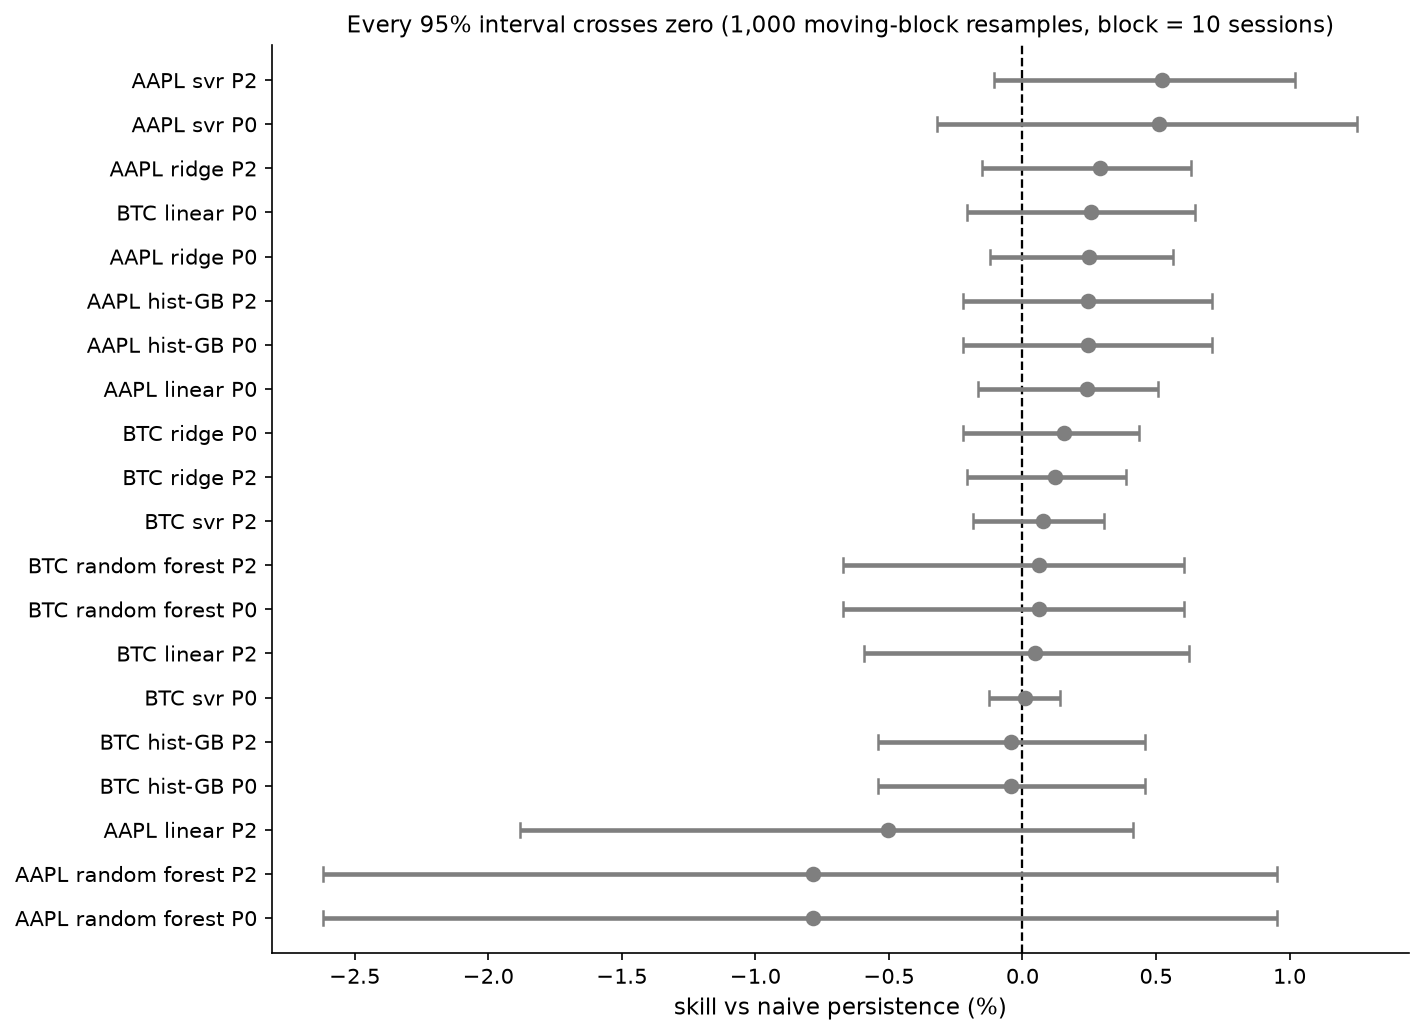

In [52]:
from int4096.evaluation import figures
from int4096.evaluation.analysis import write_summary
from int4096.paths import FIGURES

analysis = json.loads(write_summary().read_text(encoding="utf-8"))
print("intervals containing zero:", analysis["summary"]["ci_includes_zero"], "of", analysis["summary"]["runs"])
for asset, values in analysis["return_autocorrelation"].items():
    print(f"{asset}: lag-1 autocorrelation of daily returns {values['lag1_autocorrelation']:+.4f}")
forest = figures.plot_skill_intervals(analysis["skill_intervals"], block_length=10,
                                      n_resamples=1000, figure_root=FIGURES)
display(Image(filename=str(forest)))

## 9. Experimental neural networks (MLP and LSTM)

An add-on outside the main comparison: predict whether the next close is higher
than today's. Each network is trained for at most 300 epochs and stops after 20
epochs without improvement on a hold-out taken from the end of the training
block. A GPU is used if one is present; a CPU also works but is slower.
Neural-network results can differ slightly between devices.

In [53]:
RUN_NEURAL = True
if RUN_NEURAL and importlib.util.find_spec("torch") is not None:
    run("scripts/supplementary_direction_test.py")
    latest = sorted((WORKSPACE / "experiments/supplementary/direction_test").glob("*/results.json"))[-1]
    neural = json.loads(latest.read_text(encoding="utf-8"))
    submitted = PUBLISHED["neural"]
    print("submitted results used:", submitted.get("device"))
    display(pd.DataFrame([
        {"asset": a, "network": k, "accuracy submitted": submitted.get(f"{a}|{k}"),
         "accuracy now": neural["results"][a][k]["accuracy_ensemble"],
         "majority rule": neural["results"][a][k]["majority_accuracy"],
         "95% interval vs majority": neural["results"][a][k]["diff_vs_majority_ci95"]}
        for a in ("AAPL", "BTC") for k in ("mlp", "lstm")]))
else:
    print("Neural experiment skipped (RUN_NEURAL is False or PyTorch is not installed).")

device: cpu (cpu)
AAPL mlp  acc=0.561 (seeds 0.496-0.574) majority=0.557 diff CI=[-0.078, 0.0861] cfg={'hidden': 64, 'dropout': 0.2, 'lr': 0.001} 4.8s
AAPL lstm acc=0.529 (seeds 0.459-0.553) majority=0.557 diff CI=[-0.1107, 0.0616] cfg={'hidden': 32, 'dropout': 0.2, 'lr': 0.001} 10.1s
BTC mlp  acc=0.500 (seeds 0.461-0.517) majority=0.480 diff CI=[-0.0447, 0.0698] cfg={'hidden': 32, 'dropout': 0.2, 'lr': 0.003} 9.3s
BTC lstm acc=0.514 (seeds 0.489-0.525) majority=0.480 diff CI=[-0.014, 0.081] cfg={'hidden': 32, 'dropout': 0.2, 'lr': 0.001} 19.3s
wrote experiments/supplementary/direction_test/2026-11-27T160014Z

submitted results used: cuda, torch 2.9.1+cu130


,asset,network,accuracy submitted,accuracy now,majority rule,95% interval vs majority
0,AAPL,mlp,0.5410,0.5615,0.5574,"[-0.078, 0.0861]"
1,AAPL,lstm,0.5205,0.5287,0.5574,"[-0.1107, 0.0616]"
2,BTC,mlp,0.5000,0.5000,0.4804,"[-0.0447, 0.0698]"
3,BTC,lstm,0.5335,0.5140,0.4804,"[-0.014, 0.081]"


## 10. The report's tables and figures

Generated from the experiments run above, with the same code that builds the
report. Table and figure numbers follow the report. Figure 3 in the report is a
hand-drawn pipeline diagram, so it has no data to regenerate.

In [54]:
run("scripts/build_latex_assets.py")

runs used: 20
  deliverables/report/latex/generated/results_table.tex
  deliverables/report/latex/generated/ablation_table.tex
  deliverables/report/latex/generated/dataset_table.tex
  deliverables/report/latex/generated/splits_table.tex
  deliverables/report/latex/generated/numbers.tex
  deliverables/report/latex/figures/fig01_coverage_and_splits.png
  deliverables/report/latex/figures/fig02_asset_characteristics.png
  deliverables/report/latex/figures/fig04_model_vs_naive.png
  deliverables/report/latex/figures/fig06_ablation_delta.png
  deliverables/report/latex/figures/fig05_validation_mae_by_lane.png
  deliverables/report/latex/figures/fig03_observed_vs_predicted_2026-11-27T155918Z_aapl_svr_P2_seed42_validation.png
  deliverables/report/latex/figures/fig07_feature_importance_aapl.png



In [55]:
results = []
for path in sorted(RUNS_ROOT.glob("*/*/metrics.json")):
    blob = json.loads(path.read_text(encoding="utf-8"))
    results.append({"asset": blob["asset"], "model": figures.model_label(blob["model_id"]),
                    "variant": blob["preprocess_variant"],
                    "MAE": blob["metrics"]["validation_mae"], "RMSE": blob["metrics"]["validation_rmse"],
                    "R2": blob["metrics"]["validation_r2"],
                    "skill %": blob["metrics"]["validation_skill_mae"] * 100})
results = pd.DataFrame(results)

print("Table 3. Preprocessing ablation: validation MAE, P0 (unscaled) against P2 (standardised)")
ablation = results.pivot_table(index=["asset", "model"], columns="variant", values="MAE")
ablation["change %"] = (ablation["P2"] / ablation["P0"] - 1) * 100
display(ablation.round(4))

print("Table 4. Validation performance, standardised inputs (P2). Dollar errors are not comparable across assets.")
table4 = results[results["variant"] == "P2"].set_index(["asset", "model"])[["MAE", "RMSE", "R2", "skill %"]].sort_index()
display(table4.round(4))

Table 3. Preprocessing ablation: validation MAE, P0 (unscaled) against P2 (standardised)


variant                         P0         P2  change %
asset model                                            
AAPL  Gradient boosting     2.8985     2.8985    0.0000
      Linear baseline       2.8986     2.9202    0.7446
      Random forest         2.9283     2.9283    0.0000
      Ridge                 2.8983     2.8971   -0.0414
      SVR (RBF)             2.8907     2.8904   -0.0101
BTC   Gradient boosting  1605.0165  1605.0165    0.0000
      Linear baseline    1600.2052  1603.5868    0.2113
      Random forest      1603.3734  1603.3734    0.0000
      Ridge              1601.8739  1602.3879    0.0321
      SVR (RBF)          1604.1858  1603.1314   -0.0657

Table 4. Validation performance, standardised inputs (P2). Dollar errors are not comparable across assets.


MAE       RMSE      R2  skill %
asset model                                                   
AAPL  Gradient boosting     2.8985     4.3560  0.9556   0.2465
      Linear baseline       2.9202     4.3660  0.9554  -0.5024
      Random forest         2.9283     4.3712  0.9553  -0.7824
      Ridge                 2.8971     4.3572  0.9556   0.2917
      SVR (RBF)             2.8904     4.3562  0.9556   0.5220
BTC   Gradient boosting  1605.0165  2204.9106  0.9614  -0.0417
      Linear baseline    1603.5868  2211.2390  0.9612   0.0475
      Random forest      1603.3734  2208.0377  0.9613   0.0608
      Ridge              1602.3879  2205.9612  0.9614   0.1222
      SVR (RBF)          1603.1314  2203.8476  0.9614   0.0758

Figure 1
Price history per asset with the frozen 60/20/20 chronological split. Shaded regions mark train (blue), validation (green) and sealed test (red); the unshaded start is the feature warm-up. The two assets have different calendars and are plotted separately, never aligned by row.


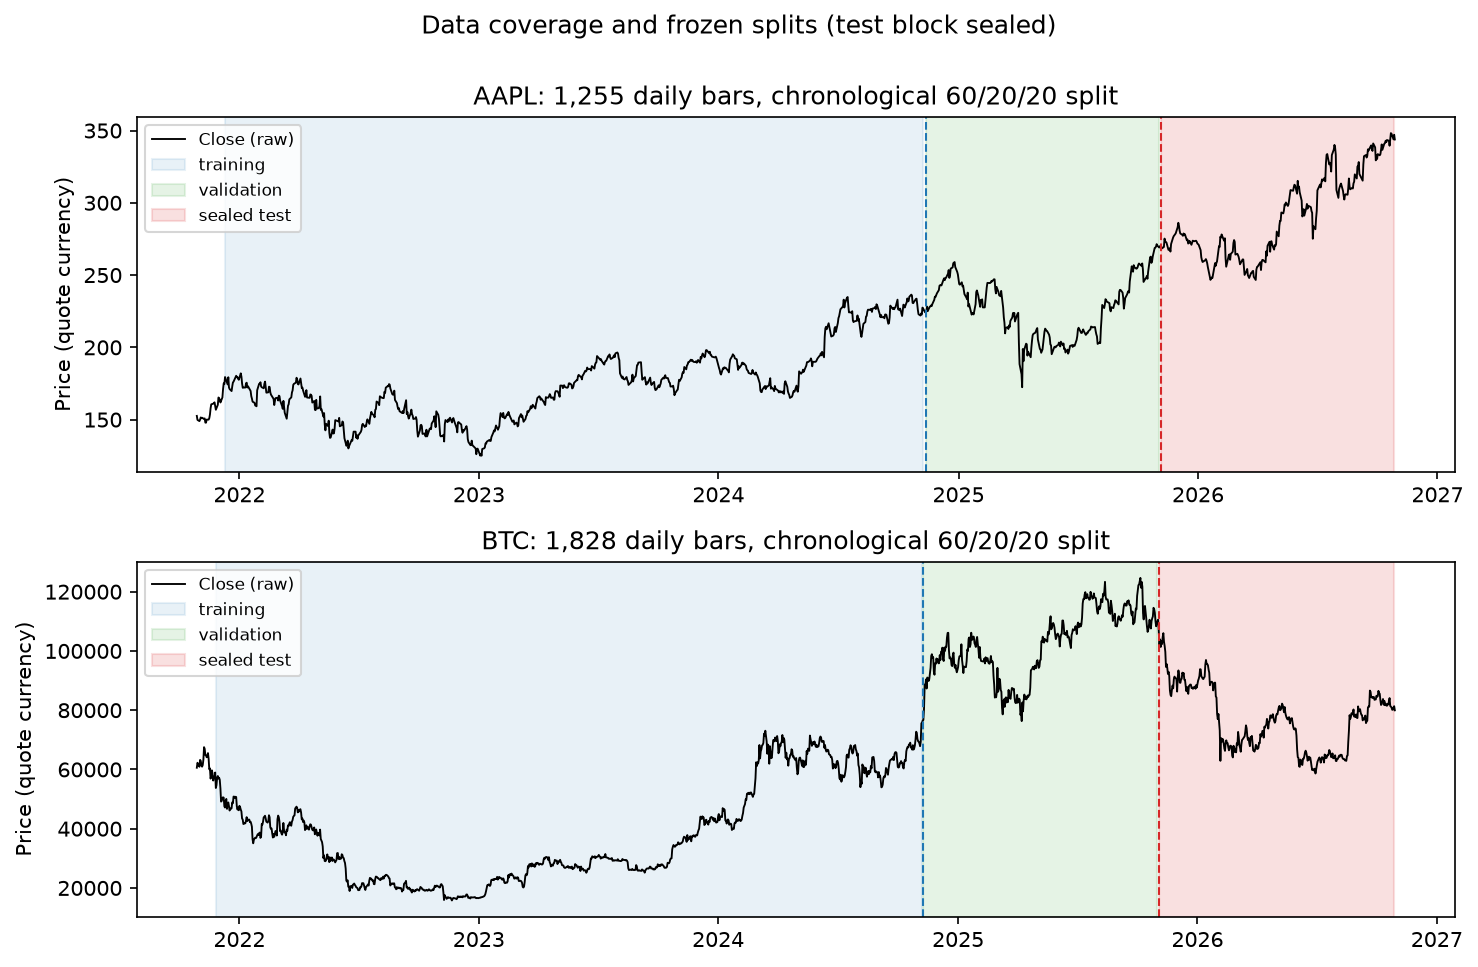

Figure 2
Left: each price series rebased to 100 at its own first observation, so the two cannot be confused with a shared price axis. Right: trailing 30-session realised volatility annualised by sqrt(252). BTC's volatility level and its regime shifts are the mechanical reason a fixed-capacity model faces a harder problem there. Calendars differ (BTC includes weekends), so the x axes are calendar time, not row index.


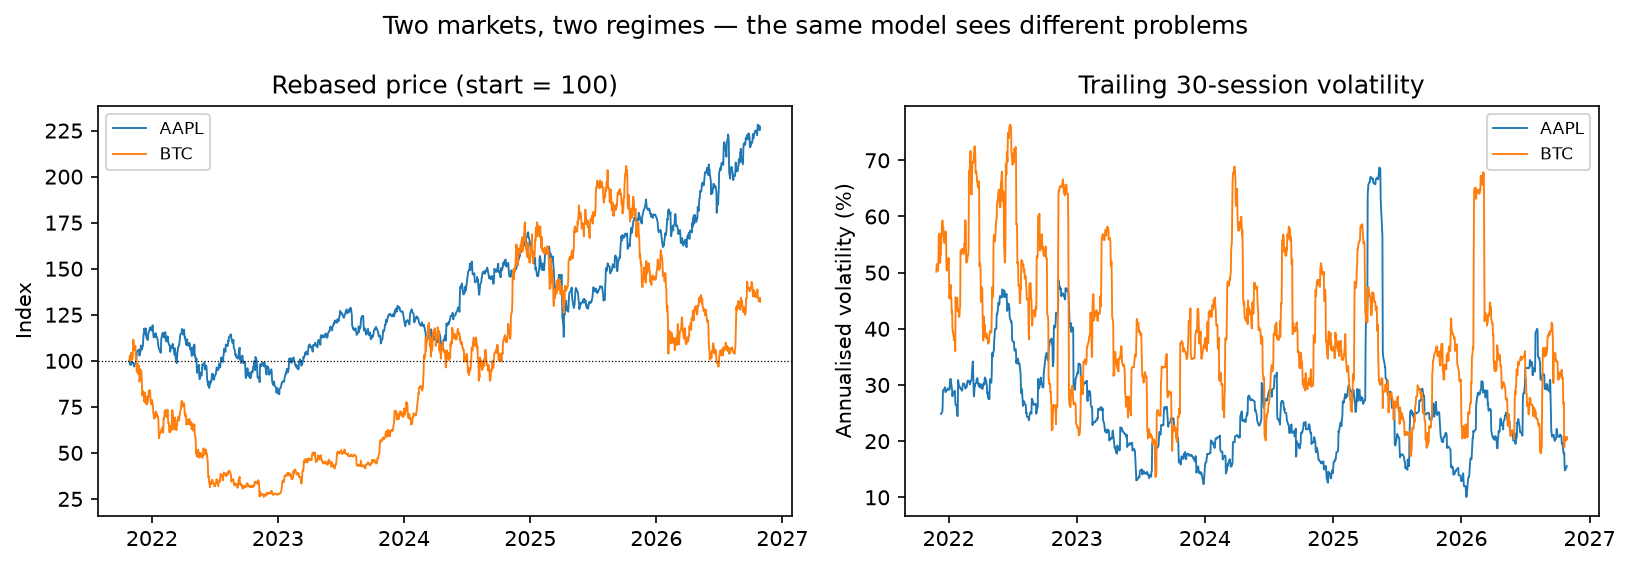

Figure 4
Relative change in validation MAE for each preprocessing variant compared with P0, holding model and asset fixed. Positive (red) means worse. Only matched cells are plotted; unmatched cells are absent rather than imputed.


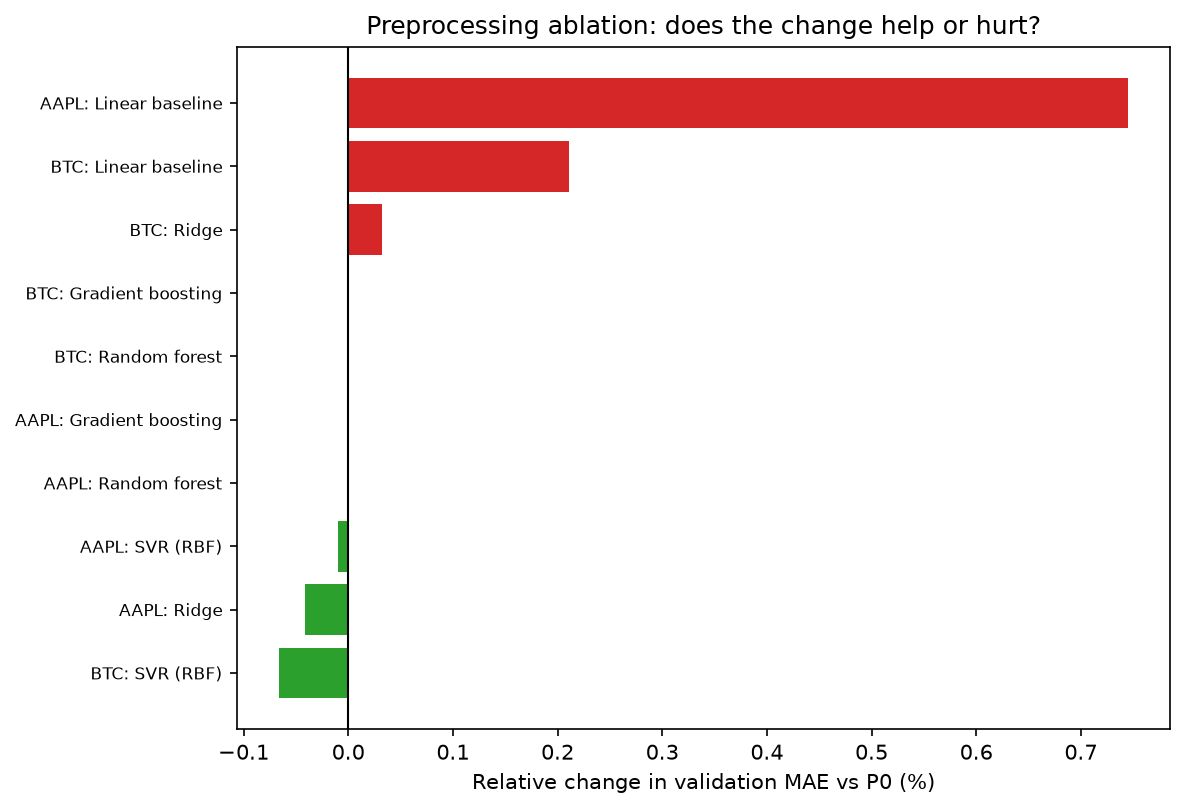

Figure 5
Validation skill score relative to naive persistence, per asset, standardised inputs (P2). Bars to the left of zero indicate a model worse than repeating the current price. Dollar errors are not compared across assets; only the unitless skill score is.


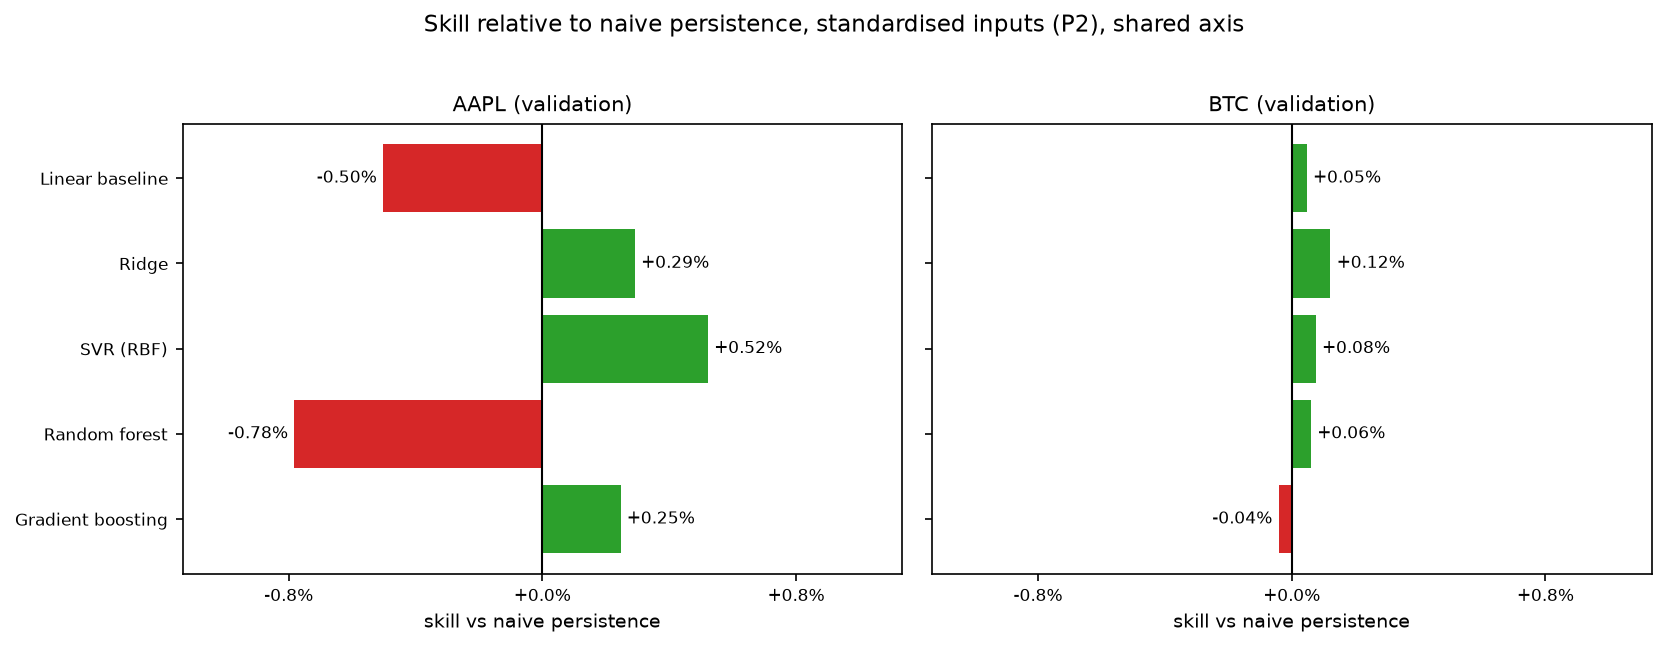

Figure 6
Observed next-close price against the model forecast and the naive persistence forecast, with the signed forecast error below. The naive line overlaps the observed series closely because next-close prediction is close to a random walk.


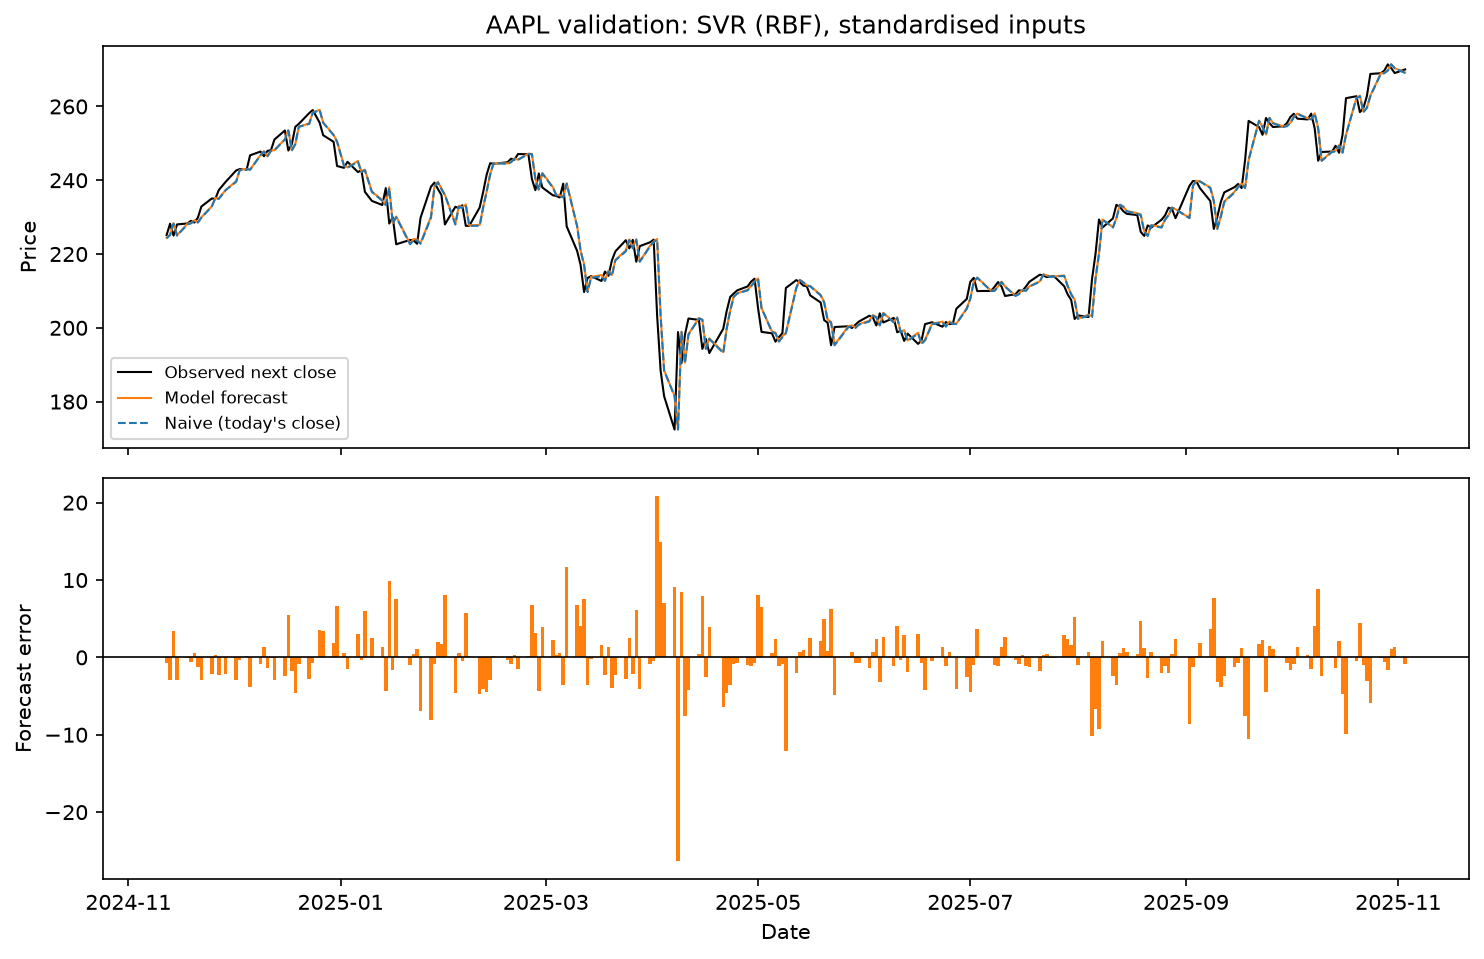

Figure 7
Permutation importance for the fitted Ridge on the AAPL validation block (n=244). Each bar is the increase in validation MAE when that single feature is randomly shuffled, so larger means the model relies on it more. Values near zero or negative mean the feature does not help on unseen data. This describes the fitted model, not a causal mechanism in the market.


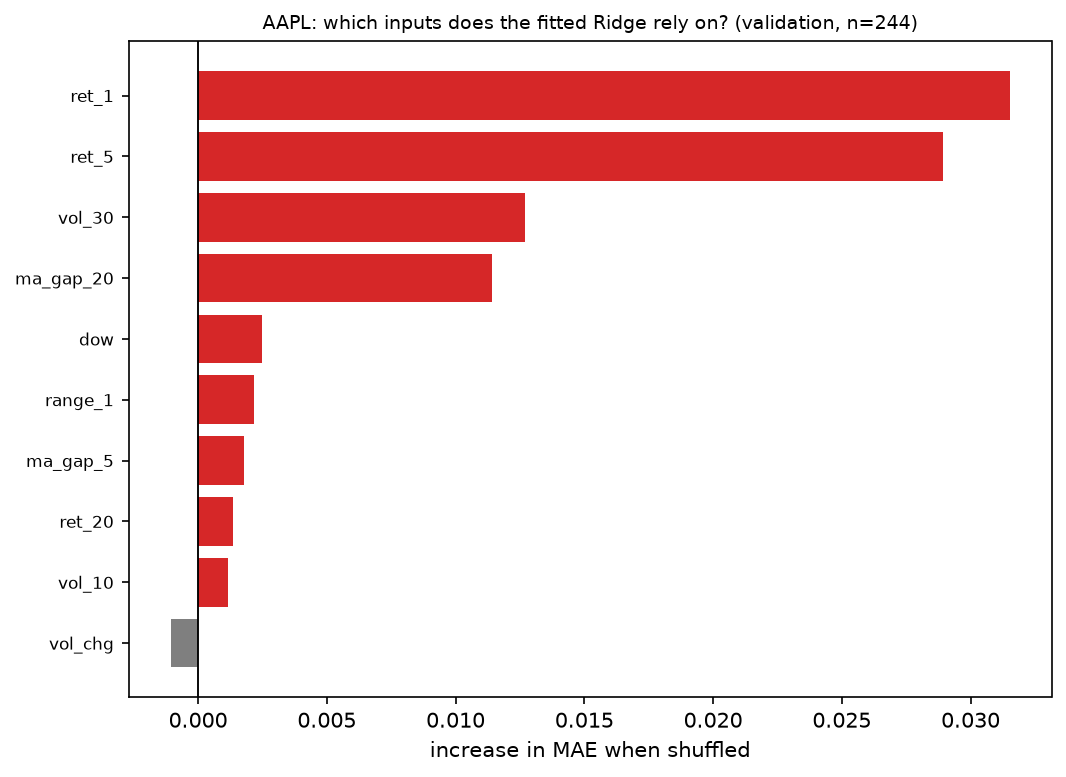

In [56]:
report_figures = WORKSPACE / "deliverables/report/latex/figures"
for number, pattern in [(1, "fig01_*.png"), (2, "fig02_*.png"), (4, "fig06_*.png"),
                        (5, "fig04_*.png"), (6, "fig03_*.png"), (7, "fig07_*.png")]:
    path = sorted(report_figures.glob(pattern))[-1]
    print(f"Figure {number}")
    print(path.with_suffix(".caption.txt").read_text(encoding="utf-8").split("run_ids:")[0].strip())
    display(Image(filename=str(path)))

## 11. Examples for learners

### A. Why R² can look impressive without any skill

R² compares the error with the spread of prices around their average. Prices
wander far from their average, so even "copy today's close" scores a high R².

In [57]:
from int4096.evaluation.baselines import naive_persistence
from int4096.evaluation.metrics import evaluate_predictions

for asset in ("AAPL", "BTC"):
    prepared = prepare_dataset(asset, protocol)
    X, y, split = prepared["X"], prepared["y"], prepared["split"]
    dates = X.index[split.validation_start:split.validation_end]
    today = prepared["frame"].loc[dates, protocol.label_field].to_numpy()
    truth = today + y.loc[dates].to_numpy()
    naive = naive_persistence(today)
    scores = evaluate_predictions(truth, naive, naive, reference=today)
    print(f"{asset}: copying today's close gives R2 = {scores['r2']:.4f}, skill = 0")

AAPL: copying today's close gives R2 = 0.9555, skill = 0
BTC: copying today's close gives R2 = 0.9614, skill = 0


### B. Spot the leakage

One feature below is **deliberately leaky**. Find it before running the cell.

In [58]:
close = frames["AAPL"]["close"]
leaky = pd.DataFrame({"ret_1": close.pct_change(1, fill_method=None),
                      "tomorrow_ret": close.pct_change(1, fill_method=None).shift(-1)})
target = close.pct_change(1, fill_method=None).shift(-1)
for column in leaky:
    print(f"{column:14s} correlation with the next-day return: {leaky[column].corr(target):+.3f}")
print("'tomorrow_ret' uses shift(-1): it is the answer itself and is unknown at prediction time.")

ret_1          correlation with the next-day return: +0.021
tomorrow_ret   correlation with the next-day return: +1.000
'tomorrow_ret' uses shift(-1): it is the answer itself and is unknown at prediction time.


## 12. Limitations and responsible interpretation

1. **Not investment advice.** Forecast error says nothing about profit, risk or
   trading costs.
2. **One-day horizon.** Copying today's close is a strong forecast here.
3. **Two assets, one period.** The conclusions may not hold elsewhere.
4. **BTC is one exchange's USDT price**, not a global USD index.
5. **Raw close prices** are used; dividends are ignored.
6. **No learner study** was run; the lesson is a designed resource.
7. **The test block is sealed.** All numbers here are validation numbers.

The last cell packs the tables, figures and run records into one zip file.

In [59]:
bundle = WORKSPACE / "bundle"
for folder in ("experiments", "deliverables"):
    shutil.copytree(WORKSPACE / folder, bundle / folder, dirs_exist_ok=True)
archive = shutil.make_archive(str(WORKSPACE / "int4096_outputs"), "zip", bundle)
shutil.rmtree(bundle)
print("outputs:", Path(archive).relative_to(WORKSPACE.parent))
print(int4096.DISCLAIMER)

outputs: int4096_workspace_20261127_235900/int4096_outputs.zip
Educational, historical and non-advisory. Forecast error metrics do not imply profitability and past performance does not predict future returns.
